# Complete Basler / DLC pupil analysis: Blocks A, B and C

Run top to bottom. Part I preserves camera TTL QC, conditional AVI timestamp reconstruction, pupil joining, and oddball TTL extraction. Part II adds all proposed block analyses, quality checks, trial-history analyses, behavioral comparisons, multi-mouse statistics and an optional overlap model.

**Inputs:** matching analog TDMS, DLC PCHIP Excel, and a trial-label CSV or oddball event JSON. A trial log is essential: TTLs alone do not identify warm-up or all four control sequences. Optional behavior CSV and lick/reward channels support state analyses. Settings are all in the next cell. Camera timestamp CSVs are generated, not required inputs.

**Important definitions:** pre-train baseline is mean PD from −1 to −0.2 s before each train. Subtract that same baseline for all within-trial measurements. Standards are a reference condition, not a replacement baseline. Primary outcome is mean signed ΔPD 1–2 s after stimulus 3. Secondary outcomes include early/late windows and 1–1.5 s after train end. These overlapping outcomes are not independent tests. The post-train outcome retains the pre-train baseline and is not re-zeroed at train end.

**Limits:** timing inherits the conditional end-anchor assumption. Block C always-last comparisons confound context with elapsed time/history. Responses include subsequent stimuli and the gray transition. Pupil change is not a specific measurement of prediction error or locus-coeruleus activity. No animal-level inference is made from frames or repeated trials alone.

Dependencies: numpy, pandas, matplotlib, scipy, openpyxl, nptdms, IPython. If missing, install in the active kernel with `%pip install numpy pandas matplotlib scipy openpyxl nptdms ipython`. Packages are not installed automatically. No private data or calculated results are embedded in this notebook.


**Updated comparisons:** each curve group now has a distinct colour. Sections II.8a–II.8b add raw/corrected PD, baseline-state, all-versus-reference standard, pre-divergence and local-reference diagnostics. Input paths and session settings from your uploaded notebook are retained. Saved cell outputs are cleared so rerunning generates results from the updated code.


**Revision:** Similar A/B figures are paired after each analysis section. Baseline and local-reference diagnostics precede outcome comparisons. New trajectory/slope and descriptive state-adjustment analyses complement the original amplitude analyses. All old outputs have been cleared: rerun top to bottom with the original input files.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nptdms import TdmsFile
from IPython.display import display

# REQUIRED: two source files for the SAME recording.
ANALOG_TDMS_PATH = Path(r"/Volumes/AG Poll 4/oddball2_exp_data/01_07_26/POL_0464/TDMS/session_17_33_50/2026-07-01_17-33-50_analog_log.tdms")
DLC_PCHIP_PATH = Path(r"/Volumes/AG Poll 4/oddball2_exp_data/01_07_26/POL_0464/DLC/session_17_33_50/pupil_interpolated_pchip.xlsx")
OUTPUT_DIR = Path(r"./basler_pupil_analysis")
DLC_SHEET = "Sheet1"
DLC_FRAME_COLUMN = "frame"
DLC_FRAME_BASE = 0 # 0 for DLC/Python; 1 only if Excel uses one-based frame numbers
TRUE_SAVED_VIDEO_FRAMES = None # enter verified decoded AVI count; None uses complete DLC row count

# Exact channel name, or (group, channel) tuple if names are duplicated.
# Examples from your wiring; verify these in section 1 for every session.
CAMERA_CHANNEL_NAME = "Dev1/ai4" # None: try saved config CameraOutTriggerLogDev/Port
TRAIN_CHANNEL = "Dev1/ai6"
DEVIANT_CHANNEL = "Dev1/ai1"
CONFIG_JSON_PATH = None # None: find device_config_backup.json beside the TDMS
DAQ_RATE_HZ_OVERRIDE = None # use only when TDMS wf_increment is absent
ASSUME_COMMON_CLOCK_IF_START_METADATA_MISSING = True # same analog acquisition task

# Camera TTL QC and conditional end anchoring.
EXPOSURE_US = 14428.0 # actual session exposure; affects estimated onset/midpoint only
THRESHOLD_V = 1.6
CAMERA_FPS_SEARCH_RANGE = (68.0, 71.0) # change for recordings run at 60 Hz etc.
MAX_BRACKET_GAP_S = 0.20
MAX_INTERVAL_RESIDUAL_MS = 0.45
MIN_EDGE_SPACING_S = 0.005
TERMINAL_FALL_POLICY = "keep" # keep or exclude; end anchor requires final original edge retained
ASSUME_STARTUP_ONLY_MISMATCH = True # user-selected conditional alignment model
BRIDGE_FINAL_AS_ONE_PERIOD = True # ONLY a final unresolved one-period candidate, after inspection
FINAL_BRIDGE_PERIOD_RATIO_RANGE = (0.8, 1.2) # not proof that a terminal edge is a saved exposure
RAW_VIEW_START_S = None
RAW_VIEW_DURATION_S = 0.35

# Pupil + oddball settings.
DIAMETER_COLUMN = "mean_diameter_px_interp_pchip" # default requested PCHIP column
TIME_COLUMN = "daq_exposure_end_s" # or estimated_exposure_mid_s
EVENT_THRESHOLD_V = 1.6
MIN_EVENT_EDGE_SPACING_S = 0.02
EVENTS_CSV = None # optional alternative with columns time_s,event_type (train_start or deviant)
SHOW_RANGE_S = None # e.g. (100,220) to zoom event overlays
PUPIL_ZOOM_YLIM = None # e.g. (25,55); None uses data percentiles for expanded view

# Part II: trial log. CSV recommended; JSON needs exact mappings below.
TRIAL_LOG_PATH = Path(r"/Volumes/AG Poll 4/oddball2_exp_data/01_07_26/POL_0464/TDMS/session_17_33_50/2026-07-01_17-33-50_oddball_events.json")
# CSV REQUIRED columns: block,sequence; OPTIONAL: phase,train_start_s,stimulus3_start_s,train_end_s.
# block must map to A/B/C; sequence is AAAA/AABA/BBBB/BBAB. One row per train.
JSON_RECORDS_KEY = "events" # None if JSON root is already a list of records
JSON_EVENT_FIELD = "event" # None if every record is a train record
JSON_TRAIN_EVENT_VALUES = ("train_start", "train") # edit to actual event names
LOG_FIELDS = {"block":"block", "sequence":"sequence", "phase":"phase",
              "train_start_s":"train_start_s", "stimulus3_start_s":"stimulus3_start_s", "train_end_s":"train_end_s"}
BLOCK_NAME_MAP = {"A":"A", "A-context":"A", "B":"B", "B-context":"B", "C":"C", "control":"C", "equiprobable":"C"}
PHASE_NAME_MAP = {"warmup":"warmup", "warm-up":"warmup", "fixed":"fixed", "initial_expectation":"fixed", "initial expectation":"fixed", "main":"main", "oddball":"main", "control":"control"}
# If log times are absent, explicit order matching assumes a complete recording/log with no missed train TTL.
ALLOW_ORDER_MATCH_WITHOUT_LOG_TIMES = True
NATIVE_TRAIN_MATCH_MODE = "count" # count: DAQ onset ordinal -> JSON oddball_trigger_index; optional "time"
AUTO_ALIGN_NATIVE_CONTROLLER_CLOCK = True # constant offset only; equal train counts + residual QC required
LOG_TRAIN_TIME_OFFSET_S = 0.0 # logged DAQ times + this offset; not used for order-only matching
LOG_TTL_MATCH_TOLERANCE_S = 0.10
STRICT_PROTOCOL_COUNTS = True # 200 A,200 B,240 C and the schematic's phase/identity counts
STIMULUS_DURATION_S = 0.400
ISI_S = 0.120
DEVIANT_TIMING_SOURCE = "ttl_if_available" # otherwise nominal/logged stimulus-3 onset
DEVIANT_TTL_MATCH_TOLERANCE_S = 0.08

MOUSE_ID = "mouse_01"
SESSION_ID = "session_01"
BASELINE_TRAIN_S = (-1.0, -0.2) # The start and end of the baseline window relative to train onset. Used for baseline pupil diameter and slope.
PRE3_WINDOW_S = (-0.25, -0.05) # local sensitivity reference; includes preceding stimulus/ISI
STIM3_WINDOWS = {"primary":(1.0,2.0), "early":(0.25,1.0), "late":(2.0,3.0)}
POSTEND_WINDOW_S = (1.0,1.5)
TRAIN_PLOT_WINDOW_S = (-1.0,4.0)
STIM3_PLOT_WINDOW_S = (-1.0,3.0)
ANALYSIS_GRID_STEP_S = 0.02
ANALYSIS_MAX_GAP_S = 0.025
MIN_BASELINE_COVERAGE = 0.8
MIN_METRIC_COVERAGE = 0.8
MAX_BASELINE_INTERPOLATED_FRACTION = 0.2
MAX_RESPONSE_INTERPOLATED_FRACTION = 0.2
PD_VALID_RANGE_PX = None # optional (lower,upper), based on video/QC; not physiological universal cutoffs
NEXT_TRAIN_GUARD_S = 0.05
EXCLUDE_FIRST_N_STANDARDS_AFTER_DEVIANT = 1
NEARBY_STANDARD_COUNT = 2

# Optional behavior: same DAQ time reference; CSV time_s,speed_cm_s.
BEHAVIOR_CSV = None
BEHAVIOR_MAX_GAP_S = 0.20
RUNNING_THRESHOLD_CM_S = 1.0 # editable operational threshold
MAX_QUIET_PRE_SPEED_CM_S = 1.0
LICK_CHANNEL = None # exact TDMS name or (group,channel), optional
REWARD_CHANNEL = None
BEHAVIOR_EVENT_THRESHOLD_V = 1.6
BEHAVIOR_EVENT_MIN_SPACING_S = 0.02
# Multi-session inference uses other exported trial_metrics.csv files with mouse_id/session_id.
OTHER_SESSION_METRICS = [] # e.g. [Path("mouse2/session1/trial_metrics.csv")]
MIN_MICE_FOR_TEST = 5
BOOTSTRAP_REPETITIONS = 2000
RANDOM_SEED = 19

# Optional continuous-time overlap model. Enable after assessing overlap and behavior QC.
RUN_OVERLAP_MODEL = False
OVERLAP_GRID_STEP_S = 0.05
OVERLAP_KERNEL_PEAK_S = 1.5 # illustrative fixed kernel; check sensitivity, not fitted physiology
OVERLAP_KERNEL_DURATION_S = 8.0
OVERLAP_RIDGE_ALPHA = 10.0

# Trajectory sensitivity: fixed windows chosen before inspecting condition results.
PRE3_SLOPE_WINDOW_S = (-0.50, -0.05)
POST3_SLOPE_WINDOWS = {'early': (0.25, 1.0), 'primary': (1.0, 2.0)}
GROUP_SIMILAR_PLOTS = True # A/B counterparts appear side by side after each section


## I.1. Validate frame indices and inspect channels

Use the actual saved AVI count if available. When that setting is None, the notebook assumes the DLC file contains one row for every saved video frame. It requires unique, consecutive indices starting at the configured base. Count agreement does not independently establish timing accuracy. Files from different sessions must not be mixed.


In [2]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for path in (ANALOG_TDMS_PATH, DLC_PCHIP_PATH):
    if not path.is_file():raise FileNotFoundError(f"Set the correct input path: {path}")
dlc = pd.read_excel(DLC_PCHIP_PATH, sheet_name=DLC_SHEET)
for column in (DLC_FRAME_COLUMN, DIAMETER_COLUMN):
    if column not in dlc:raise ValueError(f"Missing DLC column: {column}")
indices = pd.to_numeric(dlc[DLC_FRAME_COLUMN], errors="raise").to_numpy(float)
if not np.isfinite(indices).all() or not np.all(indices==np.rint(indices)):
    raise ValueError("DLC frame indices must be finite integers.")
dlc["avi_frame_0based"] = indices.astype(np.int64)-DLC_FRAME_BASE
dlc = dlc.sort_values("avi_frame_0based").reset_index(drop=True)
if not np.array_equal(dlc.avi_frame_0based.to_numpy(), np.arange(len(dlc))):
    raise ValueError("DLC indices are missing/duplicated or use a different index base.")
if TRUE_SAVED_VIDEO_FRAMES is None:
    TRUE_SAVED_VIDEO_FRAMES = len(dlc)
    video_count_source = "assumed complete DLC row count"
else:
    if int(TRUE_SAVED_VIDEO_FRAMES)!=TRUE_SAVED_VIDEO_FRAMES or TRUE_SAVED_VIDEO_FRAMES<=0:
        raise ValueError("Saved video count must be a positive integer.")
    TRUE_SAVED_VIDEO_FRAMES = int(TRUE_SAVED_VIDEO_FRAMES)
    video_count_source = "user-provided saved AVI count"
if len(dlc)!=TRUE_SAVED_VIDEO_FRAMES:
    raise ValueError("DLC rows disagree with saved AVI count; resolve before alignment.")
print(f"Pupil rows / saved frames: {TRUE_SAVED_VIDEO_FRAMES:,} ({video_count_source})")
with TdmsFile.open(str(ANALOG_TDMS_PATH)) as tdms:
    inventory = [{"group":g.name,"channel":ch.name,"samples":len(ch),
                  "wf_increment":ch.properties.get("wf_increment"),
                  "wf_start_time":ch.properties.get("wf_start_time"),
                  "wf_start_offset":ch.properties.get("wf_start_offset",0)}
                 for g in tdms.groups() for ch in g.channels()]
display(pd.DataFrame(inventory))
pd.DataFrame(inventory).to_csv(OUTPUT_DIR/"tdms_channel_inventory.csv",index=False)


Pupil rows / saved frames: 187,032 (assumed complete DLC row count)


,group,channel,samples,wf_increment,wf_start_time,wf_start_offset
0,analog_log_task,Dev1/ai3,27066368,0.0001,2026-07-01 15:33:51.209156,0.0
1,analog_log_task,Dev1/ai7,27066368,0.0001,2026-07-01 15:33:51.209168,0.0
2,analog_log_task,Dev1/ai0,27066368,0.0001,2026-07-01 15:33:51.209181,0.0
3,analog_log_task,Dev1/ai5,27066368,0.0001,2026-07-01 15:33:51.209193,0.0
4,analog_log_task,Dev1/ai4,27066368,0.0001,2026-07-01 15:33:51.209206,0.0
5,analog_log_task,Dev1/ai2,27066368,0.0001,2026-07-01 15:33:51.209218,0.0
6,analog_log_task,Dev1/ai1,27066368,0.0001,2026-07-01 15:33:51.209231,0.0
7,analog_log_task,Dev1/ai6,27066368,0.0001,2026-07-01 15:33:51.209243,0.0


## I.2. Load camera signal and clock

Camera time is `wf_start_offset + sample_index × wf_increment`, relative to the camera channel's `wf_start_time`. All event channels later use this same reference. Only the selected camera channel is loaded for reconstruction.


In [3]:
def resolve_channel(tdms, selector):
    if isinstance(selector,(tuple,list)) and len(selector)==2:
        return tdms[selector[0]][selector[1]]
    matches=[ch for g in tdms.groups() for ch in g.channels() if ch.name==selector]
    if len(matches)!=1:raise ValueError(f"Channel {selector!r}: {len(matches)} matches. Use exact name or (group,channel).")
    return matches[0]

def channel_dt(properties):
    dt=properties.get("wf_increment")
    if dt is None:
        if DAQ_RATE_HZ_OVERRIDE is None:raise ValueError("Missing wf_increment: set verified DAQ_RATE_HZ_OVERRIDE.")
        dt=1/float(DAQ_RATE_HZ_OVERRIDE)
    dt=float(dt)
    if not np.isfinite(dt) or dt<=0:raise ValueError("Invalid sample interval.")
    if DAQ_RATE_HZ_OVERRIDE is not None and not np.isclose(1/dt,DAQ_RATE_HZ_OVERRIDE,rtol=1e-6):
        raise ValueError("DAQ override disagrees with wf_increment.")
    return dt

def find_config_near(path):
    return next((p for p in path.parent.iterdir() if p.name.lower()=="device_config_backup.json"),None)
config_path=Path(CONFIG_JSON_PATH) if CONFIG_JSON_PATH else find_config_near(ANALOG_TDMS_PATH)
config={}
if config_path:
    config=json.loads(config_path.read_text(encoding="utf-8-sig"))
    config=config.get("device_config",config)
name=CAMERA_CHANNEL_NAME
if name is None:
    dev,port=config.get("CameraOutTriggerLogDev"),config.get("CameraOutTriggerLogPort")
    if dev is None or port is None:raise ValueError("Set CAMERA_CHANNEL_NAME from inventory.")
    name=f"Dev{dev}/ai{port}"
with TdmsFile.open(str(ANALOG_TDMS_PATH)) as tdms:
    channel=resolve_channel(tdms,name)
    camera_properties=dict(channel.properties)
    camera_signal=np.asarray(channel[:],dtype=np.float32)
sample_dt_s=channel_dt(camera_properties)
sample_offset_s=float(camera_properties.get("wf_start_offset",0) or 0)
camera_start_time=camera_properties.get("wf_start_time")
DAQ_FS_HZ=1/sample_dt_s
N_SAMPLES=len(camera_signal)
if N_SAMPLES<2 or not np.isfinite(camera_signal).all():raise ValueError("Camera signal empty or non-finite.")
print(f"Camera={name}, samples={N_SAMPLES:,}, DAQ={DAQ_FS_HZ:.3f} Hz, offset={sample_offset_s:g} s")
print(f"Camera range: {camera_signal.min():.3f} to {camera_signal.max():.3f} V; exposure={EXPOSURE_US:g} us")
figure_counter=0
def save_and_show():
    global figure_counter
    figure_counter+=1
    plt.gcf().savefig(OUTPUT_DIR/f"figure_{figure_counter:02d}.png",dpi=150,bbox_inches="tight")
    plt.show()
    plt.close(plt.gcf())


Camera=Dev1/ai4, samples=27,066,368, DAQ=10000.000 Hz, offset=0 s
Camera range: -0.018 to 3.308 V; exposure=14428 us


## I.3. Inspect raw TTL and original falling edges

The overview uses per-bin minima and maxima so narrow LOW dips remain visible. The short raw view draws every sample. The edge raster below includes all original threshold crossings; no interpolation occurs in this section. LOW samples shorter than a DAQ tick cannot be reliably counted. Check the channel polarity and threshold from these plots.

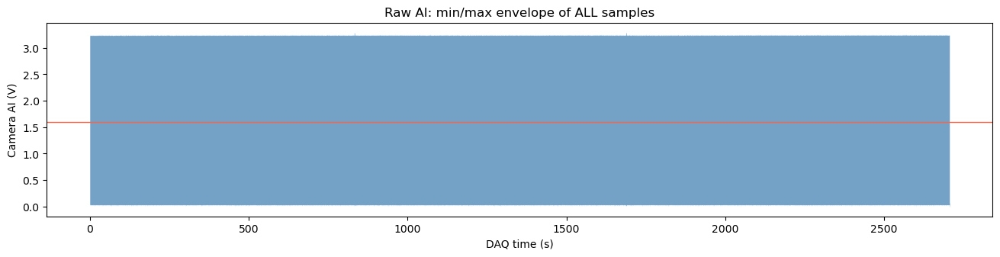

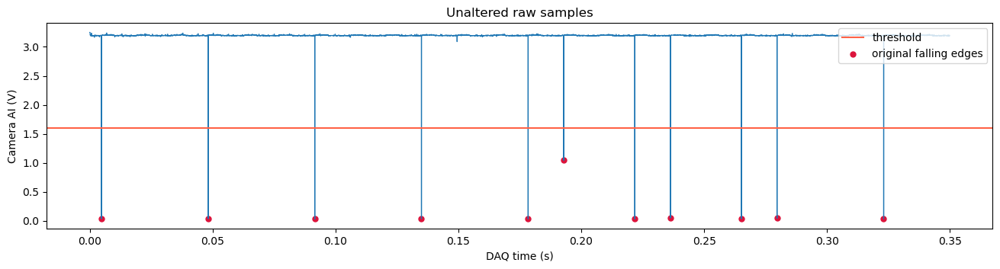

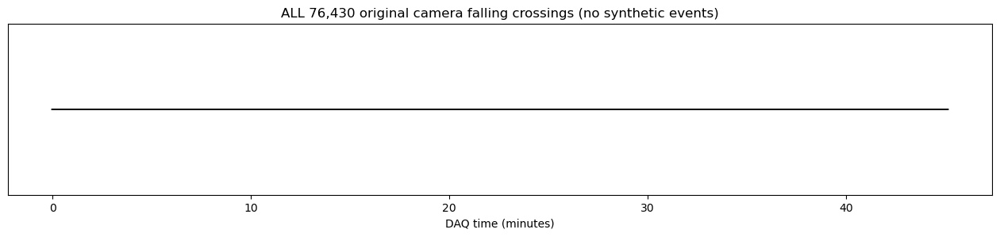

All original HIGH->LOW crossings: 76430 ; LOW->HIGH crossings: 76429


In [4]:
def plot_raw_overview(x, dt, offset=0., max_bins=30000):
    block = max(1, int(np.ceil(len(x)/max_bins)))
    starts = np.arange(0, len(x), block, dtype=np.int64)
    lo = np.minimum.reduceat(x, starts)
    hi = np.maximum.reduceat(x, starts)
    t = offset + starts * dt
    fig, ax = plt.subplots(figsize=(16, 3.3))
    ax.fill_between(t, lo, hi, color="steelblue", alpha=.75, linewidth=0)
    ax.axhline(THRESHOLD_V, color="tomato", lw=1)
    ax.set(xlabel="DAQ time (s)", ylabel="Camera AI (V)", title="Raw AI: min/max envelope of ALL samples")
    save_and_show()

plot_raw_overview(camera_signal, sample_dt_s, sample_offset_s)
raw_high = camera_signal >= THRESHOLD_V
all_falls = np.flatnonzero(raw_high[:-1] & ~raw_high[1:]) + 1
all_rises = np.flatnonzero(~raw_high[:-1] & raw_high[1:]) + 1
if not len(all_falls):
    raise ValueError("No original HIGH->LOW edges; inspect the threshold, wiring and polarity")
all_times = sample_offset_s + all_falls*sample_dt_s
if RAW_VIEW_START_S is None:
    RAW_VIEW_START_S = max(sample_offset_s, all_times[0] - .04)
start = max(0, int((RAW_VIEW_START_S-sample_offset_s)/sample_dt_s))
end = min(N_SAMPLES, start+int(RAW_VIEW_DURATION_S/sample_dt_s))
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.step(sample_offset_s+np.arange(start,end)*sample_dt_s, camera_signal[start:end], where="post", lw=.85)
ax.axhline(THRESHOLD_V, color="tomato", label="threshold")
ax.scatter(all_times[(all_falls>=start)&(all_falls<end)],
           camera_signal[all_falls[(all_falls>=start)&(all_falls<end)]],
           color="crimson", s=25, label="original falling edges")
ax.set(xlabel="DAQ time (s)", ylabel="Camera AI (V)", title="Unaltered raw samples")
ax.legend(loc="upper right")
save_and_show()
fig, ax = plt.subplots(figsize=(16, 2.8))
ax.scatter(all_times/60, np.ones(len(all_times)), marker="|", s=1.5,
           rasterized=True, color="black")
ax.set(xlabel="DAQ time (minutes)", yticks=[], title=f"ALL {len(all_times):,} original camera falling crossings (no synthetic events)")
save_and_show()
print("All original HIGH->LOW crossings:",len(all_falls),"; LOW->HIGH crossings:",len(all_rises))

## I.4. Estimate period and classify gaps

Reject clear duplicate edges (too close to be successive frames). A sustained LOW at the end does not prove the final falling edge is a stop artifact. Set `TERMINAL_FALL_POLICY` to `"keep"` for a verified frame, or `"exclude"` for a suspected stop edge. All original edges stay in the CSV. Estimate the period using intervals close to one camera cycle, then refine from short integer-multiple intervals. A good interval has an integer period count and a small residual. Long or non-integer gaps remain **unresolved**. Inspect their raw waveform before choosing a different tolerance.

Estimated from accepted observed intervals: 69.11924 fps; period=14.46775 ms
Observed crossings: 76,430; kept: 76,430; accepted intervals: 76,428; unresolved intervals: 1


,before_sample,after_sample,before_fall_s,after_fall_s,interval_ms,candidate_periods,residual_ms,status
76428,27058506,27058646,2705.8506,2705.8646,14.0,1,-0.467753,unresolved


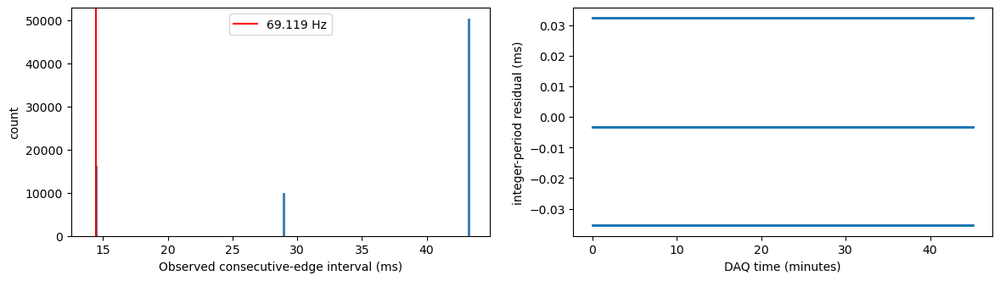

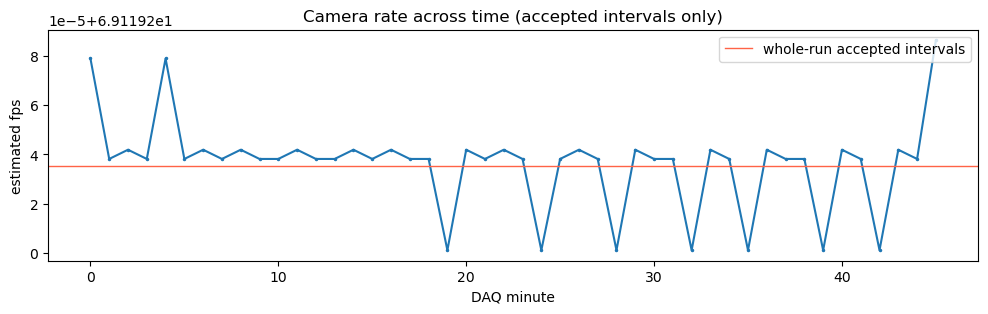

,minute,elapsed_s,periods,fps
0,0,60.0122,4148,69.119279
1,1,59.9833,4146,69.119238
2,2,60.0267,4149,69.119242
3,3,59.9833,4146,69.119238
4,4,60.0122,4148,69.119279


In [5]:
if TERMINAL_FALL_POLICY not in ("keep", "exclude"):
    raise ValueError("TERMINAL_FALL_POLICY must be keep or exclude")
terminal_sustained_low_candidate = bool(
    len(all_falls) and not raw_high[-1] and
    (N_SAMPLES-1-all_falls[-1])*sample_dt_s > .10
)
terminal_stop = terminal_sustained_low_candidate and TERMINAL_FALL_POLICY == "exclude"
candidate_falls = all_falls[:-1] if terminal_stop else all_falls.copy()
kept = []
duplicates = []
for idx in candidate_falls:
    if kept and (idx-kept[-1])*sample_dt_s < MIN_EDGE_SPACING_S:
        duplicates.append(int(idx))
    else:
        kept.append(int(idx))
falls = np.asarray(kept,dtype=np.int64)
t = sample_offset_s + falls*sample_dt_s
if len(t) < 20:
    raise ValueError("Fewer than 20 plausible camera edges; check the raw trace")
dt_obs = np.diff(t)
low, high = 1/CAMERA_FPS_SEARCH_RANGE[1], 1/CAMERA_FPS_SEARCH_RANGE[0]
one_cycle = dt_obs[(dt_obs >= low-.0007) & (dt_obs <= high+.0007)]
if len(one_cycle) < 20:
    raise ValueError("Too few isolated one-frame intervals to measure a period")
period_s = float(np.median(one_cycle))
for _ in range(4):
    multiples = np.maximum(1,np.rint(dt_obs/period_s).astype(np.int64))
    ok = ((dt_obs <= MAX_BRACKET_GAP_S) &
          (np.abs(dt_obs-multiples*period_s) <= MAX_INTERVAL_RESIDUAL_MS/1000))
    if ok.sum()<20:
        raise ValueError("Too few integer-compatible intervals; inspect raw data and settings")
    # Weighted mean cancels quantization error at the interval boundaries.
    period_s = float(dt_obs[ok].sum()/multiples[ok].sum())

multiples = np.maximum(1,np.rint(dt_obs/period_s).astype(np.int64))
residual_ms = 1000*(dt_obs-multiples*period_s)
valid = ((dt_obs <= MAX_BRACKET_GAP_S) &
         (np.abs(residual_ms) <= MAX_INTERVAL_RESIDUAL_MS))
interval_qc = pd.DataFrame({
    "before_sample":falls[:-1],"after_sample":falls[1:],
    "before_fall_s":t[:-1],"after_fall_s":t[1:],
    "interval_ms":dt_obs*1000,"candidate_periods":multiples,
    "residual_ms":residual_ms,"status":np.where(valid,"bracketed_integer_gap","unresolved"),
})
edge_qc = pd.DataFrame({"sample":all_falls,"fall_s":all_times})
edge_qc["classification"] = "observed_kept"
if terminal_sustained_low_candidate:
    edge_qc.loc[edge_qc["sample"].eq(all_falls[-1]),"classification"] = (
        "terminal_excluded" if terminal_stop else "terminal_retained_observed"
    )
if duplicates:
    edge_qc.loc[edge_qc["sample"].isin(duplicates),"classification"]="too_close_candidate"
print(f"Estimated from accepted observed intervals: {1/period_s:.5f} fps; period={period_s*1000:.5f} ms")
print(f"Observed crossings: {len(all_falls):,}; kept: {len(falls):,}; "
      f"accepted intervals: {valid.sum():,}; unresolved intervals: {(~valid).sum():,}")
display(interval_qc.loc[~valid].sort_values("interval_ms",ascending=False).head(20))
fig,axs=plt.subplots(1,2,figsize=(14,3.5))
axs[0].hist(dt_obs[(dt_obs<.15)]*1000,bins=150,color="steelblue")
axs[0].axvline(period_s*1000,color="red",label=f"{1/period_s:.3f} Hz")
axs[0].set(xlabel="Observed consecutive-edge interval (ms)",ylabel="count")
axs[0].legend()
axs[1].scatter(t[:-1][valid]/60,residual_ms[valid],s=.2,rasterized=True)
axs[1].set(xlabel="DAQ time (minutes)",ylabel="integer-period residual (ms)")
save_and_show()
# Check whether the inferred period is stable throughout the run.
minute_bin = np.floor(t[:-1][valid]/60).astype(int)
rate_by_minute = (pd.DataFrame({"minute":minute_bin,
                                "elapsed_s":dt_obs[valid],
                                "periods":multiples[valid]})
                  .groupby("minute",as_index=False).sum())
rate_by_minute["fps"] = rate_by_minute.periods/rate_by_minute.elapsed_s
fig,ax=plt.subplots(figsize=(12,3))
ax.plot(rate_by_minute.minute,rate_by_minute.fps,".-",ms=3)
ax.axhline(1/period_s,color="tomato",lw=1,label="whole-run accepted intervals")
ax.set(xlabel="DAQ minute",ylabel="estimated fps",title="Camera rate across time (accepted intervals only)")
ax.legend(loc="upper right");save_and_show()
display(rate_by_minute.head())


## I.5. Reconstruct supported exposure slots

Each accepted interval with `m` periods receives `m-1` synthetic falling edges between its two measured endpoints. The synthetic time is evenly interpolated within that interval; the observed endpoints retain their sampled times. The corresponding estimated exposure **start** is the falling edge minus the configured exposure time, and has additional uncertainty. Intervals that fail QC split the train into independent segments; no frames are created there or outside the first/last observation.

`segment_id` and `slot_within_segment` are **exposure slot coordinates**, not AVI frame numbers. Never use an inferred event as an observed TTL.

In [6]:
records=[]
segment=0
slot=0
records.append((segment,slot,float(t[0]),"observed",int(falls[0]),np.nan,np.nan,0))
for i,(m,good) in enumerate(zip(multiples,valid)):
    if good:
        left,right=t[i],t[i+1]
        for j in range(1,int(m)):
            slot+=1
            records.append((segment,slot,float(left+(right-left)*j/m),
                            "synthetic_between_observed",-1,int(falls[i]),int(falls[i+1]),i))
        slot+=1
    else:
        segment+=1
        slot=0
    records.append((segment,slot,float(t[i+1]),"observed",int(falls[i+1]),np.nan,np.nan,i+1))
frames=pd.DataFrame(records,columns=["segment_id","slot_within_segment","fall_time_s",
                                     "source","observed_fall_sample","left_observed_sample",
                                     "right_observed_sample","interval_index"])
frames["estimated_exposure_start_s"] = frames.fall_time_s - EXPOSURE_US/1e6
frames["nearest_daq_sample"] = np.rint((frames.fall_time_s-sample_offset_s)/sample_dt_s).astype(np.int64)
frames["nearest_daq_sample"] = frames.nearest_daq_sample.clip(0,N_SAMPLES-1)
print("Measured edges retained:",int(frames.source.eq("observed").sum()))
print("Synthetic candidates inside accepted gaps:",int(frames.source.eq("synthetic_between_observed").sum()))
print("Unresolved intervals:",int((~valid).sum()),"; independent segments:",segment+1)
print("Saved video frames:",TRUE_SAVED_VIDEO_FRAMES)
print("Compatible exposure slots *inside accepted segments*:",len(frames),
      "(excludes unknowable slots within unresolved intervals and at DAQ boundaries)")
if len(frames) != TRUE_SAVED_VIDEO_FRAMES or (~valid).any():
    print("QC NOTE: Unconditional AVI numbering is not established. Camera exposures, DAQ coverage, "
          "and saved video frames differ; missing video frame locations are unknown.")
display(frames.source.value_counts().rename("rows").to_frame())

Measured edges retained: 76430
Synthetic candidates inside accepted gaps: 110598
Unresolved intervals: 1 ; independent segments: 2
Saved video frames: 187032
Compatible exposure slots *inside accepted segments*: 187028 (excludes unknowable slots within unresolved intervals and at DAQ boundaries)
QC NOTE: Unconditional AVI numbering is not established. Camera exposures, DAQ coverage, and saved video frames differ; missing video frame locations are unknown.


,rows
source,
synthetic_between_observed,110598
observed,76430


## I.6. Visualize reconstruction and final edge

The first panel remains original edges only; the second overlays synthetic candidate events. Select a window containing a detected gap or change `WINDOW_START_S` manually. This figure shows falling edges, which are exposure ends for `ExposureActive`.

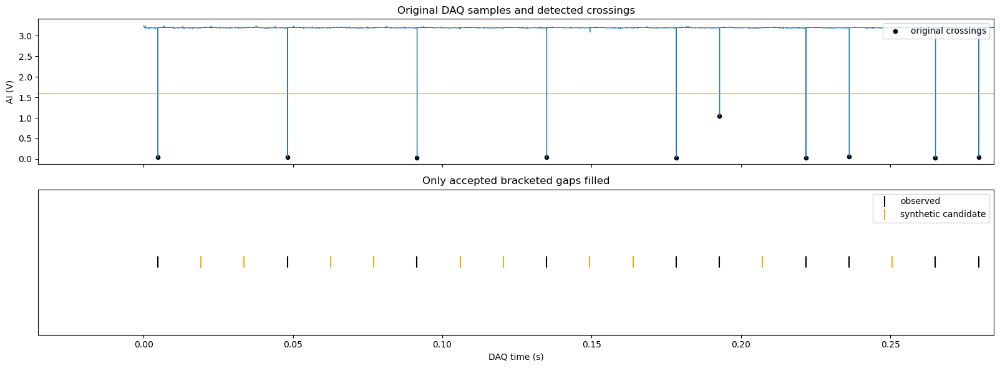

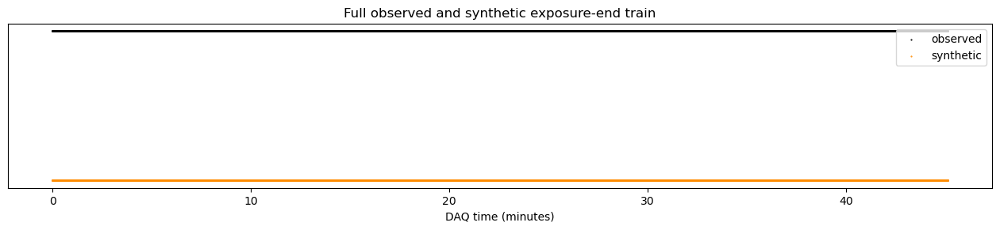

First retained fall: 0.004700 s
Last retained fall:  2705.864600 s
Final original fall: 2705.864600 s
Final fall retained: True (policy=keep)
DAQ began HIGH:      True
DAQ ends 0.7721 s after the final fall


In [7]:
gap_rows=interval_qc.loc[valid & (multiples>1)]
WINDOW_START_S = float(gap_rows.before_fall_s.iloc[0]-.04) if len(gap_rows) else float(t[0]-.03)
WINDOW_DURATION_S=.32
left,right=WINDOW_START_S,WINDOW_START_S+WINDOW_DURATION_S
sel_raw=(all_times>=left)&(all_times<=right)
sel_obs=frames.source.eq("observed")&frames.fall_time_s.between(left,right)
sel_syn=frames.source.eq("synthetic_between_observed")&frames.fall_time_s.between(left,right)
start=max(0,int((left-sample_offset_s)/sample_dt_s));end=min(N_SAMPLES,int((right-sample_offset_s)/sample_dt_s))
fig,axs=plt.subplots(2,1,figsize=(16,6),sharex=True)
axs[0].step(sample_offset_s+np.arange(start,end)*sample_dt_s,camera_signal[start:end],where="post",lw=.8)
axs[0].scatter(all_times[sel_raw],camera_signal[all_falls[sel_raw]],color="black",s=20,label="original crossings")
axs[0].axhline(THRESHOLD_V,color="tomato",lw=.8)
axs[0].set(ylabel="AI (V)",title="Original DAQ samples and detected crossings")
axs[0].legend(loc="upper right")
axs[1].scatter(frames.loc[sel_obs,"fall_time_s"],np.ones(sel_obs.sum()),marker="|",s=180,
               color="black",label="observed")
axs[1].scatter(frames.loc[sel_syn,"fall_time_s"],np.ones(sel_syn.sum()),marker="|",s=180,
               color="orange",label="synthetic candidate")
axs[1].set(xlim=(left,right),ylim=(.8,1.2),yticks=[],xlabel="DAQ time (s)",
           title="Only accepted bracketed gaps filled")
axs[1].legend(loc="upper right")
plt.tight_layout();save_and_show()
fig,ax=plt.subplots(figsize=(16,2.7))
ax.scatter(frames.loc[frames.source.eq("observed"),"fall_time_s"]/60,
           np.ones(frames.source.eq("observed").sum()),s=.3,rasterized=True,color="black",label="observed")
ax.scatter(frames.loc[frames.source.ne("observed"),"fall_time_s"]/60,
           np.ones(frames.source.ne("observed").sum())*.9,s=.3,rasterized=True,color="darkorange",label="synthetic")
ax.set(xlabel="DAQ time (minutes)",yticks=[],title="Full observed and synthetic exposure-end train")
ax.legend(loc="upper right");save_and_show()
last_kept_s = float(frames.fall_time_s.iloc[-1])
last_original_s = float(all_times[-1])
gap_periods = (last_original_s - last_kept_s) / period_s

print(f"First retained fall: {frames.fall_time_s.iloc[0]:.6f} s")
print(f"Last retained fall:  {last_kept_s:.6f} s")
print(f"Final original fall: {last_original_s:.6f} s")
print(f"Final fall retained: {not terminal_stop} (policy={TERMINAL_FALL_POLICY})")
if terminal_stop:
    print(f"Gap to excluded fall: {gap_periods:.4f} camera periods")
print(f"DAQ began HIGH:      {bool(raw_high[0])}")
print(f"DAQ ends {sample_offset_s + (N_SAMPLES-1)*sample_dt_s - last_original_s:.4f} s "
      "after the final fall")

## I.7. Save TTL QC

These outputs retain all original edges, excluded duplicates, interval residuals, segments, and inferred exposure slots. They are saved even if the following mapping step stops because of internal unresolved intervals. Inspect the raw final signal before using the terminal one-period override. QC acceptance alone does not verify saved AVI frame identity.


In [8]:
edge_qc.to_csv(OUTPUT_DIR/"camera_all_original_falls.csv",index=False)
interval_qc.to_csv(OUTPUT_DIR/"camera_observed_interval_qc.csv",index=False)
frames.to_csv(OUTPUT_DIR/"camera_supported_exposure_slots.csv",index=False)
ttl_summary={
 "tdms":str(ANALOG_TDMS_PATH),"channel":name,"daq_rate_hz":DAQ_FS_HZ,
 "threshold_v":THRESHOLD_V,"estimated_fps_from_accepted_intervals":1/period_s,
 "observed_original_crossings":len(all_falls),"retained_observed_falls":len(falls),
 "synthetic_candidates_inside_bracketed_gaps":int(frames.source.ne("observed").sum()),
 "unresolved_intervals":int((~valid).sum()),"independent_segments":int(segment+1),
 "exposure_slots_in_accepted_segments":len(frames),
 "saved_video_frames_user_input":TRUE_SAVED_VIDEO_FRAMES,
 "terminal_sustained_low_candidate":terminal_sustained_low_candidate,
 "terminal_fall_policy":TERMINAL_FALL_POLICY,
 "terminal_fall_retained":bool(not terminal_stop),
 "mapping_to_avi_frames_verified":False,
 "notes":"No boundary extrapolation. Retaining a terminal fall is a session-specific decision; older sessions may start the camera before DAQ. AVI fps is playback metadata."
}
(OUTPUT_DIR/"camera_ttl_summary.json").write_text(json.dumps(ttl_summary,indent=2),encoding="utf-8")
print("Saved outputs to",OUTPUT_DIR)
display(pd.Series(ttl_summary).to_frame("value"))

Saved outputs to basler_pupil_analysis


,value
tdms,/Volumes/AG Poll 4/oddball2_exp_data/01_07_26/...
channel,Dev1/ai4
daq_rate_hz,10000.0
threshold_v,1.6
estimated_fps_from_accepted_intervals,69.119236
observed_original_crossings,76430
retained_observed_falls,76430
synthetic_candidates_inside_bracketed_gaps,110598
unresolved_intervals,1
independent_segments,2


## I.8. Conditional AVI frame assignment

For M supported exposure slots and N saved frames, slot j (zero based) maps to one-based AVI frame `N−M+j+1`. Leading frames have blank times. This step handles no unresolved intervals, or one unresolved terminal gap that is explicitly assumed to be one period. Other unresolved gaps stop numbering instead of shifting every earlier AVI index silently. The terminal override remains flagged in the mapping and does not rewrite the original QC status.

An observed camera falling edge denotes exposure end. Estimated start and midpoint require the session's actual exposure duration. The sustained-LOW stop transition must be retained for this requested end-anchor model; excluding it requires a different independently justified saved-frame endpoint.


In [9]:
def make_end_anchor_mapping(slots, qc, saved_frames, final_original_time):
    if not ASSUME_STARTUP_ONLY_MISMATCH:
        raise ValueError("End anchoring requires the explicit startup-only mismatch model.")
    slots=slots.sort_values("fall_time_s").reset_index(drop=True).copy()
    if len(slots)==0 or not np.all(np.diff(slots.fall_time_s)>0):raise ValueError("Non-monotonic or empty slots.")
    if not np.isclose(slots.fall_time_s.iloc[-1],final_original_time,rtol=0,atol=1e-9):
        raise ValueError("Final original edge is excluded; cannot assume it anchors the last saved frame.")
    bad=qc.index[qc.status.eq("unresolved")].to_numpy()
    terminal_override=False
    if len(bad):
        if len(bad)!=1 or bad[0]!=len(qc)-1:
            raise ValueError("Internal unresolved gaps: TTL QC saved, but continuous AVI numbering is blocked.")
        row=qc.iloc[-1]
        ratio=(row.after_fall_s-row.before_fall_s)/period_s
        if not BRIDGE_FINAL_AS_ONE_PERIOD or int(row.candidate_periods)!=1:
            raise ValueError("Final unresolved gap needs the explicit one-period assumption after inspection.")
        lo,hi=FINAL_BRIDGE_PERIOD_RATIO_RANGE
        if not lo<=ratio<=hi:raise ValueError("Final gap outside allowed one-period candidate range.")
        if len(slots)<2 or not np.isclose(slots.fall_time_s.iloc[-2],row.before_fall_s,rtol=0,atol=1e-9):
            raise ValueError("Final interval endpoints do not match reconstructed slots.")
        terminal_override=True
        print(f"CONDITIONAL override: terminal gap {1000*(row.after_fall_s-row.before_fall_s):.4f} ms = {ratio:.4f} periods.")
    leading=int(saved_frames)-len(slots)
    if leading<0:raise ValueError("More slots than AVI frames: startup-only mismatch cannot explain counts.")
    slots["avi_frame_0based"]=np.arange(leading,int(saved_frames))
    slots["daq_exposure_end_s"]=slots.fall_time_s
    slots["estimated_exposure_start_s"]=slots.fall_time_s-EXPOSURE_US/1e6
    slots["estimated_exposure_mid_s"]=slots.fall_time_s-EXPOSURE_US/2e6
    slots["timestamp_basis"]=np.where(slots.source.eq("observed"),"observed_falling_edge","interpolated_falling_edge")
    slots.loc[len(slots)-1,"timestamp_basis"]="terminal_observed_edge_assumed_last_saved_frame"
    slots["terminal_gap_override"]=False
    slots.loc[len(slots)-1,"terminal_gap_override"]=terminal_override
    full=pd.DataFrame({"avi_frame_0based":np.arange(int(saved_frames))}).merge(slots,on="avi_frame_0based",how="left",validate="one_to_one")
    full.insert(0,"avi_frame_1based",full.avi_frame_0based+1)
    full.loc[full.daq_exposure_end_s.isna(),"timestamp_basis"]="no_DAQ_coverage_no_timestamp_assigned"
    full["mapping_status"]="conditional_end_anchor_startup_only_mismatch"
    return full,leading,terminal_override

camera_mapping,leading_frames,terminal_override=make_end_anchor_mapping(frames,interval_qc,TRUE_SAVED_VIDEO_FRAMES,float(all_times[-1]))
camera_mapping.to_csv(OUTPUT_DIR/"camera_AVI_to_DAQ_end_anchored.csv",index=False)
print(f"AVI frames={len(camera_mapping):,}; timed slots={len(frames):,}; leading untimed frames={leading_frames}")
display(camera_mapping[["avi_frame_1based","avi_frame_0based","daq_exposure_end_s","timestamp_basis"]].iloc[np.r_[0:min(6,len(camera_mapping)),max(6,len(camera_mapping)-3):len(camera_mapping)]])


CONDITIONAL override: terminal gap 14.0000 ms = 0.9677 periods.
AVI frames=187,032; timed slots=187,028; leading untimed frames=4


,avi_frame_1based,avi_frame_0based,daq_exposure_end_s,timestamp_basis
0,1,0,NaN,no_DAQ_coverage_no_timestamp_assigned
1,2,1,NaN,no_DAQ_coverage_no_timestamp_assigned
2,3,2,NaN,no_DAQ_coverage_no_timestamp_assigned
3,4,3,NaN,no_DAQ_coverage_no_timestamp_assigned
4,5,4,0.004700,observed_falling_edge
5,6,5,0.019167,interpolated_falling_edge
187029,187030,187029,2705.836150,interpolated_falling_edge
187030,187031,187030,2705.850600,observed_falling_edge
187031,187032,187031,2705.864600,terminal_observed_edge_assumed_last_saved_frame


## I.9. Join DLC PCHIP to frame times

No separate camera CSV path or manually combined pupil CSV is needed. Original pupil columns, PCHIP values, interpolation flags and camera timing provenance are retained. Remaining missing PCHIP values stay missing. Event resampling introduces no new interpolation across gaps larger than the configured limit.


In [ ]:
pupil=dlc.merge(camera_mapping,on="avi_frame_0based",how="left",validate="one_to_one")
pupil["frame"]=pupil.avi_frame_0based
pupil[DIAMETER_COLUMN]=pd.to_numeric(pupil[DIAMETER_COLUMN],errors="raise")
PCHIP_FLAG_AVAILABLE = "was_interpolated" in pupil
if PCHIP_FLAG_AVAILABLE:
    flag=pupil["was_interpolated"].astype("string").str.lower().str.strip()
    if not flag.dropna().isin(["true","false","1","0","1.0","0.0"]).all():raise ValueError("Unrecognized was_interpolated flag.")
    pupil["was_interpolated"]=flag.isin(["true","1","1.0"])
else:
    pupil["was_interpolated"]=False
    print("No interpolation flag supplied; filled-value fraction cannot be measured.")
if TIME_COLUMN not in pupil:raise ValueError("Unknown TIME_COLUMN.")
t=pupil[TIME_COLUMN].to_numpy(float)
y=pupil[DIAMETER_COLUMN].to_numpy(float) 
"""y variable is representing the 1D array containing all the PCHIP obtained PD values corresponding to the time points"""
if not np.isfinite(y).any():raise ValueError("No finite pupil diameters.")
pupil.to_csv(OUTPUT_DIR/"pupil_with_DAQ_timestamps.csv",index=False)
print(f"Rows={len(pupil):,}; untimed={np.isnan(t).sum()}; missing selected diameter={np.isnan(y).sum()}; PCHIP-filled={pupil.was_interpolated.sum()}")


Rows=187,032; untimed=4; missing selected diameter=129; PCHIP-filled=19


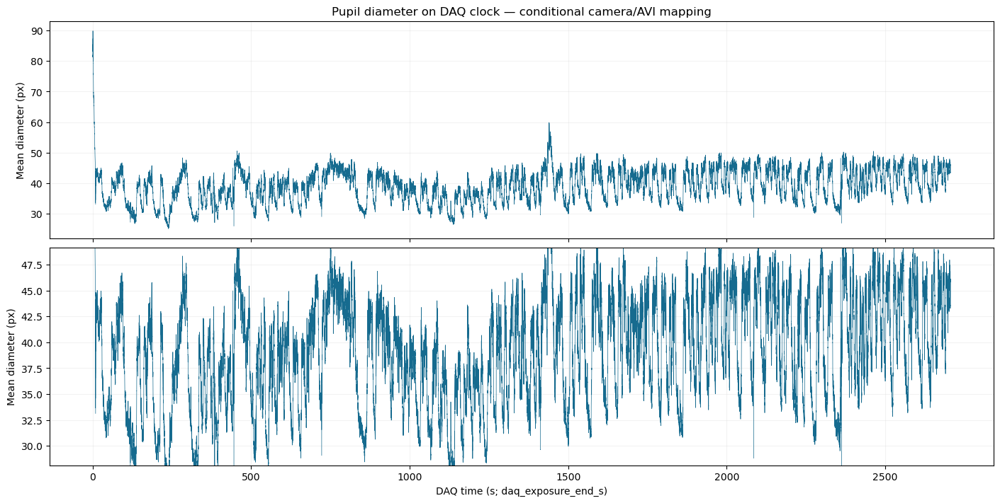

In [11]:
fig, axes = plt.subplots(2,1,figsize=(14,7),sharex=True,constrained_layout=True)
for ax in axes:
    ax.plot(t,y,lw=0.5,color="#166B8F")
    ax.set_ylabel("Mean diameter (px)")
    ax.grid(alpha=0.15)
axes[0].set_title("Pupil diameter on DAQ clock — conditional camera/AVI mapping")
axes[1].set_ylim(*(PUPIL_ZOOM_YLIM if PUPIL_ZOOM_YLIM is not None else np.nanpercentile(y,[1,99])))
axes[1].set_xlabel(f"DAQ time (s; {TIME_COLUMN})")
fig.savefig(OUTPUT_DIR / "pupil_DAQ_trace.png",dpi=160)
save_and_show()


## I.10. Extract train-start / deviant events

Verify that each selected output marks the intended event. The deviant pulse may mark stimulus onset or train onset depending on the controller. Channels use their own `wf_start_offset` and any absolute `wf_start_time` difference relative to the camera. Different sample intervals or channel lengths stop TDMS event analysis for inspection. Missing absolute clock metadata requires the explicit same-task common-clock assumption and is recorded. Events beginning HIGH have unknown onset and no synthetic event at zero is added.

Alternatively set EVENTS_CSV in settings to a CSV containing `time_s,event_type`, with times already on the camera DAQ clock and event types `train_start` and `deviant`.


In [12]:
def event_channel_offset(properties):
    start=properties.get("wf_start_time")
    offset=float(properties.get("wf_start_offset",0) or 0)
    if start is not None and camera_start_time is not None:
        offset+=float((np.datetime64(start)-np.datetime64(camera_start_time))/np.timedelta64(1,"s"))
        return offset,"absolute_start_and_channel_offset"
    if not ASSUME_COMMON_CLOCK_IF_START_METADATA_MISSING:
        raise ValueError("Missing absolute start metadata: verify common acquisition task first.")
    print("NOTE: assuming common task clock because absolute start metadata is missing.")
    return offset,"assumed_common_task_start_with_channel_offset"

parts=[]
if EVENTS_CSV is not None:
    events=pd.read_csv(EVENTS_CSV)
    if not {"time_s","event_type"}.issubset(events.columns):raise ValueError("Event CSV needs time_s,event_type.")
    events["clock_basis"]="user_supplied_camera_DAQ_clock"
else:
    with TdmsFile.open(str(ANALOG_TDMS_PATH)) as tdms:
        for kind,selector in [("train_start",TRAIN_CHANNEL),("deviant",DEVIANT_CHANNEL)]:
            if selector is None:raise ValueError(f"Set {kind} channel from inventory or use EVENTS_CSV.")
            channel=resolve_channel(tdms,selector)
            dt=channel_dt(channel.properties)
            if not np.isclose(dt,sample_dt_s,rtol=1e-6):raise ValueError(f"{kind}: different sample rate than camera.")
            if len(channel)!=N_SAMPLES:raise ValueError(f"{kind}: channel length differs from camera; inspect clock coverage.")
            signal=np.asarray(channel[:],dtype=np.float32)
            if not np.isfinite(signal).all():raise ValueError(f"Non-finite {kind} trigger signal.")
            offset,basis=event_channel_offset(channel.properties)
            high=signal>=EVENT_THRESHOLD_V
            if high[0]:print(f"{kind} begins HIGH: onset outside coverage, no onset assigned.")
            rises=np.flatnonzero(~high[:-1]&high[1:])+1
            retained=[]
            for sample in rises:
                if not retained or (sample-retained[-1])*dt>=MIN_EVENT_EDGE_SPACING_S:retained.append(int(sample))
            parts.append(pd.DataFrame({"time_s":offset+np.asarray(retained,dtype=float)*dt,"event_type":kind,"sample":retained,"clock_basis":basis}))
            print(kind,"original rises",len(rises),"retained",len(retained))
            del signal,high
    events=pd.concat(parts,ignore_index=True)
events["time_s"]=pd.to_numeric(events.time_s,errors="raise")
if not np.isfinite(events.time_s).all():raise ValueError("Non-finite event time.")
if not events.event_type.isin(["train_start","deviant"]).all():raise ValueError("Unknown event type.")
if events.duplicated(["time_s","event_type"]).any():raise ValueError("Duplicate event time within event type.")
events=events.sort_values("time_s").reset_index(drop=True)
events.to_csv(OUTPUT_DIR/"oddball_events.csv",index=False)
display(events.groupby("event_type").size().rename("events").to_frame())


train_start original rises 640 retained 640
deviant original rises 192 retained 192


,events
event_type,
deviant,192
train_start,640


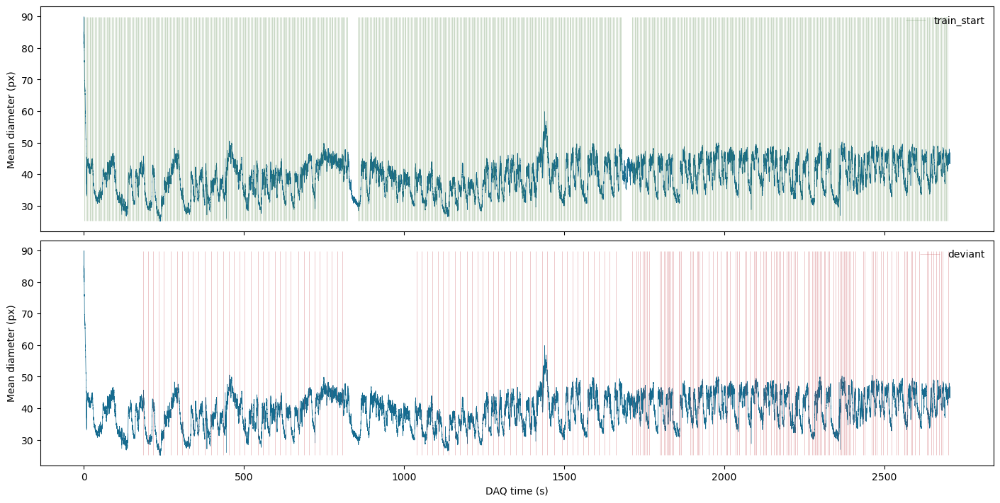

In [13]:
if len(events):
    fig,axes=plt.subplots(2,1,figsize=(14,7),sharex=True,constrained_layout=True)
    for ax,kind,color in zip(axes,["train_start","deviant"],["#538344","#C64D52"]):
        ax.plot(t,y,lw=0.5,color="#166B8F")
        times=events.loc[events.event_type.eq(kind),"time_s"].to_numpy()
        lo,hi=np.nanpercentile(y,[0,100])
        ax.vlines(times,lo,hi,color=color,alpha=0.35,lw=0.6,label=kind)
        ax.set_ylabel("Mean diameter (px)")
        ax.legend(frameon=False)
        if SHOW_RANGE_S is not None:ax.set_xlim(*SHOW_RANGE_S)
    axes[-1].set_xlabel("DAQ time (s)")
    fig.savefig(OUTPUT_DIR / "pupil_with_oddball_triggers.png",dpi=160)
    save_and_show()


## II.1. Load and verify trial labels

**Purpose:** identify A-context and B-context independently of chronological order, label warm-up/fixed/main phases, and retain all four Block C identities. No block is inferred from elapsed duration.

A canonical CSV has one row per train and columns `block,sequence`, with optional `phase,train_start_s,stimulus3_start_s,train_end_s`. A JSON may contain pause/reward records; edit `JSON_RECORDS_KEY`, `JSON_EVENT_FIELD`, `JSON_TRAIN_EVENT_VALUES` and `LOG_FIELDS` to extract its exact train records. The first records and fields are printed. Unknown names stop with an actionable message rather than being guessed.

With logged train times, match each log row one-to-one to the DAQ train TTL within tolerance after applying the explicit time offset. Without times, order matching requires equal counts and assumes neither source is missing a train. Incomplete recordings need explicit phase labels; phases are inferred from trial ordinal only for complete context blocks. Protocol-count checks may be disabled for an intentionally different protocol, but labels still need verification.


### Native oddball event JSON support
The uploaded controller format is detected automatically, including a top-level list. Only `event_type == "train"` records become trials. `block_label` identifies A/B/C, `sequence_name` identifies the sequence, and `is_warmup`, `is_initial_expectation`, `is_control` supply explicit phase labels. Do not use `context_label` for Block C (it is null), or `schedule_index` as the train index (it includes pauses). Original fields are retained. Pause and gap-reward records are exported separately in the controller recording clock and are NOT treated as DAQ-measured events.

**Default: count-based matching, as requested.** `NATIVE_TRAIN_MATCH_MODE="count"` pairs DAQ train-onset count n with JSON `oddball_trigger_index=n`, after filtering only train records. The loader requires indices 1…N with no duplicates/gaps and exactly N detected DAQ train onsets. `daq_train_onset_count_1based` and the original JSON index are saved side by side. JSON timestamps remain metadata; they do not label trials, shift DAQ times, or gate count matching. Do not use `schedule_index`, which includes pauses.

This assumes a complete recording and exactly one detected DAQ onset per train. A missing and an extra TTL can cancel in total count while shifting labels in between. Inspect the DAQ pulse train and block gaps; do not bypass count failures. DAQ onsets supply all train timestamps.

Optional `NATIVE_TRAIN_MATCH_MODE="time"` restores the controller-clock comparison: estimate one constant median offset (or set an independently known offset), export/plot residuals, and stop above tolerance. It is not used by the default count workflow.

This JSON does not contain measured stimulus-3 onset or train-end times. These retain their documented nominal timing fallback; main-deviant TTLs can replace corresponding stimulus-3 estimates when matched. Train-end estimates are not measured stimulus offsets.


In [14]:
def load_trial_records(path):
    if not Path(path).is_file():raise FileNotFoundError(f"Set TRIAL_LOG_PATH: {path}")
    if Path(path).suffix.lower()==".csv":return pd.read_csv(path)
    obj=json.loads(Path(path).read_text(encoding="utf-8-sig"))
    if isinstance(obj,list):rows=obj
    elif isinstance(obj,dict):
        print("JSON top-level keys:",list(obj))
        if JSON_RECORDS_KEY is None or JSON_RECORDS_KEY not in obj:
            raise ValueError("Set JSON_RECORDS_KEY to the list containing event records.")
        rows=obj[JSON_RECORDS_KEY]
    else:raise ValueError("JSON must contain a list of train/event records.")
    if not isinstance(rows,list):raise ValueError("Selected JSON object is not a list.")
    raw=pd.DataFrame(rows)
    print("Event fields:",list(raw));display(raw.head())
    # Native controller format: preserve all metadata and exclude non-train events explicitly.
    native={'event_type','block_label','sequence_name','train_start_time_from_recording_start'}
    if native.issubset(raw.columns):
        raw.loc[raw.event_type.ne('train')].to_csv(OUTPUT_DIR/'controller_nontrain_events_recording_clock.csv',index=False)
        raw=raw.loc[raw.event_type.eq('train')].copy()
        if raw.empty:raise ValueError('No native train records.')
        block_map={'Block1_AContextOddball':'A','Block2_BContextOddball':'B','Block3_EquiprobableControl':'C'}
        raw['block']=raw.block_label.map(block_map)
        if raw.block.isna().any():raise ValueError('Unknown native block label; update native block_map explicitly.')
        for flag in ['is_warmup','is_initial_expectation','is_control']:
            if flag not in raw or not raw[flag].map(lambda x:isinstance(x,(bool,np.bool_))).all():
                raise ValueError(f'Missing/nonboolean native phase flag: {flag}')
        if (raw[['is_warmup','is_initial_expectation','is_control']].astype(int).sum(axis=1)>1).any():
            raise ValueError('Conflicting native phase flags.')
        raw['phase']=np.select([raw.is_control.astype(bool),raw.is_warmup.astype(bool),raw.is_initial_expectation.astype(bool)],['control','warmup','fixed'],default='main')
        raw['sequence']=raw.sequence_name
        raw['controller_train_start_s']=pd.to_numeric(raw.train_start_time_from_recording_start,errors='raise' if NATIVE_TRAIN_MATCH_MODE=='time' else 'coerce')
        raw['train_start_s']=raw.controller_train_start_s
        if NATIVE_TRAIN_MATCH_MODE=='time' and (not np.isfinite(raw.train_start_s).all() or not np.all(np.diff(raw.train_start_s)>0)):
            raise ValueError('Native records must have finite increasing times.')
        if 'oddball_trigger_index' not in raw:raise ValueError('Native count matching requires oddball_trigger_index.')
        if 'oddball_trigger_index' in raw:
            raw=raw.sort_values('oddball_trigger_index').reset_index(drop=True)
            ix=pd.to_numeric(raw.oddball_trigger_index,errors='raise').to_numpy()
            if not np.array_equal(ix,np.arange(1,len(raw)+1)):
                raise ValueError('Native trigger indices are incomplete/nonconsecutive; resolve before ordinal matching.')
        raw['native_controller_clock']=True
        print('Native controller log recognized; phases read from flags, not inferred.')
        return raw
    if JSON_EVENT_FIELD is not None:
        if JSON_EVENT_FIELD not in raw:raise ValueError("Set JSON_EVENT_FIELD; use None only if all records are trains.")
        raw=raw.loc[raw[JSON_EVENT_FIELD].isin(JSON_TRAIN_EVENT_VALUES)].copy()
        if raw.empty:raise ValueError("No train records selected. Check JSON_TRAIN_EVENT_VALUES.")
    renamed={v:k for k,v in LOG_FIELDS.items() if v in raw}
    return raw.rename(columns=renamed)

trials=load_trial_records(TRIAL_LOG_PATH).reset_index(drop=True)
display(trials.head())
if not {"block","sequence"}.issubset(trials):raise ValueError("Map block and sequence fields using LOG_FIELDS, or supply canonical CSV.")
trials["block"]=trials.block.astype(str).str.strip().map(BLOCK_NAME_MAP)
trials["sequence"]=trials.sequence.astype(str).str.upper().str.replace(" ","",regex=False)
if trials.block.isna().any():raise ValueError("Unknown block names: extend BLOCK_NAME_MAP.")
if not trials.sequence.isin(["AAAA","AABA","BBBB","BBAB"]).all():raise ValueError("Unsupported sequence labels.")
train_times=events.loc[events.event_type.eq("train_start"),"time_s"].sort_values().to_numpy(float)
if len(train_times)!=len(trials):raise ValueError(f"Log trains={len(trials)}, DAQ train TTLs={len(train_times)}: resolve missing/extra records or pulses before analysis.")
native_count_match=('native_controller_clock' in trials and trials.native_controller_clock.all() and NATIVE_TRAIN_MATCH_MODE=='count')
if NATIVE_TRAIN_MATCH_MODE not in ('count','time'):raise ValueError('NATIVE_TRAIN_MATCH_MODE must be count or time.')
if native_count_match:
    trial_clock_basis='DAQ_onset_ordinal_matched_to_JSON_oddball_trigger_index'
    print('Count matching: DAQ onset n -> JSON oddball_trigger_index n. JSON times are not used.')
    print('Assumes every train produced exactly one detected DAQ pulse; equal totals alone cannot prove this.')
elif "train_start_s" in trials and trials.train_start_s.notna().all():
    raw_logged=pd.to_numeric(trials.train_start_s,errors="raise").to_numpy(float)
    native_clock='native_controller_clock' in trials and trials.native_controller_clock.all()
    clock_offset=float(LOG_TRAIN_TIME_OFFSET_S)
    if native_clock and AUTO_ALIGN_NATIVE_CONTROLLER_CLOCK:
        clock_offset=float(np.median(train_times-np.sort(raw_logged)))
        print(f'Controller-to-DAQ constant offset: {clock_offset:+.6f} s (DAQ = controller + offset).')
    logged=raw_logged+clock_offset
    if not np.isfinite(logged).all():raise ValueError("Non-finite log train times.")
    order=np.argsort(logged);trials=trials.iloc[order].reset_index(drop=True);logged=logged[order]
    if np.any(np.diff(logged)<=0):raise ValueError("Log train times duplicated/non-monotonic.")
    residual=logged-train_times
    clock_qc=pd.DataFrame({'controller_or_log_time_s':raw_logged[order], 'daq_train_time_s':train_times,
                           'offset_s':clock_offset,'residual_s':residual})
    clock_qc.to_csv(OUTPUT_DIR/'trial_clock_alignment_QC.csv',index=False)
    print('Maximum absolute train alignment residual (s):',float(np.max(np.abs(residual))))
    fig,ax=plt.subplots(figsize=(10,3));ax.plot(train_times,residual,'.',ms=3)
    ax.axhline(LOG_TTL_MATCH_TOLERANCE_S,color='r',ls='--');ax.axhline(-LOG_TTL_MATCH_TOLERANCE_S,color='r',ls='--')
    ax.set(xlabel='DAQ time (s)',ylabel='Log + offset minus TTL (s)',title='Clock alignment: inspect drift, jumps and outliers')
    fig.savefig(OUTPUT_DIR/'trial_clock_alignment_QC.png',dpi=150,bbox_inches='tight');plt.show()
    if np.max(np.abs(residual))>LOG_TTL_MATCH_TOLERANCE_S:
        raise ValueError('Log/TTL mismatch exceeds tolerance. Inspect trial_clock_alignment_QC.csv; do not increase tolerance blindly.')
    trials['controller_to_DAQ_offset_s']=clock_offset
    trial_clock_basis="native_controller_order_plus_constant_offset_validated_against_DAQ_TTL" if native_clock else "log_times_matched_to_DAQ_train_TTL"
    trials["log_TTL_error_s"]=logged-train_times
else:
    if "train_start_s" in trials and trials.train_start_s.notna().any():raise ValueError("Partially missing train times: do not mix order and time matching.")
    if not ALLOW_ORDER_MATCH_WITHOUT_LOG_TIMES:raise ValueError("No log DAQ train times: verify complete records and explicitly allow order matching.")
    trial_clock_basis="conditional_log_record_order_matched_to_DAQ_TTL"
    print("NOTE: order-only matching assumes a complete log and train TTL series.")
trials["train_start_s"]=train_times
trials["daq_train_onset_count_1based"]=np.arange(1,len(trials)+1)
trials["trial_id"]=np.arange(len(trials))
trials["block_trial"]=trials.groupby("block",sort=False).cumcount()+1
# Blocks must each form one continuous run, but A/B order may flip.
runs=trials.block.loc[trials.block.ne(trials.block.shift())].tolist()
if len(runs)!=len(set(runs)):raise ValueError("A block appears in multiple runs: inspect labels.")
if "phase" not in trials or trials.phase.isna().all():
    counts=trials.groupby("block").size().to_dict()
    if counts.get("A")!=200 or counts.get("B")!=200:raise ValueError("Incomplete context blocks need explicit phase labels.")
    trials["phase"]=np.where(trials.block.eq("C"),"control",np.where(trials.block_trial<=25,"warmup",np.where(trials.block_trial<=40,"fixed","main")))
    phase_basis="inferred_from_complete_schematic_trial_ordinals"
else:
    trials["phase"]=trials.phase.astype(str).str.strip().str.lower().map(PHASE_NAME_MAP)
    if trials.phase.isna().any():raise ValueError("Unknown/missing phase labels: extend PHASE_NAME_MAP.")
    phase_basis="log_phase_labels"
allowed={"A":{"AAAA","AABA"},"B":{"BBBB","BBAB"},"C":{"AAAA","AABA","BBBB","BBAB"}}
if any(seq not in allowed[b] for b,seq in zip(trials.block,trials.sequence)):raise ValueError("Sequence inconsistent with context block.")
trials["is_deviant"]=((trials.block.eq("A")&trials.sequence.eq("AABA"))|(trials.block.eq("B")&trials.sequence.eq("BBAB")))
trials["is_standard"]=trials.block.isin(["A","B"])&~trials.is_deviant
if (trials.is_deviant&trials.phase.isin(["warmup","fixed"])).any():raise ValueError("Deviant incorrectly labeled warm-up/fixed standard.")
if not (trials.loc[trials.block.eq("C"),"phase"]=="control").all():raise ValueError("Block C phase must be control.")
counts=trials.groupby(["block","phase","sequence"]).size()
if STRICT_PROTOCOL_COUNTS:
    expected={('A','warmup','AAAA'):25,('A','fixed','AAAA'):15,('A','main','AAAA'):124,('A','main','AABA'):36,
              ('B','warmup','BBBB'):25,('B','fixed','BBBB'):15,('B','main','BBBB'):124,('B','main','BBAB'):36,
              **{('C','control',s):60 for s in ['AAAA','AABA','BBBB','BBAB']}}
    if counts.to_dict()!=expected:raise ValueError("Counts differ from schematic. Check labels or intentionally disable STRICT_PROTOCOL_COUNTS.")
# Nominal timings are explicit fallback; logged stimulus times must already share DAQ origin.
for col,delay in [('stimulus3_start_s',2*(STIMULUS_DURATION_S+ISI_S)),('train_end_s',4*STIMULUS_DURATION_S+3*ISI_S)]:
    if col in trials and trials[col].notna().all():
        trials[col]=pd.to_numeric(trials[col],errors='raise')+LOG_TRAIN_TIME_OFFSET_S
        trials[col+'_basis']='logged_DAQ_time'
    elif col in trials and trials[col].notna().any():raise ValueError(f"Partially missing {col}.")
    else:
        trials[col]=trials.train_start_s+delay
        trials[col+'_basis']='nominal_from_train_TTL'
if not ((trials.stimulus3_start_s>trials.train_start_s)&(trials.train_end_s>trials.stimulus3_start_s)).all():raise ValueError("Invalid within-train timing.")
# Main deviants may use actual change TTL; standards/control use the corresponding stimulus-3 position.
dev_times=events.loc[events.event_type.eq('deviant'),'time_s'].to_numpy(float)
used=set()
if DEVIANT_TIMING_SOURCE=='ttl_if_available':
    for i in trials.index[trials.is_deviant]:
        if len(dev_times):
            j=int(np.argmin(np.abs(dev_times-trials.at[i,'stimulus3_start_s'])))
            if abs(dev_times[j]-trials.at[i,'stimulus3_start_s'])<=DEVIANT_TTL_MATCH_TOLERANCE_S:
                if j in used:raise ValueError('A deviant TTL matched more than one train.')
                used.add(j);trials.at[i,'stimulus3_start_s']=dev_times[j];trials.at[i,'stimulus3_start_s_basis']='observed_deviant_TTL'
    print('Main deviant onsets matched to TTL:',len(used),'of',int(trials.is_deviant.sum()))
trials['next_train_start_s']=trials.train_start_s.shift(-1)
trials['previous_sequence']=trials.groupby('block',sort=False).sequence.shift()
trials['previous_is_deviant']=trials.groupby('block',sort=False).is_deviant.shift().eq(True)
trials['standards_since_deviant']=np.nan
trials['standard_position_after_deviant']=np.nan
for block,g in trials.groupby('block',sort=False):
    if block=='C':continue
    count=0;seen=False
    for i,row in g.iterrows():
        if row.is_deviant:trials.at[i,'standards_since_deviant']=count;count=0;seen=True
        else:
            count+=1
            if seen:trials.at[i,'standard_position_after_deviant']=count
trials['deviant_number']=np.nan
for block,g in trials.loc[trials.is_deviant].groupby('block',sort=False):trials.loc[g.index,'deviant_number']=np.arange(1,len(g)+1)
trials['mouse_id']=MOUSE_ID;trials['session_id']=SESSION_ID
trials['trial_clock_basis']=trial_clock_basis
trials.to_csv(OUTPUT_DIR/'trial_labels_verified.csv',index=False)
display(counts.rename('trains').to_frame())


Event fields: ['event_type', 'block_index', 'block_label', 'train_type', 'sequence_labels', 'sequence_name', 'context_label', 'is_deviant', 'has_deviant', 'is_warmup', 'is_initial_expectation', 'is_control', 'event_idx', 'include_in_main_analysis', 'oddball_trigger_index', 'schedule_index', 'train_number', 'train_start_time_unix', 'train_start_time_from_recording_start', 'lap_at_train_start', 'position_at_train_start', 'deviant_idx_0based', 'deviant_pos_1based', 'event_idx_0based', 'event_pos_1based', 'duration_s', 'reward_scheduled', 'reward_delay_s', 'pause_start_time_unix', 'pause_start_time_from_recording_start', 'lap_at_pause_start', 'position_at_pause_start', 'reward_time_unix', 'reward_time_from_recording_start', 'reward_delay_from_pause_start_s', 'lap_at_reward', 'position_at_reward']


,event_type,block_index,block_label,train_type,sequence_labels,sequence_name,context_label,is_deviant,has_deviant,is_warmup,...,reward_delay_s,pause_start_time_unix,pause_start_time_from_recording_start,lap_at_pause_start,position_at_pause_start,reward_time_unix,reward_time_from_recording_start,reward_delay_from_pause_start_s,lap_at_reward,position_at_reward
0,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Native controller log recognized; phases read from flags, not inferred.


,event_type,block_index,block_label,train_type,sequence_labels,sequence_name,context_label,is_deviant,has_deviant,is_warmup,...,reward_time_from_recording_start,reward_delay_from_pause_start_s,lap_at_reward,position_at_reward,block,phase,sequence,controller_train_start_s,train_start_s,native_controller_clock
0,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,B,warmup,BBBB,3.014262,3.014262,True
1,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,B,warmup,BBBB,7.130058,7.130058,True
2,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,B,warmup,BBBB,11.244996,11.244996,True
3,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,B,warmup,BBBB,15.362503,15.362503,True
4,train,2.0,Block2_BContextOddball,B_warmup_standard,"[B, B, B, B]",BBBB,B,False,False,True,...,NaN,NaN,NaN,NaN,B,warmup,BBBB,19.491962,19.491962,True


Count matching: DAQ onset n -> JSON oddball_trigger_index n. JSON times are not used.
Assumes every train produced exactly one detected DAQ pulse; equal totals alone cannot prove this.
Main deviant onsets matched to TTL: 72 of 72


trains
block phase   sequence        
A     fixed   AAAA          15
      main    AAAA         124
              AABA          36
      warmup  AAAA          25
B     fixed   BBBB          15
      main    BBAB          36
              BBBB         124
      warmup  BBBB          25
C     control AAAA          60
              AABA          60
              BBAB          60
              BBBB          60

## II.2. Sampling and trial-level quality checks

**Purpose:** measure PD without bridging remaining missing frames or extrapolating before/after camera coverage. PCHIP values supplied in the Excel are retained, but the interpolation flag is kept so stricter analyses can exclude them. A configurable diameter range can mask implausible values; inspect the actual eye video before choosing it.

**Baseline:** fit a straight line and calculate the mean in the pre-train window −1 to −0.2 s. The mean is subtracted from responses; the slope (px/s) is recorded but not extrapolated/subtracted. Positive slope means already dilating, negative slope already constricting. Neither proves carryover. Quality gates require enough finite samples and limit PCHIP-filled fractions. The same gates apply to all conditions. Outcomes are flagged independently so a late-window failure does not erase an otherwise valid primary outcome.

**Response windows:** primary 1–2 s, early 0.25–1 s and late 2–3 s after stimulus 3; postend 1–1.5 s after train end. All use the same pre-train baseline. Reject any metric window intersecting the next train minus the guard interval. Remaining local gaps stay NaN.


### Immediate response and overlap with the next baseline
There is no need to wait one second after train end: the pupil can already be responding to earlier stimuli. The 1–1.5 s post-end window is a delayed secondary summary, not an optimal or isolated response window. Also inspect 0–1 s after train end and the full trace. With a 2.15 s gray interval, the next baseline (−1 to −0.2 s) lies at +1.15 to +1.95 s after the current end; it overlaps the delayed response by 0.35 s. The current response is corrected by the CURRENT pre-train baseline, not the next baseline, so the overlap does not algebraically cancel it. However, lingering responses can bias the next trial's correction and create serial dependence. Even disjoint analysis windows cannot establish physiological recovery.

The trial table exports each response window's overlap with the next baseline. This is a timing diagnostic, not an automatic rejection. Examine raw and corrected responses, next-trial baseline by preceding identity, and history-sensitive comparisons. Do not move the baseline simply to avoid overlap: earlier gray periods may contain stronger carryover.


baseline_ok       primary_ok       postend_ok      
                               sum count        sum count        sum count
block phase   sequence                                                    
A     fixed   AAAA              15    15         15    15         15    15
      main    AAAA             124   124        124   124        124   124
              AABA              36    36         36    36         36    36
      warmup  AAAA              25    25         25    25         25    25
B     fixed   BBBB              15    15         15    15         15    15
      main    BBAB              36    36         36    36         36    36
              BBBB             124   124        124   124        124   124
      warmup  BBBB              25    25         24    25         25    25
C     control AAAA              60    60         60    60         60    60
              AABA              60    60         60    60         60    60
              BBAB              60    60         60    60         60    60
              BBBB              60    60         60    60         60    60

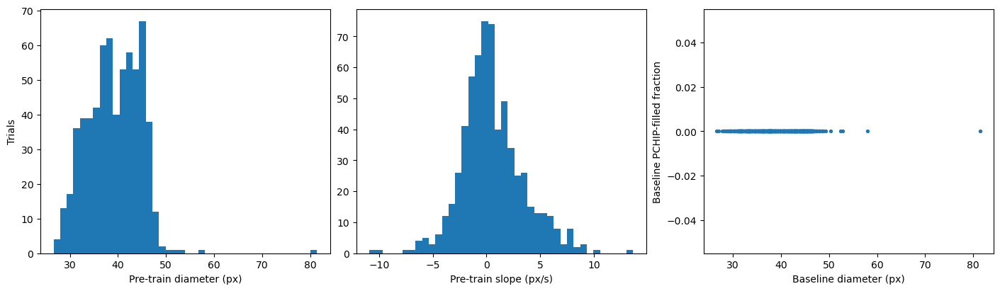

In [ ]:
from scipy import stats, signal as scipy_signal
rng=np.random.default_rng(RANDOM_SEED)

if not BASELINE_TRAIN_S[0]<BASELINE_TRAIN_S[1]<=0:raise ValueError('Baseline must precede train onset.')
if ANALYSIS_GRID_STEP_S<=0 or ANALYSIS_MAX_GAP_S<=0:raise ValueError('Sampling intervals must be positive.')

finite_time=np.isfinite(t) # gets the boolean mask of the time array t, where True indicates finite values and False indicates non-finite values (like NaN or Inf). This is used to filter out invalid time points for further analysis.
pt=t[finite_time];py=y[finite_time].copy()
pflag=pupil.loc[finite_time,'was_interpolated'].to_numpy(bool)

if PD_VALID_RANGE_PX is not None:py[(py<PD_VALID_RANGE_PX[0])|(py>PD_VALID_RANGE_PX[1])]=np.nan
if not len(pt) or not np.all(np.diff(pt)>0):raise ValueError('Finite pupil times must be strictly increasing.')

def bounded_sample(q,ts=pt,values=py,max_gap=ANALYSIS_MAX_GAP_S):
    q=np.asarray(q,float);out=np.full(q.shape,np.nan);right=np.searchsorted(ts,q)
    inside=right<len(ts);ix=np.flatnonzero(inside)
    exact=np.zeros(q.shape,bool);exact[ix]=np.isclose(ts[right[ix]],q[ix],rtol=0,atol=1e-9)
    out[exact]=values[right[exact]]
    ix=np.flatnonzero(~exact&(right>0)&(right<len(ts)));r=right[ix];l=r-1
    ok=(ts[r]-ts[l]<=max_gap)&np.isfinite(values[r])&np.isfinite(values[l])
    ix,r,l=ix[ok],r[ok],l[ok]
    out[ix]=values[l]+(values[r]-values[l])*(q[ix]-ts[l])/(ts[r]-ts[l])
    return out

def grid_between(a,b):return np.arange(a,b+ANALYSIS_GRID_STEP_S/4,ANALYSIS_GRID_STEP_S)

def filled_fraction(a,b):
    mask=(pt>=a)&(pt<=b)
    return float(pflag[mask].mean()) if mask.any() and PCHIP_FLAG_AVAILABLE else np.nan

def window_stats(a,b,next_train=np.nan):
    if np.isfinite(next_train) and b>=next_train-NEXT_TRAIN_GUARD_S:return np.nan,0.,np.nan,'overlaps_next_train'
    q=grid_between(a,b);v=bounded_sample(q);coverage=float(np.isfinite(v).mean())
    fraction=filled_fraction(a,b)
    mean=float(np.nanmean(v)) if np.isfinite(v).any() else np.nan
    return mean,coverage,fraction,'ok'

metrics=trials.copy()
for i,row in metrics.iterrows():
    a,b=row.train_start_s+BASELINE_TRAIN_S[0],row.train_start_s+BASELINE_TRAIN_S[1]
    q=grid_between(a,b);v=bounded_sample(q);good=np.isfinite(v)
    bmean=float(np.nanmean(v)) if good.any() else np.nan
    slope=float(stats.linregress(q[good]-row.train_start_s,v[good]).slope) if good.sum()>=3 else np.nan
    fraction=filled_fraction(a,b)
    base_ok=good.mean()>=MIN_BASELINE_COVERAGE and (not np.isfinite(fraction) or fraction<=MAX_BASELINE_INTERPOLATED_FRACTION)
    metrics.at[i,'baseline_pd_px']=bmean;metrics.at[i,'baseline_slope_px_s']=slope
    metrics.at[i,'baseline_coverage']=good.mean();metrics.at[i,'baseline_filled_fraction']=fraction
    metrics.at[i,'baseline_ok']=bool(base_ok)
    windows={k:(row.stimulus3_start_s+lo,row.stimulus3_start_s+hi) for k,(lo,hi) in STIM3_WINDOWS.items()}
    windows['immediate_postend']=(row.train_end_s,row.train_end_s+1.0)
    windows['postend']=(row.train_end_s+POSTEND_WINDOW_S[0],row.train_end_s+POSTEND_WINDOW_S[1])
    for name,(a,b) in windows.items():
        overlap=max(0.,min(b,row.next_train_start_s+BASELINE_TRAIN_S[1])-max(a,row.next_train_start_s+BASELINE_TRAIN_S[0])) if np.isfinite(row.next_train_start_s) else np.nan
        metrics.at[i,name+'_next_baseline_overlap_s']=overlap
        mean,cov,frac,reason=window_stats(a,b,row.next_train_start_s)
        ok=bool(base_ok and cov>=MIN_METRIC_COVERAGE and np.isfinite(mean) and (not np.isfinite(frac) or frac<=MAX_RESPONSE_INTERPOLATED_FRACTION) and reason=='ok')
        metrics.at[i,name+'_raw_px']=mean;metrics.at[i,name+'_delta_px']=mean-bmean
        metrics.at[i,name+'_coverage']=cov;metrics.at[i,name+'_filled_fraction']=frac
        metrics.at[i,name+'_ok']=ok
        metrics.at[i,name+'_reason']='accepted' if ok else (reason if reason!='ok' else 'baseline_or_response_quality')
for col in ['baseline_ok']+[k+'_ok' for k in [*STIM3_WINDOWS,'postend','immediate_postend']]:metrics[col]=metrics[col].astype(bool)
metrics['reference_standard']=metrics.is_standard & metrics.phase.eq('main') & (~metrics.standard_position_after_deviant.between(1,EXCLUDE_FIRST_N_STANDARDS_AFTER_DEVIANT))
metrics.to_csv(OUTPUT_DIR/'trial_metrics.csv',index=False)
display(metrics.groupby(['block','phase','sequence'])[['baseline_ok','primary_ok','postend_ok']].agg(['sum','count']))
fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
axes[0].hist(metrics.baseline_pd_px.dropna(),bins=40);axes[0].set(xlabel='Pre-train diameter (px)',ylabel='Trials')
axes[1].hist(metrics.baseline_slope_px_s.dropna(),bins=40);axes[1].set_xlabel('Pre-train slope (px/s)')
axes[2].scatter(metrics.baseline_pd_px,metrics.baseline_filled_fraction,s=8);axes[2].set(xlabel='Baseline diameter (px)',ylabel='Baseline PCHIP-filled fraction')
save_and_show()


## II.3. Reusable waveform plotting and summaries

**Purpose:** retain raw and baseline-subtracted traces, trial ordering and local missing data. Each condition is corrected using each trial's own baseline before averaging. Curves use the same reference point: train onset for train plots or stimulus 3 for deviant/standard comparisons. Standards therefore have a virtual deviant position at their third stimulus. SEM shown here describes within-session event variability, not uncertainty across independent animals. Heatmap rows retain original block-trial numbers, including gaps from rejected trials.


**Comparison colours:** curves use a separate colour for each labelled group, even when both contain the same sequence. This separates warm-up/fixed/main AAAA or BBBB and identical sequences across A/B versus C. Sequence colours in trial scatter plots and heatmaps retain their existing meaning. The plotting helper also supports `raw=True`, showing absolute diameter for the exact baseline-eligible trials and samples used in its corrected curves. Per-time-point valid counts are exported; the legend n is the number of included trial rows, not a guarantee that every sample is present.


In [16]:
analysis_dir=OUTPUT_DIR/'block_analysis';analysis_dir.mkdir(exist_ok=True)
COLORS={'AAAA':'#2166ac','AABA':'#d6604d','BBBB':'#43934b','BBAB':'#8f4db0'}

import re, base64, html
from IPython.display import HTML
plot_queue = []
def finish_plot(name):
    fig=plt.gcf()
    path=analysis_dir/(name+'.png')
    fig.savefig(path,dpi=150,bbox_inches='tight')
    if GROUP_SIMILAR_PLOTS:
        plot_queue.append((name,path))
    else:
        plt.show()
    plt.close(fig)

def show_grouped_plots():
    # Pair A/B counterparts, or C sequence counterparts, by analysis type.
    groups={}
    for name,path in plot_queue:
        key=re.sub(r'^[AB]_', '', name)
        key=re.sub(r'^C_(AAAA|AABA|BBBB|BBAB)_', 'C_sequence_', key)
        groups.setdefault(key,[]).append((name,path))
    for key,items in groups.items():
        cards=[]
        for name,path in items:
            data=base64.b64encode(path.read_bytes()).decode('ascii')
            cards.append('<div style="min-width:0"><b>'+html.escape(name.replace('_',' '))+
                         '</b><img style="width:100%" src="data:image/png;base64,'+data+'"></div>')
        columns='1fr 1fr' if len(items)>1 else '1fr'
        display(HTML('<div style="display:grid;grid-template-columns:'+columns+
                     ';gap:14px;margin:18px 0">'+''.join(cards)+'</div>'))
    plot_queue.clear()


def waveform(frame,anchor='stimulus3_start_s',window=STIM3_PLOT_WINDOW_S,strict=False):
    g=grid_between(*window);rows=[];ids=[]
    for i,row in frame.iterrows():
        if not row.baseline_ok:continue
        values=bounded_sample(row[anchor]+g)-row.baseline_pd_px
        if np.isfinite(row.next_train_start_s):values[row[anchor]+g>=row.next_train_start_s-NEXT_TRAIN_GUARD_S]=np.nan
        if strict:
            right=np.clip(np.searchsorted(pt,row[anchor]+g),0,len(pt)-1);left=np.maximum(right-1,0)
            values[pflag[left]|pflag[right]]=np.nan
        rows.append(values);ids.append(i)
    return g,np.asarray(rows).reshape(-1,len(g)),ids

def nan_summary(matrix):
    n=np.isfinite(matrix).sum(axis=0);total=np.nansum(matrix,axis=0)
    mean=np.divide(total,n,out=np.full(matrix.shape[1],np.nan),where=n>0)
    ss=np.nansum((matrix-mean)**2,axis=0)
    var=np.divide(ss,n-1,out=np.full(len(mean),np.nan),where=n>1)
    return mean,np.sqrt(var/np.maximum(n,1)),n

def curves(groups, name, anchor='stimulus3_start_s',
           window=STIM3_PLOT_WINDOW_S, colors=None, raw=False):
    palette = plt.get_cmap('tab10').colors
    fig, ax = plt.subplots(figsize=(10, 4))
    outputs = []
    for j, (label, frame) in enumerate(groups.items()):
        g, matrix, ids = waveform(frame, anchor, window)
        if not len(matrix):
            continue
        if raw:
            matrix = matrix + frame.loc[ids, 'baseline_pd_px'].to_numpy()[:, None]
        mean, sem, count = nan_summary(matrix)
        color = (colors or {}).get(label, palette[j % len(palette)])
        ax.plot(g, mean, color=color, label=f'{label} (n={len(ids)})')
        ax.fill_between(g, mean-sem, mean+sem, color=color, alpha=0.18)
        outputs.append(pd.DataFrame({
            'condition': label, 'relative_time_s': g,
            ('mean_raw_px' if raw else 'mean_delta_px'): mean, 'sem_events_px': sem, 'n_events': count,
            'measurement': 'raw_PD' if raw else 'pretrain_corrected_PD'}))
    ax.axvline(0, color='black', ls='--', lw=0.8)
    if not raw:
        ax.axhline(0, color='gray', lw=0.6)
    ax.set(xlabel=f'Time from {anchor} (s)',
           ylabel='Pupil diameter (px)' if raw else 'Change from pre-train baseline (px)',
           title=name.replace('_', ' '))
    if outputs:
        ax.legend(fontsize=8)
        pd.concat(outputs).to_csv(analysis_dir / f'{name}.csv', index=False)
    finish_plot(name)

def heatmap(frame,name,anchor='stimulus3_start_s',window=STIM3_PLOT_WINDOW_S):
    g,m,ids=waveform(frame.sort_values('block_trial'),anchor,window)
    if not len(m):return
    fig,ax=plt.subplots(figsize=(9,5));limit=max(float(np.nanpercentile(np.abs(m),98)),1e-6)
    im=ax.imshow(m,origin='lower',aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit,extent=[g[0],g[-1],-.5,len(m)-.5],interpolation='nearest')
    ticks=np.unique(np.linspace(0,len(m)-1,min(8,len(m))).astype(int));ax.set_yticks(ticks,frame.loc[ids,'block_trial'].iloc[ticks].astype(int))
    ax.axvline(0,color='black',ls='--');ax.set(xlabel='Relative time (s)',ylabel='Original block trial',title=name.replace('_',' '))
    fig.colorbar(im,ax=ax,label='ΔPD (px)');finish_plot(name)


## II.4. Starting state, warm-up and fixed-standard adaptation (ideas 2, 4, 5)

**Question:** does the starting pupil state change across trials, and does the train-evoked response adapt? Plot baseline diameter, baseline slope and the primary outcome separately. A change in starting diameter is not the same as adaptation of the corrected response. Warm-up and fixed standards remain separate from main standards. Heatmaps are train aligned; condition averages show both phases. Early-versus-late phase means and descriptive slopes are exported; no within-mouse trial p-values are interpreted as animal-level evidence.



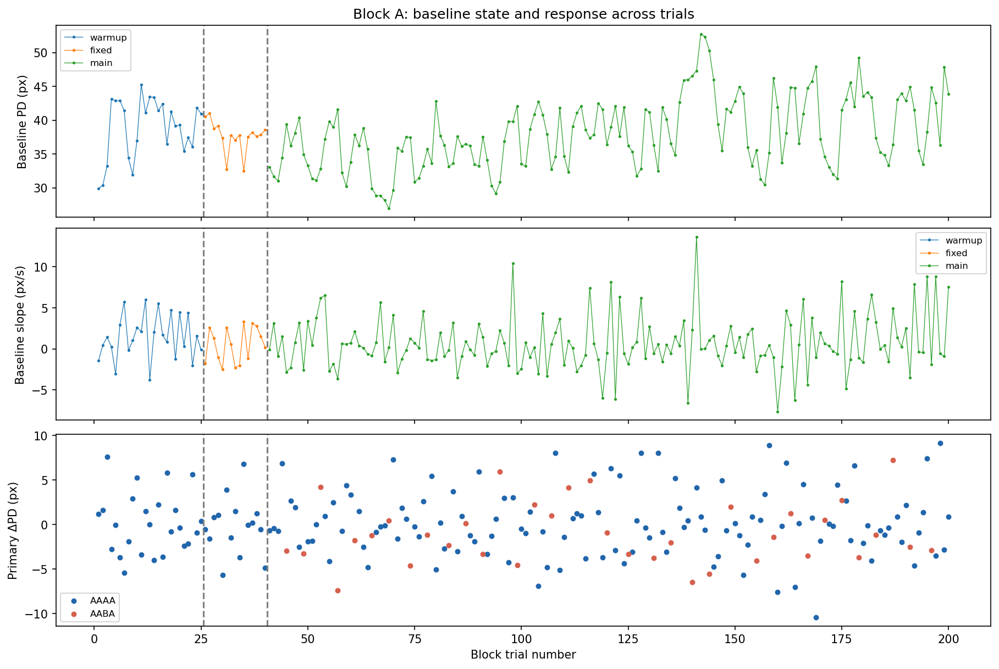
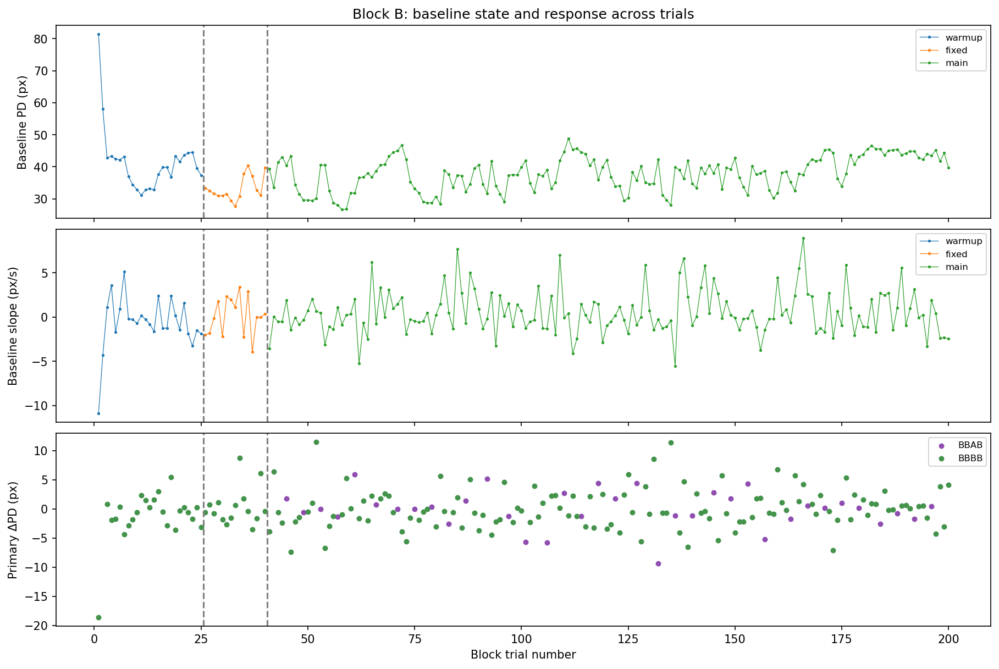


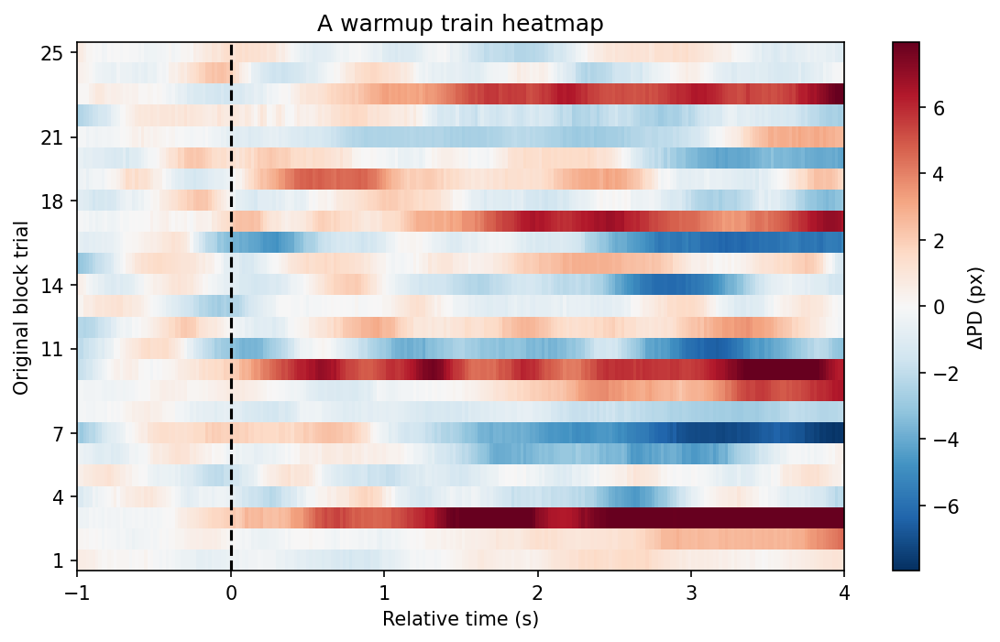
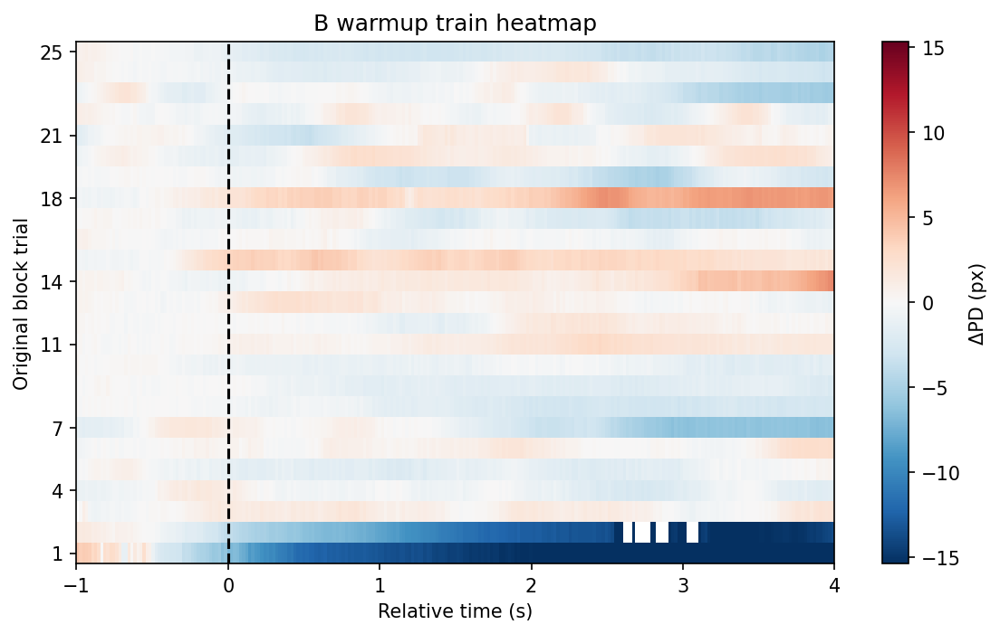


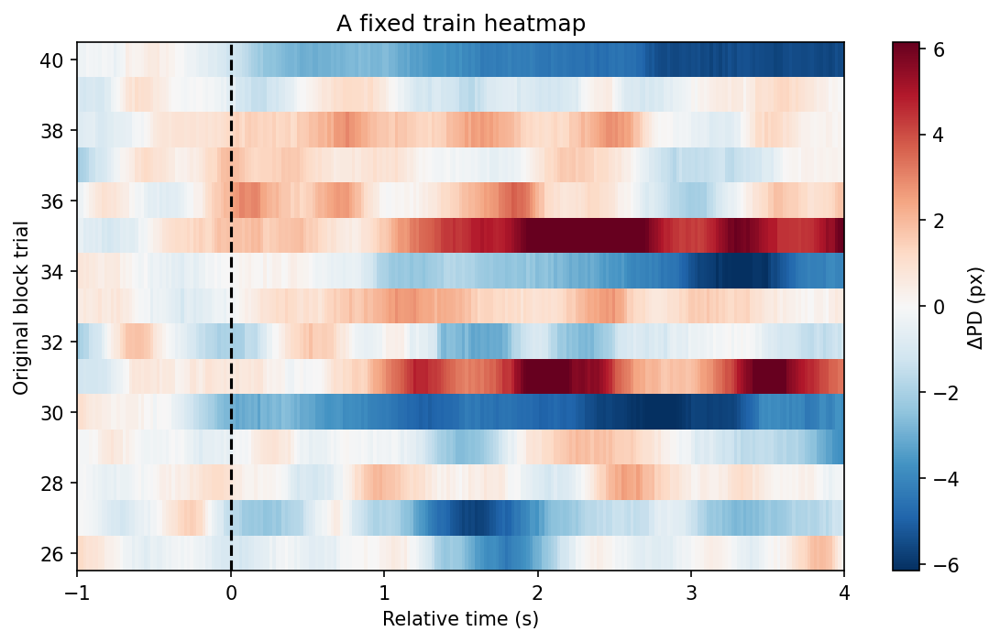
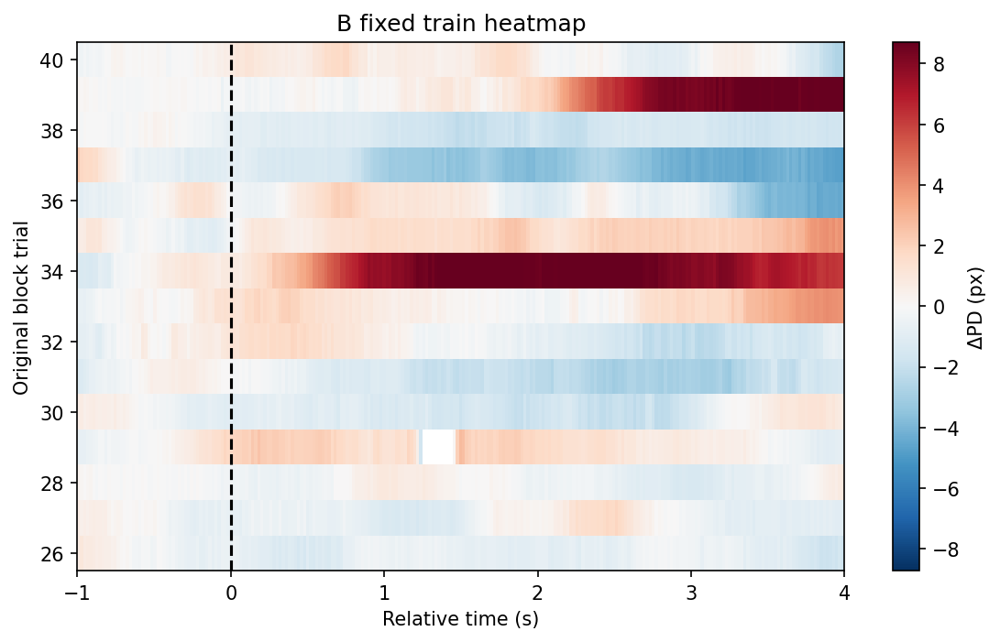


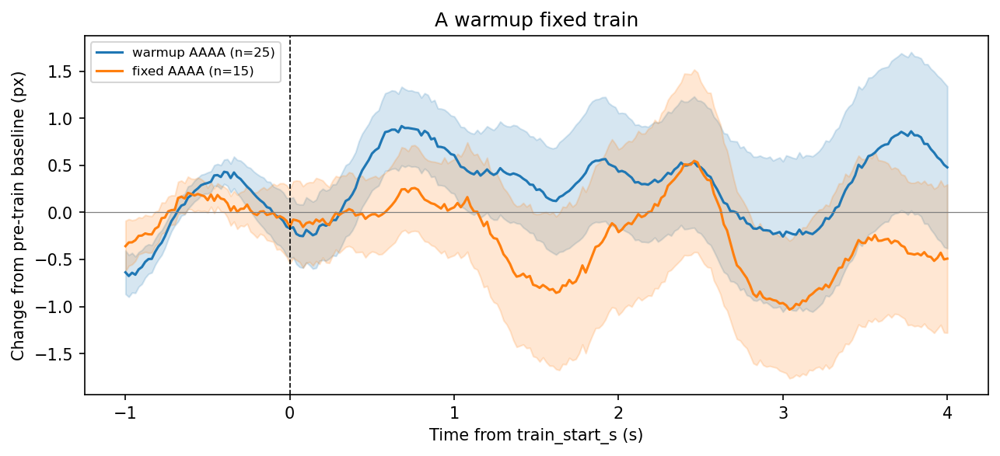
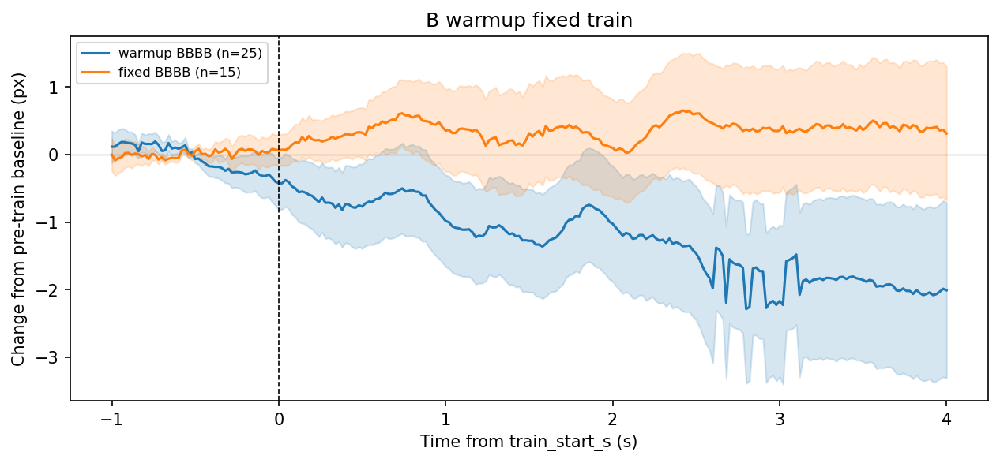


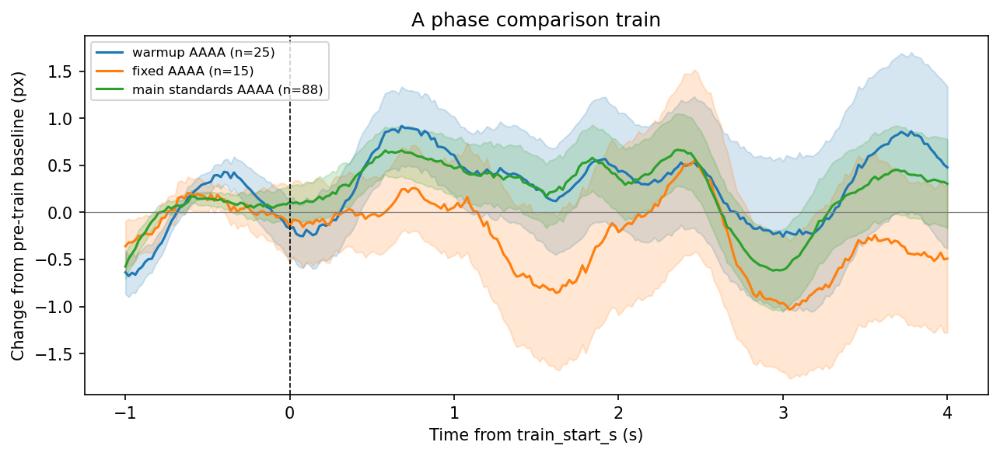
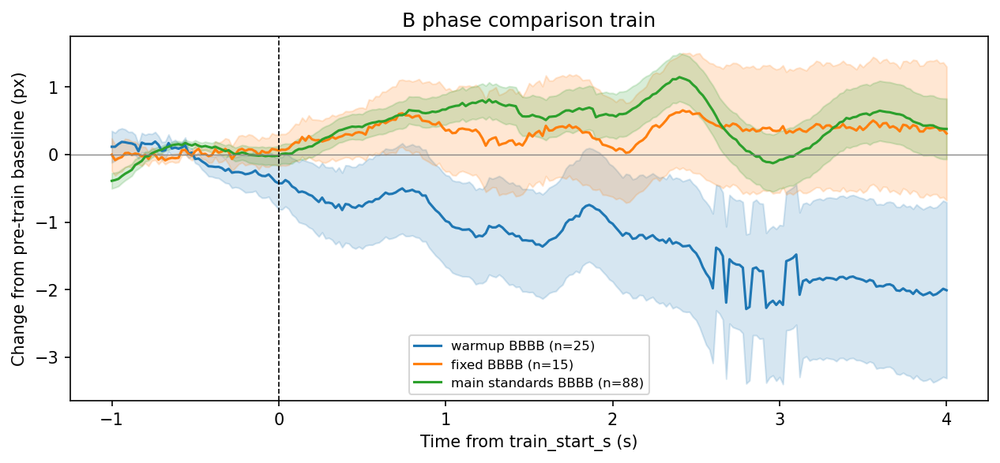

In [17]:
phase_summaries=[]
for block in ['A','B']:
    b=metrics.loc[metrics.block.eq(block)].copy()
    if b.empty:continue
    fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True,constrained_layout=True)
    for phase,g in b.groupby('phase',sort=False):
        axes[0].plot(g.block_trial,g.baseline_pd_px,'.-',ms=3,lw=.6,label=phase)
        axes[1].plot(g.block_trial,g.baseline_slope_px_s,'.-',ms=3,lw=.6,label=phase)
    for seq,g in b.loc[b.primary_ok].groupby('sequence'):
        axes[2].scatter(g.block_trial,g.primary_delta_px,s=14,color=COLORS[seq],label=seq)
    for ax in axes:
        ax.axvline(25.5,color='gray',ls='--');ax.axvline(40.5,color='gray',ls='--');ax.legend(fontsize=8)
    axes[0].set_ylabel('Baseline PD (px)');axes[1].set_ylabel('Baseline slope (px/s)');axes[2].set(ylabel='Primary ΔPD (px)',xlabel='Block trial number')
    axes[0].set_title(f'Block {block}: baseline state and response across trials');finish_plot(f'{block}_trial_trajectories')
    groups={}
    for phase in ['warmup','fixed']:
        g=b.loc[b.phase.eq(phase)]
        groups[phase+' '+('AAAA' if block=='A' else 'BBBB')]=g
        heatmap(g,f'{block}_{phase}_train_heatmap','train_start_s',TRAIN_PLOT_WINDOW_S)
        usable=g.loc[g.primary_ok]
        for column in ['baseline_pd_px','baseline_slope_px_s','primary_delta_px']:
            good=usable[['block_trial',column]].dropna();mid=len(g)//2
            slope=stats.linregress(good.block_trial,good[column]).slope if len(good)>=3 else np.nan
            phase_summaries.append(dict(block=block,phase=phase,measure=column,n=len(good),mean=good[column].mean(),slope_per_trial=slope,
                early_mean=usable.loc[usable.index.isin(g.index[:mid]),column].mean(),late_mean=usable.loc[usable.index.isin(g.index[mid:]),column].mean()))
    curves(groups,f'{block}_warmup_fixed_train','train_start_s',TRAIN_PLOT_WINDOW_S)
    curves({**groups,'main standards '+('AAAA' if block=='A' else 'BBBB'):b.loc[b.reference_standard]},f'{block}_phase_comparison_train','train_start_s',TRAIN_PLOT_WINDOW_S)
pd.DataFrame(phase_summaries).to_csv(analysis_dir/'warmup_fixed_adaptation_summary.csv',index=False)

show_grouped_plots()


## II.5. Absolute diameter, baseline correction and standard-reference sensitivity

**Question:** does the negative deviant-minus-standard contrast reflect absolute pupil size, the pre-train baseline, or which standards enter the comparison?

The first plots show absolute PD and pre-train-corrected PD for the **same baseline-eligible trials and samples**. Green is all main standards (124 in a complete block before quality exclusions), blue is the restricted reference (88 with the default first-post-deviant exclusion), and orange is deviants (36 before exclusions). All and reference standards share trials; these are descriptive sensitivity comparisons, not independent groups.

The next plots compare pre-train baseline diameter and slope. Dots are individual trials and black bars are means. A positive slope indicates an already increasing diameter. Subtraction removes the starting level, not that trajectory. Inspect raw/corrected curves together; a negative corrected contrast does not necessarily mean smaller absolute pupils. A nonzero slope alone does not establish carryover, and different baselines do not by themselves establish tracking failure.

Figures and `additional_baseline_summary.csv` are saved under `block_analysis`. No causal or mouse-level significance claim is made.



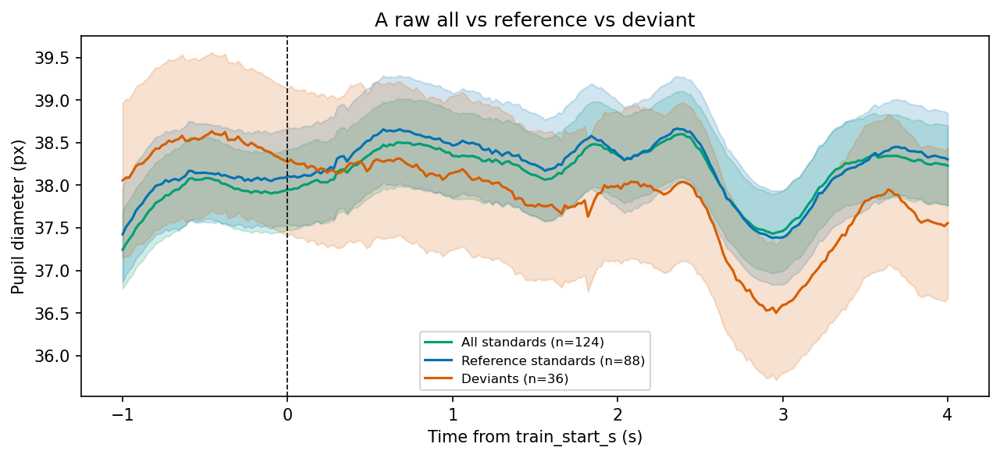
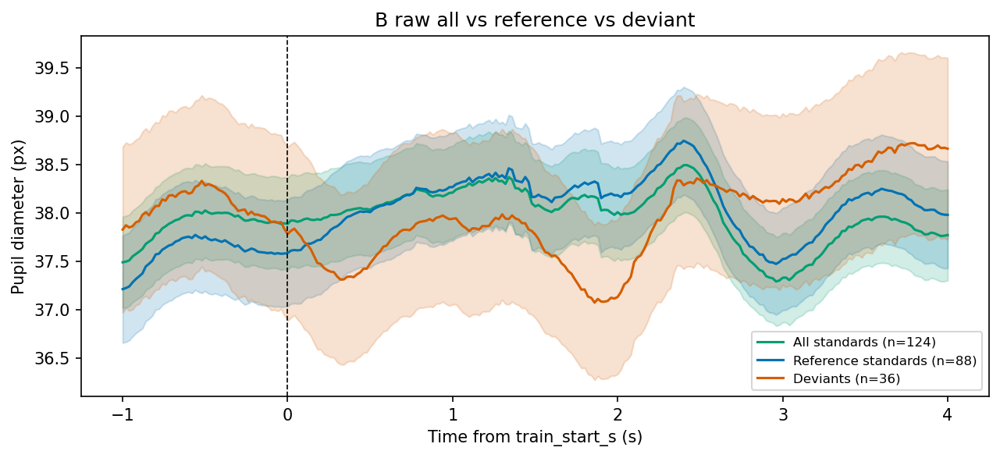


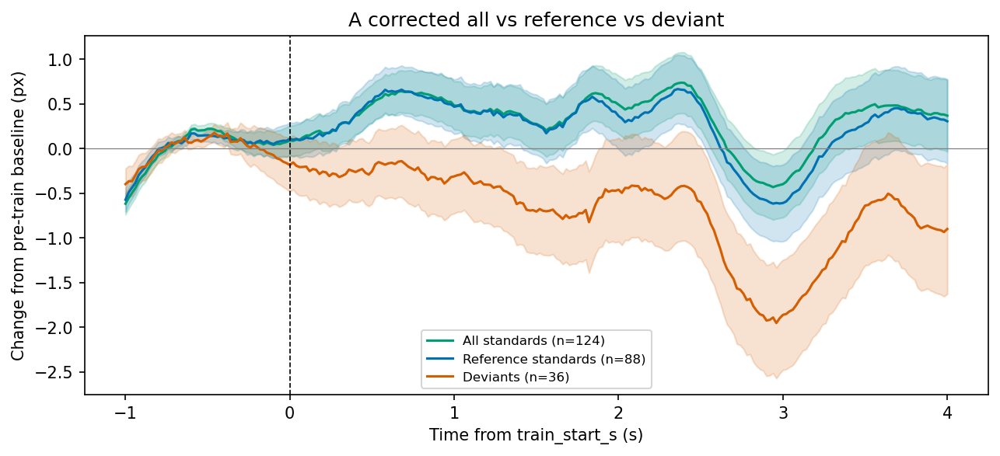
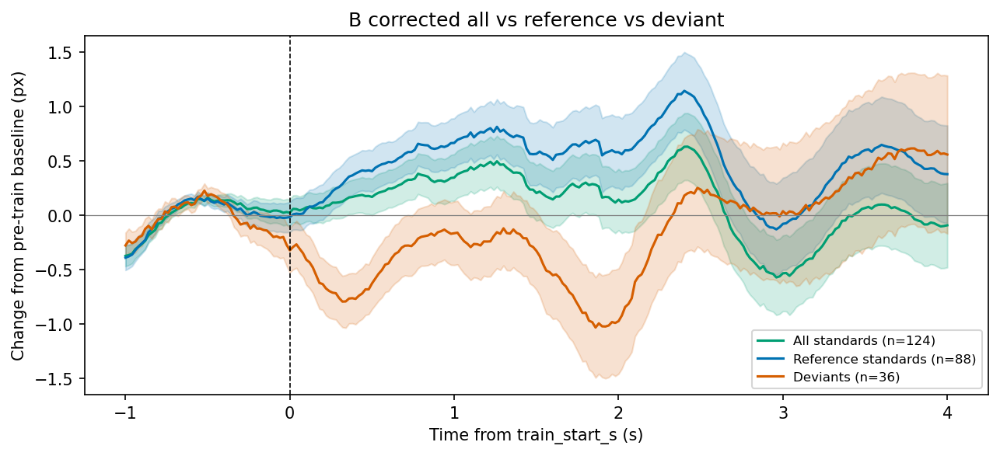


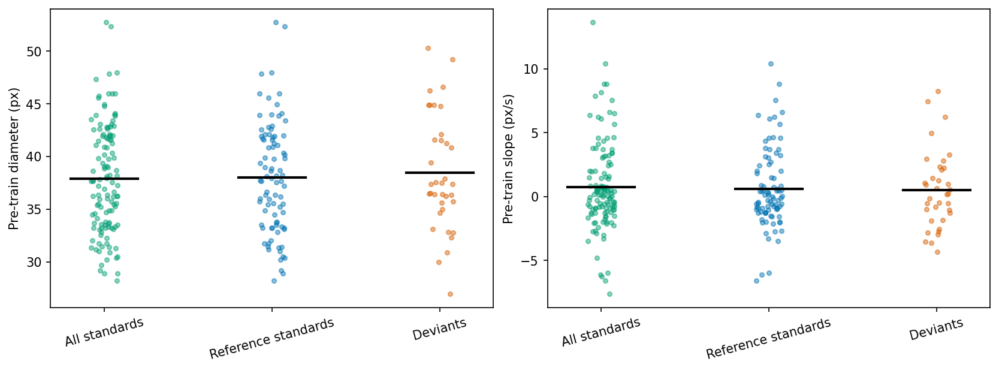
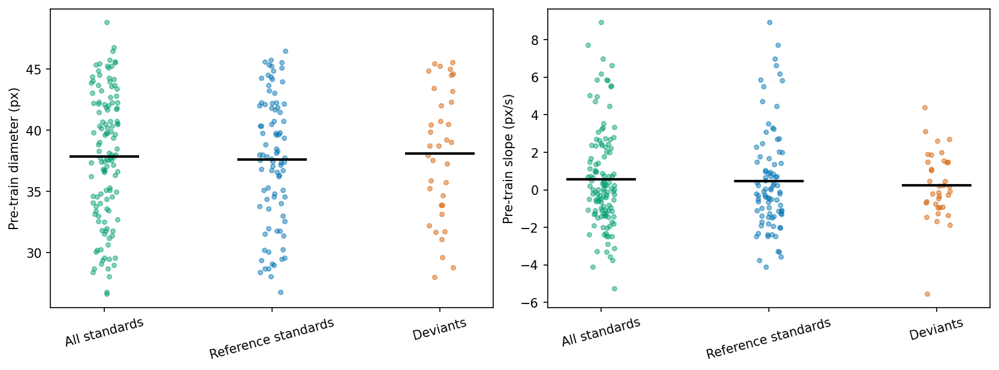

In [18]:
diagnostic_rows = []
for block in ['A', 'B']:
    main = metrics.loc[metrics.block.eq(block) & metrics.phase.eq('main')]
    groups = {'All standards': main.loc[main.is_standard],
              'Reference standards': main.loc[main.reference_standard],
              'Deviants': main.loc[main.is_deviant]}
    colors = {'All standards': '#009E73', 'Reference standards': '#0072B2',
              'Deviants': '#D55E00'}
    for raw in [True, False]:
        kind = 'raw' if raw else 'corrected'
        curves(groups, f'{block}_{kind}_all_vs_reference_vs_deviant',
               'train_start_s', TRAIN_PLOT_WINDOW_S, colors=colors, raw=raw)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for j, (label, frame) in enumerate(groups.items()):
        good = frame.loc[frame.baseline_ok]
        for ax, column in zip(axes, ['baseline_pd_px', 'baseline_slope_px_s']):
            values = good[column].dropna().to_numpy()
            jitter = np.random.default_rng(100+j).uniform(-0.08, 0.08, len(values))
            ax.scatter(j+jitter, values, s=12, alpha=0.45, color=colors[label])
            if len(values):
                ax.plot([j-.2, j+.2], [values.mean()]*2, color='black', lw=2)
            diagnostic_rows.append({'block': block, 'group': label,
                                    'measure': column, 'n': len(values),
                                    'mean': values.mean() if len(values) else np.nan})
    for ax, title in zip(axes, ['Pre-train diameter (px)', 'Pre-train slope (px/s)']):
        ax.set_xticks(range(len(groups)), list(groups), rotation=15)
        ax.set_ylabel(title)
    finish_plot(f'{block}_baseline_state_comparison')
pd.DataFrame(diagnostic_rows).to_csv(analysis_dir/'additional_baseline_summary.csv', index=False)
show_grouped_plots()


## II.6. Separation before stimulus 3 and local-reference sensitivity

**Question:** are the trial groups already separated before the deviant appears, and does their separation increase afterward?

The configurable `PRE3_WINDOW_S` (default **−0.25 to −0.05 s relative to stimulus 3**) samples the end of the second stimulus and the following ISI. It is an immediate pre-divergence reference, **not a resting baseline**. It inherits pupil sampling and interpolation-quality gates. The original pre-train baseline and all original response metrics are preserved.

The new trial table retains:

| Column | Meaning |
|---|---|
| `pre3_raw_px` | Absolute PD in the short local window |
| `pre3_corrected_px` | Local PD minus the original pre-train baseline |
| `primary_local_change_px` | Mean PD 1–2 s after stimulus 3 minus local PD |
| `pre3_coverage`, `pre3_filled_fraction`, `pre3_ok` | Local-window quality diagnostics |

The summary compares all standards and reference standards separately against deviants. Within each comparison, all three metrics use the **same accepted trial rows**. Thus, the local-reference contrast equals the original primary contrast minus the pre-stimulus-3 contrast for those rows. A near-zero local contrast suggests that much of the original separation was already present; a negative local contrast indicates increasing separation afterward. Neither alone demonstrates a causal deviant effect: preceding responses, locomotion, luminance changes and stimulus 4 can contribute.

Matched-trial plots show both original correction and local correction. Local zeroing removes level differences at the reference window but does not remove different slopes or resolve carryover. Do not choose a reference/window because it produces the expected sign. The original primary metric stays primary. Results are exploratory and descriptive for a single mouse.

Exports: `trial_metrics_pre3_sensitivity.csv`, `pre3_and_primary_sensitivity_summary.csv`, and the matched-trial waveforms. Video inspection and camera/DAQ alignment checks remain necessary.


,block,reference,measure,n_standard,n_deviant,standard_mean_px,deviant_mean_px,deviant_minus_standard_px
0,A,all_standards,pre3_corrected_px,124,36,0.570781,-0.320213,-0.890994
1,A,all_standards,primary_delta_px,124,36,0.204113,-1.026913,-1.231026
2,A,all_standards,primary_local_change_px,124,36,-0.366668,-0.706700,-0.340031
3,A,reference_standards,pre3_corrected_px,88,36,0.543456,-0.320213,-0.863670
4,A,reference_standards,primary_delta_px,88,36,0.074529,-1.026913,-1.101442
5,A,reference_standards,primary_local_change_px,88,36,-0.468927,-0.706700,-0.237773
6,B,all_standards,pre3_corrected_px,124,36,0.336303,-0.172884,-0.509187
7,B,all_standards,primary_delta_px,124,36,0.073252,-0.052838,-0.126090
8,B,all_standards,primary_local_change_px,124,36,-0.263051,0.120046,0.383097
9,B,reference_standards,pre3_corrected_px,88,36,0.637816,-0.172884,-0.810700



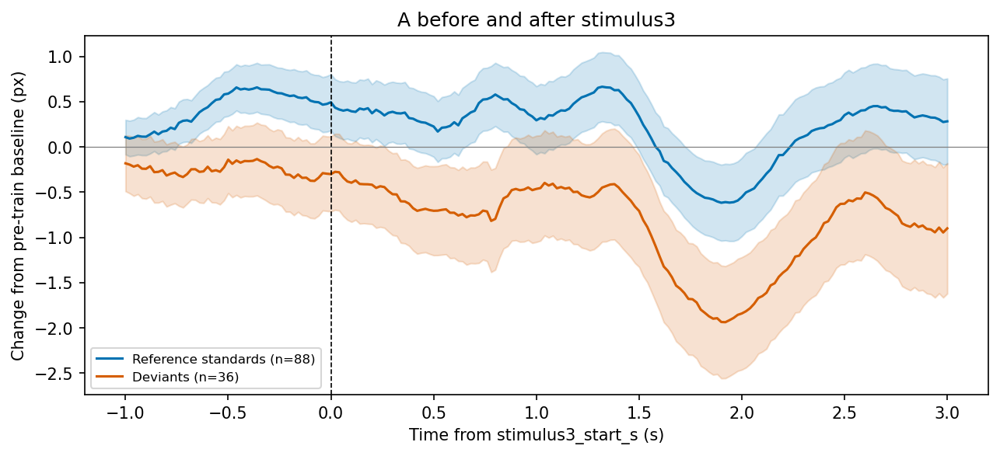
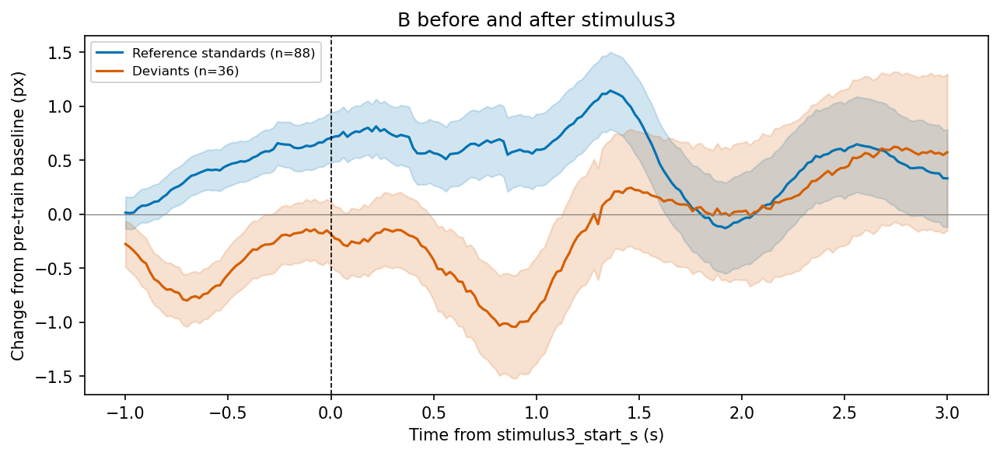


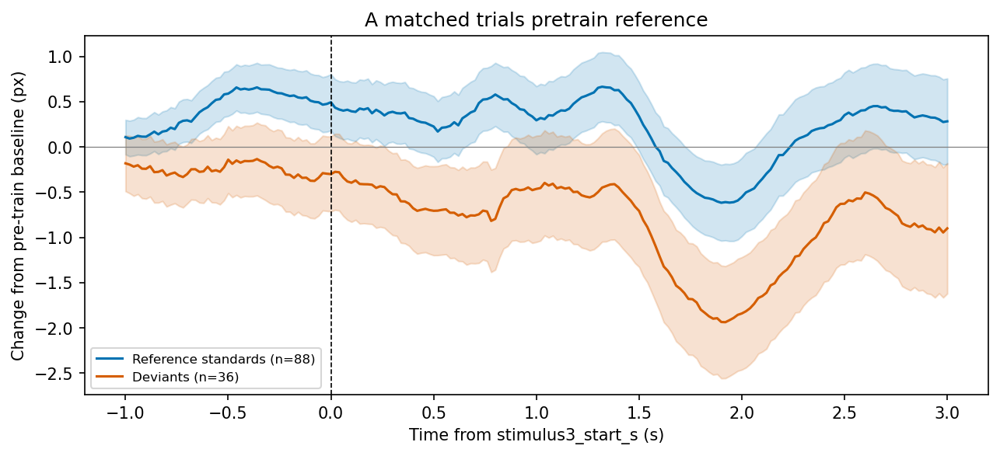
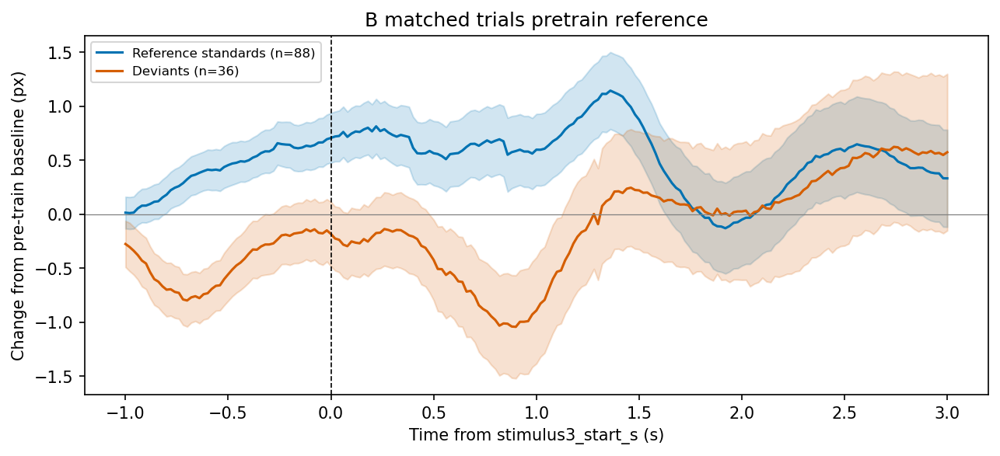


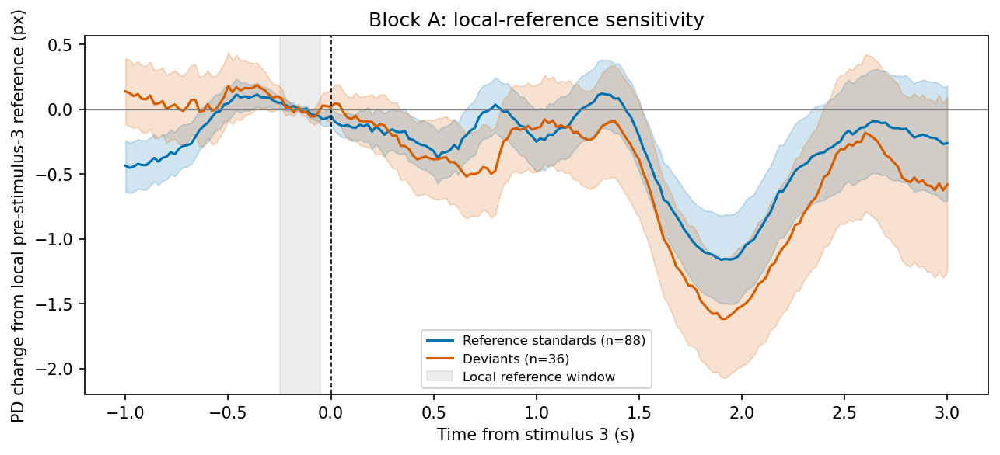
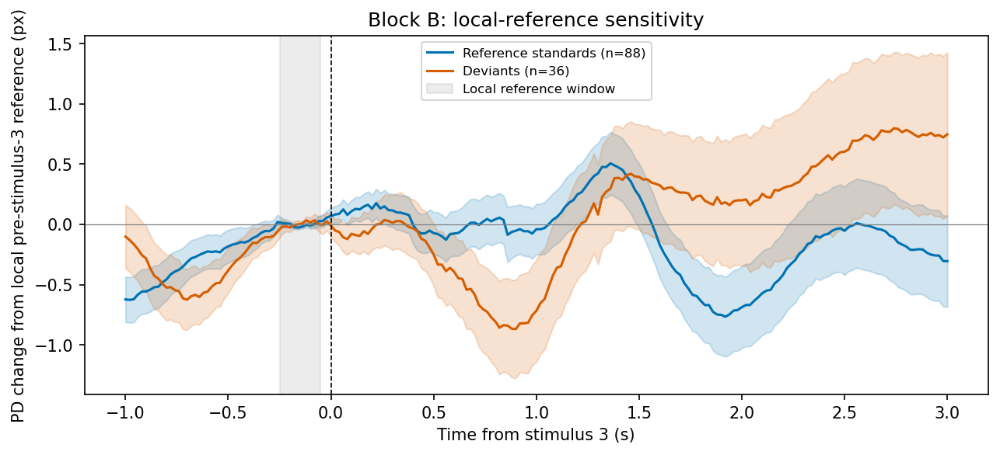

In [19]:
if not PRE3_WINDOW_S[0] < PRE3_WINDOW_S[1] <= 0:
    raise ValueError('PRE3_WINDOW_S must lie before stimulus 3.')
extra = metrics.copy()
for i, row in extra.iterrows():
    a, b = row.stimulus3_start_s + np.array(PRE3_WINDOW_S)
    values = bounded_sample(grid_between(a, b))
    coverage = np.isfinite(values).mean()
    fraction = filled_fraction(a, b)
    ok = (row.baseline_ok and coverage >= MIN_METRIC_COVERAGE
          and (not np.isfinite(fraction) or fraction <= MAX_RESPONSE_INTERPOLATED_FRACTION))
    pre_raw = float(np.nanmean(values)) if ok else np.nan
    extra.at[i, 'pre3_coverage'] = coverage
    extra.at[i, 'pre3_filled_fraction'] = fraction
    extra.at[i, 'pre3_ok'] = bool(ok)
    extra.at[i, 'pre3_raw_px'] = pre_raw
    extra.at[i, 'pre3_corrected_px'] = pre_raw-row.baseline_pd_px
    extra.at[i, 'primary_local_change_px'] = (
        row.primary_raw_px-pre_raw if row.primary_ok and ok else np.nan)
extra.to_csv(analysis_dir/'trial_metrics_pre3_sensitivity.csv', index=False)
rows = []
for block in ['A', 'B']:
    main = extra.loc[extra.block.eq(block) & extra.phase.eq('main')]
    dev = main.loc[main.is_deviant]
    for reference, std in [('all_standards', main.loc[main.is_standard]),
                           ('reference_standards', main.loc[main.reference_standard])]:
        # Same accepted trials for every reported metric in this comparison.
        columns = ['pre3_corrected_px', 'primary_delta_px', 'primary_local_change_px']
        s = std.loc[std.primary_ok].dropna(subset=columns)
        d = dev.loc[dev.primary_ok].dropna(subset=columns)
        for column in columns:
            rows.append({'block': block, 'reference': reference, 'measure': column,
                         'n_standard': len(s), 'n_deviant': len(d),
                         'standard_mean_px': s[column].mean(),
                         'deviant_mean_px': d[column].mean(),
                         'deviant_minus_standard_px': d[column].mean()-s[column].mean()})
    groups = {'Reference standards': main.loc[main.reference_standard], 'Deviants': dev}
    curves(groups, f'{block}_before_and_after_stimulus3',
           window=(-1.0, 3.0), colors={'Reference standards':'#0072B2', 'Deviants':'#D55E00'})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(analysis_dir/'pre3_and_primary_sensitivity_summary.csv', index=False)
# Show the same matched eligible rows under the original and local reference.
for block in ['A','B']:
    b = extra.loc[extra.block.eq(block) & extra.phase.eq('main')]
    groups = {'Reference standards': b.loc[b.reference_standard],
              'Deviants': b.loc[b.is_deviant]}
    matched = {label: frame.loc[frame.primary_ok].dropna(
        subset=['pre3_corrected_px','primary_local_change_px'])
        for label,frame in groups.items()}
    curves(matched, f'{block}_matched_trials_pretrain_reference',
           colors={'Reference standards':'#0072B2','Deviants':'#D55E00'})
    fig,ax=plt.subplots(figsize=(10,4))
    for label,frame in matched.items():
        g,m,ids=waveform(frame)
        if not len(ids):continue
        m=m-frame.loc[ids,'pre3_corrected_px'].to_numpy()[:,None]
        mean,sem,count=nan_summary(m)
        color={'Reference standards':'#0072B2','Deviants':'#D55E00'}[label]
        ax.plot(g,mean,color=color,label=f'{label} (n={len(ids)})')
        ax.fill_between(g,mean-sem,mean+sem,color=color,alpha=.18)
    ax.axvspan(*PRE3_WINDOW_S,color='gray',alpha=.15,label='Local reference window')
    ax.axvline(0,color='black',ls='--',lw=.8);ax.axhline(0,color='gray',lw=.6)
    ax.set(xlabel='Time from stimulus 3 (s)',ylabel='PD change from local pre-stimulus-3 reference (px)',
           title=f'Block {block}: local-reference sensitivity')
    if ax.get_legend_handles_labels()[0]:ax.legend(fontsize=8)
    finish_plot(f'{block}_matched_trials_local_reference')

show_grouped_plots()


## II.7. Pupil trajectory, slope change and starting-state adjustment

A pre-train mean is a reference, not evidence that the pupil is stable. Subtraction removes a level offset but does not remove a rising/falling trajectory. The existing saved outputs already show separation before stimulus 3. Inspect absolute pre-train traces and slope distributions before interpreting a response contrast.

### Fixed slope definitions
For each trial, fit diameter versus time by ordinary least squares within each window. This estimates a window-averaged rate (px/s), not an instantaneous derivative. The same tracking, interpolation and next-train guards apply. We additionally reject pre-train windows extending into the previous train. Report coverage, interpolation fraction and linear-fit R²; curved traces can be poorly described by one slope.

| Measure | Window | Interpretation |
|---|---|---|
| Pre-train slope | `BASELINE_TRAIN_S`, −1 to −0.2 s from train onset | Starting recovery trajectory |
| Pre-stimulus-3 slope | −0.50 to −0.05 s from stimulus 3 | Immediate pre-divergence trajectory; includes stimulus 2/ISI |
| Early post-3 slope | +0.25 to +1.0 s | Early subsequent trajectory |
| Primary post-3 slope | +1.0 to +2.0 s | Later subsequent trajectory |
| Train-relative slope change | post-3 slope minus pre-train slope | Change from starting recovery trajectory |
| Local slope change | post-3 slope minus pre-3 slope | Change around sequence divergence |

**Sign:** negative change means the slope became more negative (or less positive). It does not necessarily mean the post-window pupil was constricting: inspect the post slope itself. Constant baseline subtraction cannot change a slope. Slope change is a complementary outcome; it is not automatically more valid than amplitude, and subtraction of noisy slopes adds noise. Do not extrapolate a short pre-train straight line several seconds forward as a proven counterfactual.

### Trial order and block comparisons
For A/B, use **main-phase trials only**. Deviant and standard presentation counts are computed before QC; rejected trials leave gaps. Standards are plotted both as all standards and the existing reference subset. Plots show individual pre/post slopes and changes, plus descriptive trend lines and early/late thirds. All eligible rows appear in the tables. Cross-block plots compare A versus B, with C sequence summaries kept separate: equiprobable sequences are not standards/deviants in an oddball context. Block order and different stimulus identities confound cross-block contrasts. A trend toward zero can be consistent with adaptation, but is not by itself proof of habituation. Standard and deviant counts span different rates; normalized progress plots help compare time courses.

### Descriptive starting-state adjustment
For each A/B block and both standard definitions, fit **raw primary-window diameter** using condition + pre-train level + pre-train slope + within-block time + previous-deviant indicator + previous inter-train gap. Constant nuisance columns are removed; rank-deficient models are withheld. Compare the unadjusted, baseline-subtracted and adjusted contrasts on the **same rows**. A second outcome models the primary post-3 slope with the same covariates. This adjusts linear associations; it cannot prove that carryover is gone or identify a causal deviant effect. Residual plots, condition counts, condition number and nuisance distributions must be checked. No trial-level p-values or confidence intervals are given because within-session autocorrelation and single-mouse sampling require appropriate higher-level inference. The original mean-ΔPD outcome remains unchanged.

The fixed windows include subsequent stimuli/gray transitions and delayed responses to earlier stimuli. Agreement between local-reference amplitude, slope change, history sensitivity and state-adjusted contrasts is more persuasive than any single correction. Human methodological studies document baseline artifacts and carryover; their findings motivate diagnostics here, not a validated mouse-specific correction: Mathôt et al. (2018), https://doi.org/10.3758/s13428-017-1007-2; Attard-Johnson et al. (2019), https://doi.org/10.3758/s13428-018-1108-6.


,block,reference,condition,measure,n,mean,std
0,A,All standards,All standards,pretrain_slope_px_s,123,0.735630,3.434120
1,A,All standards,All standards,pre3_slope_px_s,123,-0.154519,3.587947
2,A,All standards,All standards,early_slope_px_s,123,0.386218,2.841093
3,A,All standards,All standards,early_change_pretrain_px_s,123,-0.349411,4.250912
4,A,All standards,All standards,early_change_local_px_s,123,0.540738,4.981926
...,...,...,...,...,...,...,...
75,B,Reference standards,Deviants,pretrain_slope_px_s,36,0.249254,1.779701
76,B,Reference standards,Deviants,pre3_slope_px_s,36,0.883878,3.146249
77,B,Reference standards,Deviants,primary_slope_px_s,36,0.642978,2.314956
78,B,Reference standards,Deviants,primary_change_pretrain_px_s,36,0.393724,2.427739


,block,condition,measure,n,trend_per_presentation,early_n,late_n,early_mean,late_mean,late_minus_early
0,A,All standards,pretrain_slope_px_s,124,0.008248,41,42,0.583827,0.996413,0.412586
1,A,All standards,primary_slope_px_s,124,-0.006329,41,42,-0.943937,-1.147331,-0.203394
2,A,All standards,primary_change_pretrain_px_s,124,-0.014578,41,42,-1.527764,-2.143744,-0.615980
3,A,All standards,primary_change_local_px_s,124,0.005867,41,42,-0.864945,-0.401867,0.463078
4,A,Reference standards,pretrain_slope_px_s,88,0.010895,29,30,0.342450,1.372899,1.030449
5,A,Reference standards,primary_slope_px_s,88,-0.002486,29,30,-1.190764,-1.002440,0.188325
6,A,Reference standards,primary_change_pretrain_px_s,88,-0.013381,29,30,-1.533214,-2.375338,-0.842124
7,A,Reference standards,primary_change_local_px_s,88,0.005290,29,30,-0.917109,-0.266570,0.650540
8,A,Deviants,pretrain_slope_px_s,36,0.029653,12,12,0.077674,0.692187,0.614513
9,A,Deviants,primary_slope_px_s,36,-0.087298,12,12,-0.953942,-3.036300,-2.082358


block                                                    A         B  \
reference           measure                                            
All standards       early_change_local_px_s       0.083979 -1.823430   
                    early_change_pretrain_px_s   -0.100384 -0.845712   
                    early_slope_px_s             -0.346255 -1.189529   
                    pre3_slope_px_s              -0.430235  0.633901   
                    pretrain_slope_px_s          -0.245871 -0.343817   
                    primary_change_local_px_s    -0.162642  1.105406   
                    primary_change_pretrain_px_s -0.374498  2.040167   
                    primary_slope_px_s           -0.618543  1.717268   
Reference standards early_change_local_px_s      -0.015028 -1.809455   
                    early_change_pretrain_px_s   -0.127340 -1.105746   
                    early_slope_px_s             -0.236602 -1.362076   
                    pre3_slope_px_s              -0.221574  0.447380   
                    pretrain_slope_px_s          -0.109262 -0.256330   
                    primary_change_local_px_s    -0.257598  1.379301   
                    primary_change_pretrain_px_s -0.409469  2.025595   
                    primary_slope_px_s           -0.517710  1.797746   

block                                             B_minus_A_contrast  
reference           measure                                           
All standards       early_change_local_px_s                -1.907409  
                    early_change_pretrain_px_s             -0.745328  
                    early_slope_px_s                       -0.843273  
                    pre3_slope_px_s                         1.064135  
                    pretrain_slope_px_s                    -0.097945  
                    primary_change_local_px_s               1.268047  
                    primary_change_pretrain_px_s            2.414665  
                    primary_slope_px_s                      2.335811  
Reference standards early_change_local_px_s                -1.794428  
                    early_change_pretrain_px_s             -0.978406  
                    early_slope_px_s                       -1.125474  
                    pre3_slope_px_s                         0.668954  
                    pretrain_slope_px_s                    -0.147068  
                    primary_change_local_px_s               1.636899  
                    primary_change_pretrain_px_s            2.435064  
                    primary_slope_px_s                      2.315456

block                                                    A         B  \
condition           measure                                            
Deviants            primary_change_local_px_s    -1.319276 -0.240900   
                    primary_change_pretrain_px_s -2.393789  0.393724   
Reference standards primary_change_local_px_s    -1.061679 -1.620202   
                    primary_change_pretrain_px_s -1.984320 -1.631871   

block                                             B_minus_A  
condition           measure                                  
Deviants            primary_change_local_px_s      1.078376  
                    primary_change_pretrain_px_s   2.787513  
Reference standards primary_change_local_px_s     -0.558523  
                    primary_change_pretrain_px_s   0.352449

pretrain_slope_px_s                     pre3_slope_px_s            \
                       count      mean       std           count      mean   
sequence                                                                     
AAAA                      60  0.892678  3.100990              60  0.833719   
AABA                      60  0.833500  3.088311              60  0.669986   
BBAB                      60 -0.262213  2.793673              60  0.664895   
BBBB                      60  0.691485  2.703503              60  0.764682   

                   primary_slope_px_s                      \
               std              count      mean       std   
sequence                                                    
AAAA      4.268930                 60 -0.815018  3.597831   
AABA      3.102503                 60 -1.226720  3.047018   
BBAB      3.514899                 60 -0.453749  2.574810   
BBBB      4.212871                 60 -2.149709  3.128451   

         primary_change_pretrain_px_s                      \
                                count      mean       std   
sequence                                                    
AAAA                               60 -1.707696  5.140848   
AABA                               60 -2.060220  4.577167   
BBAB                               60 -0.191536  3.811484   
BBBB                               60 -2.841194  4.024469   

         primary_change_local_px_s                      
                             count      mean       std  
sequence                                                
AAAA                            60 -1.648737  5.451424  
AABA                            60 -1.896706  4.703840  
BBAB                            60 -1.118644  4.529177  
BBBB                            60 -2.914390  6.103242

,block,reference,outcome,n_standard,n_deviant,unadjusted_contrast,pretrain_corrected_contrast,adjusted_contrast,rank,condition_number,status
0,A,all_standards,primary_raw_px,124,36,-0.637852,-1.231026,-0.941151,7,3.157478,descriptive_fit
1,A,all_standards,primary_slope_px_s,124,36,-0.618543,NaN,-0.383135,7,3.157478,descriptive_fit
2,A,reference_standards,primary_raw_px,88,36,-0.644518,-1.101442,-0.925242,6,2.780003,descriptive_fit
3,A,reference_standards,primary_slope_px_s,88,36,-0.517710,NaN,-0.323076,6,2.780003,descriptive_fit
4,B,all_standards,primary_raw_px,124,36,0.115794,-0.126090,-0.385990,7,3.156221,descriptive_fit
5,B,all_standards,primary_slope_px_s,124,36,1.717268,NaN,1.826189,7,3.156221,descriptive_fit
6,B,reference_standards,primary_raw_px,88,36,-0.091062,-0.594076,-0.357028,6,2.812494,descriptive_fit
7,B,reference_standards,primary_slope_px_s,88,36,1.797746,NaN,1.795545,6,2.812494,descriptive_fit



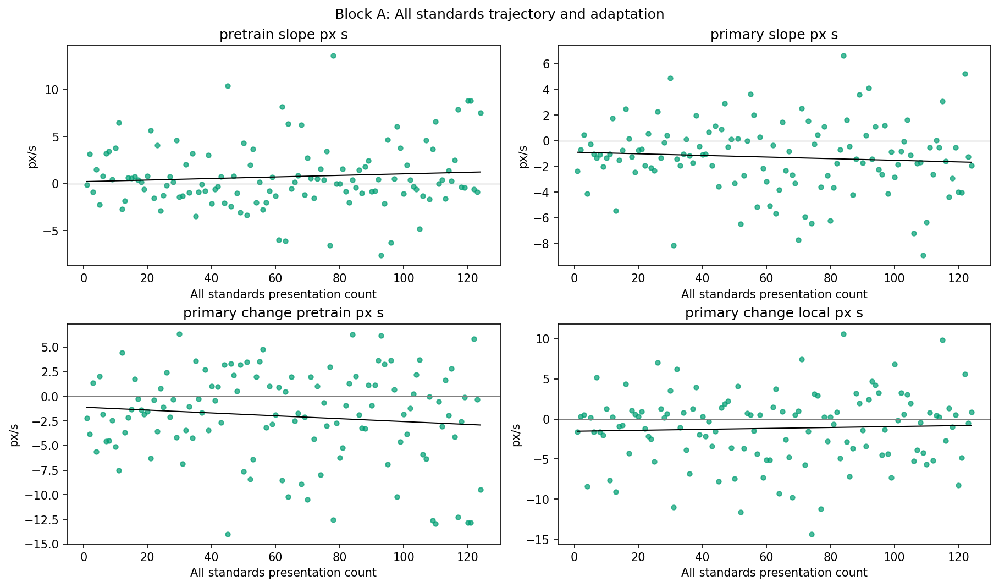
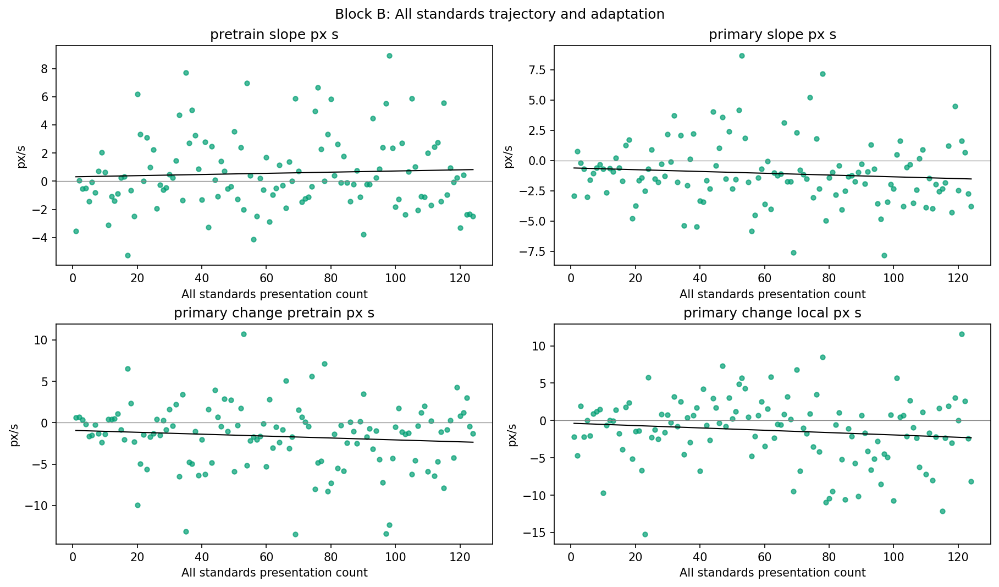


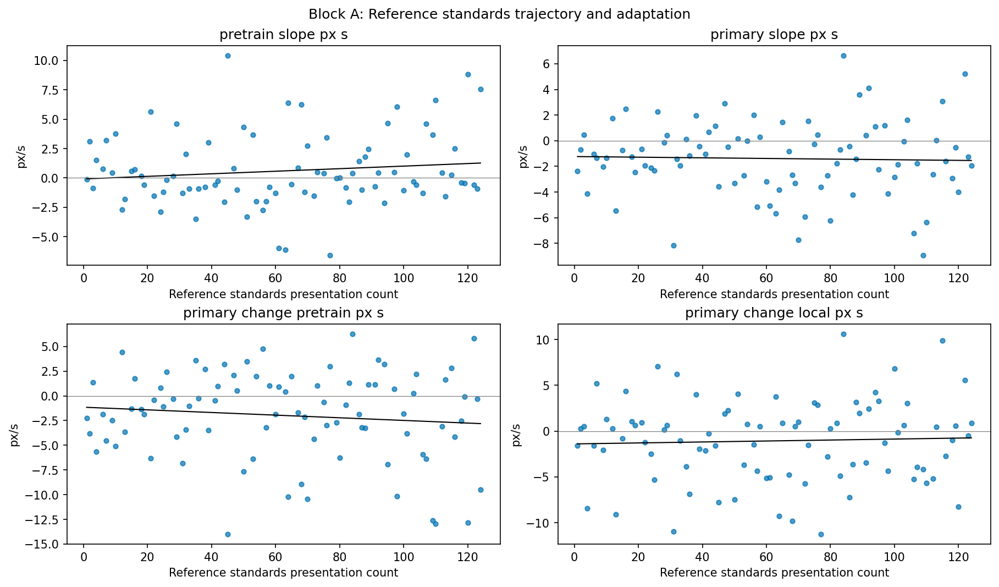
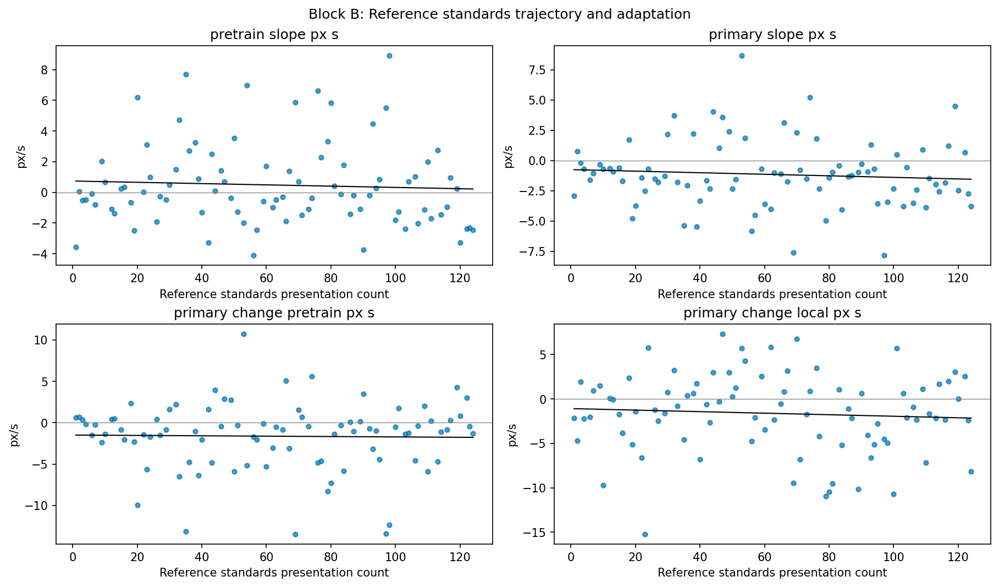


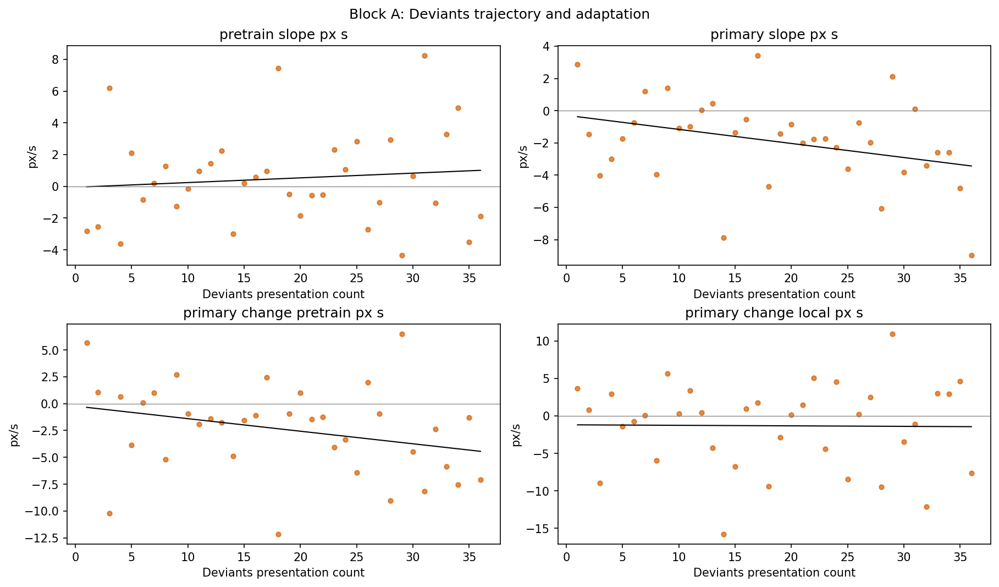
...
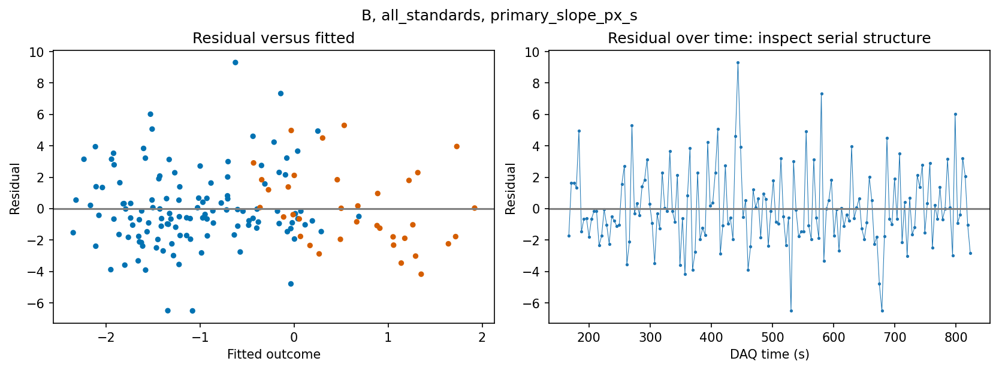


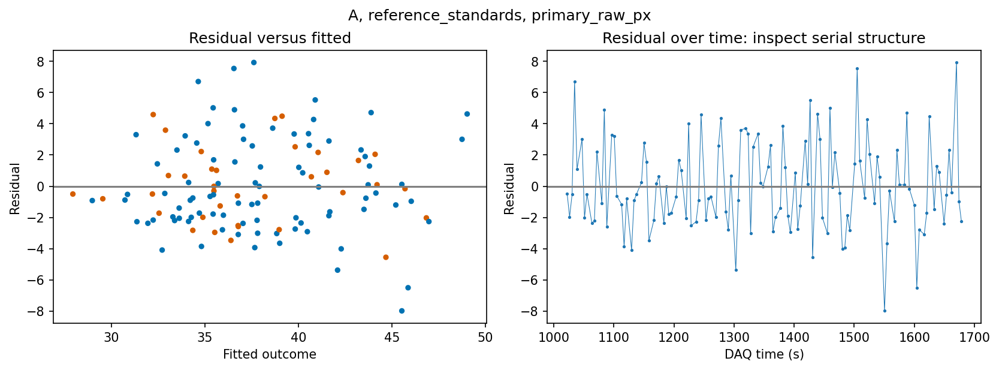
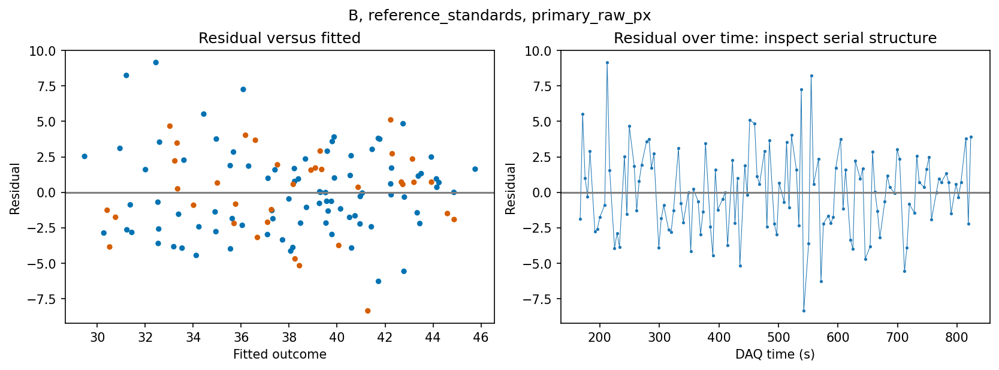


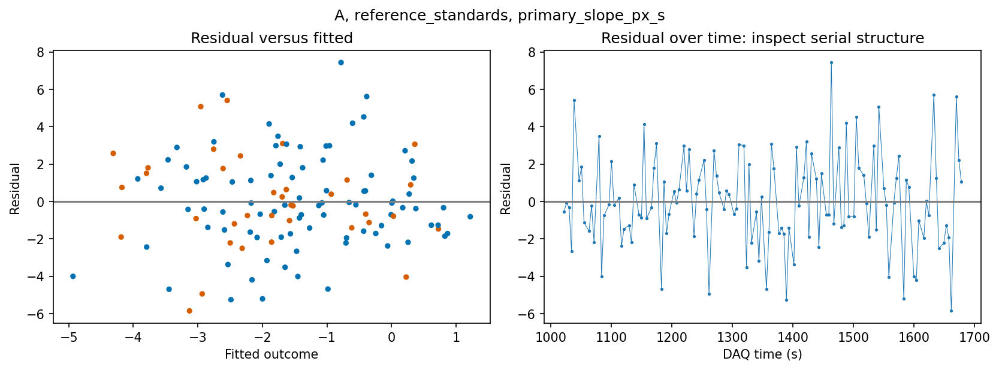
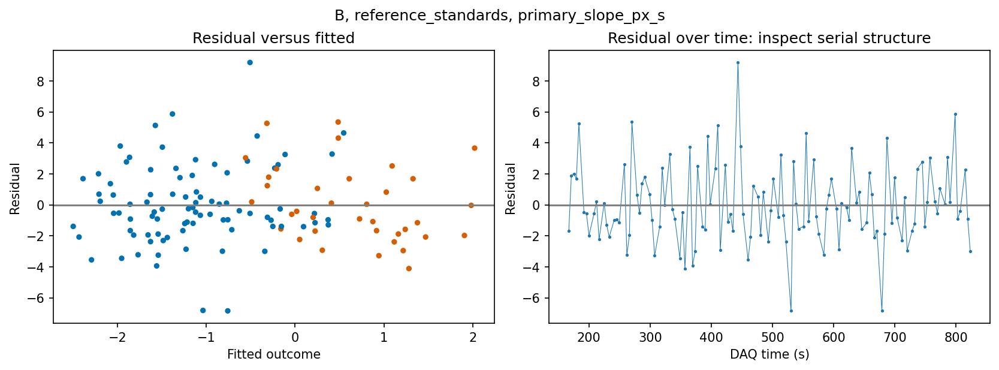

In [20]:
def fitted_slope(row, anchor, window, pretrain=False):
    lo, hi = window
    if not lo < hi:
        raise ValueError('Slope window must have positive duration.')
    a,b = row[anchor]+lo, row[anchor]+hi
    reason='accepted'
    if np.isfinite(row.next_train_start_s) and b >= row.next_train_start_s-NEXT_TRAIN_GUARD_S:
        reason='overlaps_next_train'
    if pretrain and np.isfinite(row.previous_train_end_s) and a < row.previous_train_end_s:
        reason='overlaps_previous_train'
    q=grid_between(a,b);v=bounded_sample(q);good=np.isfinite(v)
    cov=float(good.mean());frac=filled_fraction(a,b)
    mincov=MIN_BASELINE_COVERAGE if pretrain else MIN_METRIC_COVERAGE
    maxfill=MAX_BASELINE_INTERPOLATED_FRACTION if pretrain else MAX_RESPONSE_INTERPOLATED_FRACTION
    if reason=='accepted' and (good.sum()<3 or cov<mincov or (np.isfinite(frac) and frac>maxfill)):
        reason='tracking_quality'
    slope=r2=np.nan
    if reason=='accepted':
        fit=stats.linregress(q[good]-row[anchor],v[good]);slope=float(fit.slope);r2=float(fit.rvalue**2)
    return slope,r2,cov,frac,reason

trajectory=metrics.copy()
# Shift using chronological order, including block transitions.
ordered=metrics.sort_values('train_start_s')
trajectory['previous_train_end_s']=ordered.train_end_s.shift().reindex(metrics.index)
trajectory['previous_gap_s']=trajectory.train_start_s-trajectory.previous_train_end_s
trajectory['main_presentation_number']=np.nan
for (block,kind),group in trajectory.loc[trajectory.phase.eq('main')].groupby(['block','is_deviant']):
    ids=group.sort_values('train_start_s').index
    trajectory.loc[ids,'main_presentation_number']=np.arange(1,len(ids)+1)
windows={'pretrain':('train_start_s',BASELINE_TRAIN_S),
         'pre3':('stimulus3_start_s',PRE3_SLOPE_WINDOW_S),
         **{key:('stimulus3_start_s',value) for key,value in POST3_SLOPE_WINDOWS.items()}}
for i,row in trajectory.iterrows():
    for label,(anchor,window) in windows.items():
        slope,r2,cov,frac,reason=fitted_slope(row,anchor,window,label=='pretrain')
        for suffix,value in [('slope_px_s',slope),('r2',r2),('coverage',cov),('filled_fraction',frac),('reason',reason),('ok',reason=='accepted')]:
            trajectory.at[i,label+'_'+suffix]=value
for key in POST3_SLOPE_WINDOWS:
    trajectory[key+'_change_pretrain_px_s']=trajectory[key+'_slope_px_s']-trajectory.pretrain_slope_px_s
    trajectory[key+'_change_local_px_s']=trajectory[key+'_slope_px_s']-trajectory.pre3_slope_px_s
trajectory.to_csv(analysis_dir/'trajectory_trial_metrics.csv',index=False)

slope_measures=['pretrain_slope_px_s','pre3_slope_px_s','primary_slope_px_s',
                'primary_change_pretrain_px_s','primary_change_local_px_s']
slope_summary=[];adaptation=[]
for block in ['A','B']:
    b=trajectory.loc[trajectory.block.eq(block)&trajectory.phase.eq('main')]
    groups={'All standards':b.loc[b.is_standard], 'Reference standards':b.loc[b.reference_standard], 'Deviants':b.loc[b.is_deviant]}
    colors={'All standards':'#009E73','Reference standards':'#0072B2','Deviants':'#D55E00'}
    for label,frame in groups.items():
        fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
        for ax,col in zip(axes.flat,['pretrain_slope_px_s','primary_slope_px_s','primary_change_pretrain_px_s','primary_change_local_px_s']):
            good=frame.dropna(subset=[col,'main_presentation_number'])
            x=good.main_presentation_number.to_numpy(float);v=good[col].to_numpy(float)
            ax.scatter(x,v,s=16,color=colors[label],alpha=.7)
            trend=np.nan
            if len(v)>=3 and np.ptp(x)>0:
                fit=stats.linregress(x,v);trend=fit.slope;ax.plot(x,fit.intercept+trend*x,color='black',lw=1)
            maxcount=frame.main_presentation_number.max()
            early=good.loc[good.main_presentation_number<=maxcount/3,col]
            late=good.loc[good.main_presentation_number>2*maxcount/3,col]
            adaptation.append(dict(block=block,condition=label,measure=col,n=len(v),trend_per_presentation=trend,
                                   early_n=len(early),late_n=len(late),early_mean=early.mean(),late_mean=late.mean(),late_minus_early=late.mean()-early.mean()))
            ax.axhline(0,color='gray',lw=.6);ax.set(title=col.replace('_',' '),xlabel=label+' presentation count',ylabel='px/s')
        fig.suptitle(f'Block {block}: {label} trajectory and adaptation')
        finish_plot(block+'_'+label.replace(' ','_')+'_slope_adaptation')
    # Both slope changes use identical rows for pre/post diagnostic summaries.
    for ref in ['All standards','Reference standards']:
        fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
        for ax,key in zip(axes,['early','primary']):
            required=['pretrain_slope_px_s','pre3_slope_px_s',key+'_slope_px_s']
            for j,label in enumerate([ref,'Deviants']):
                good=groups[label].dropna(subset=required)
                for col in required+[key+'_change_pretrain_px_s',key+'_change_local_px_s']:
                    slope_summary.append(dict(block=block,reference=ref,condition=label,measure=col,n=len(good),mean=good[col].mean(),std=good[col].std()))
                for offset,col in [(-.15,key+'_change_pretrain_px_s'),(.15,key+'_change_local_px_s')]:
                    v=good[col].to_numpy(float)
                    ax.scatter(np.full(len(v),j+offset),v,s=12,alpha=.35,color=colors[label])
                    if len(v):ax.plot([j+offset-.08,j+offset+.08],[v.mean()]*2,color='black',lw=2)
            ax.set_xticks([0,1],[ref,'Deviants']);ax.axhline(0,color='gray',lw=.6)
            ax.set(title=key+': left = pre-train; right = local slope change',ylabel='Post slope − pre slope (px/s)')
        finish_plot(block+'_'+ref.replace(' ','_')+'_slope_comparison')
slope_summary=pd.DataFrame(slope_summary);adaptation=pd.DataFrame(adaptation)
slope_summary.to_csv(analysis_dir/'slope_condition_summary.csv',index=False)
adaptation.to_csv(analysis_dir/'slope_adaptation_summary.csv',index=False)
display(slope_summary);display(adaptation)


# Differences computed from the matched pre/post rows in the summary above.
contrast_rows=[]
for (block,reference,measure),g in slope_summary.groupby(['block','reference','measure']):
    standard=g.loc[g.condition.eq(reference)]
    deviant=g.loc[g.condition.eq('Deviants')]
    if len(standard) and len(deviant):
        contrast_rows.append(dict(block=block,reference=reference,measure=measure,
            n_standard=int(standard.iloc[0]['n']),n_deviant=int(deviant.iloc[0]['n']),
            deviant_minus_standard=deviant.iloc[0]['mean']-standard.iloc[0]['mean']))
slope_contrasts=pd.DataFrame(contrast_rows)
slope_contrasts.to_csv(analysis_dir/'slope_deviant_minus_standard_contrasts.csv',index=False)
if len(slope_contrasts):
    between=slope_contrasts.pivot(index=['reference','measure'],columns='block',values='deviant_minus_standard')
    if {'A','B'}.issubset(between.columns):between['B_minus_A_contrast']=between.B-between.A
    between.to_csv(analysis_dir/'slope_cross_block_difference_of_contrasts.csv');display(between)

# Cross-block comparison: raw points/means, and progress for different condition rates.
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
cross=[]
for ax,col in zip(axes,['primary_change_pretrain_px_s','primary_change_local_px_s']):
    for j,(block,label) in enumerate([(b,l) for b in ['A','B'] for l in ['Reference standards','Deviants']]):
        g=trajectory.loc[trajectory.block.eq(block)&trajectory.phase.eq('main')]
        g=g.loc[g.reference_standard if label=='Reference standards' else g.is_deviant]
        v=g[col].dropna();ax.scatter(np.full(len(v),j),v,s=12,alpha=.4)
        if len(v):ax.plot([j-.2,j+.2],[v.mean()]*2,color='black',lw=2)
        cross.append(dict(block=block,condition=label,measure=col,n=len(v),mean=v.mean()))
    ax.set_xticks(range(4),['A standard','A deviant','B standard','B deviant'],rotation=20)
    ax.set(title=col.replace('_',' '),ylabel='px/s');ax.axhline(0,color='gray',lw=.6)
finish_plot('cross_block_slope_changes')
cross=pd.DataFrame(cross);cross.to_csv(analysis_dir/'cross_block_slope_summary.csv',index=False)
wide=cross.pivot(index=['condition','measure'],columns='block',values='mean')
if {'A','B'}.issubset(wide.columns):wide['B_minus_A']=wide.B-wide.A
wide.to_csv(analysis_dir/'cross_block_slope_contrasts.csv');display(wide)
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,kind in zip(axes,[False,True]):
    for block in ['A','B']:
        g=trajectory.loc[trajectory.block.eq(block)&trajectory.phase.eq('main')&trajectory.is_deviant.eq(kind)]
        total=g.main_presentation_number.max();good=g.dropna(subset=['primary_change_local_px_s'])
        x=good.main_presentation_number/total;v=good.primary_change_local_px_s
        ax.scatter(x,v,s=13,alpha=.4,label=block)
        if len(v)>=3 and x.nunique()>1:
            fit=stats.linregress(x,v);ax.plot(x,fit.intercept+fit.slope*x)
    ax.axhline(0,color='gray',lw=.6);ax.set(title='Deviants' if kind else 'All standards',xlabel='Fraction of condition presentations',ylabel='Local slope change (px/s)');ax.legend()
finish_plot('cross_block_normalized_progress')
c_summary=trajectory.loc[trajectory.block.eq('C')].groupby('sequence')[slope_measures].agg(['count','mean','std'])
c_summary.to_csv(analysis_dir/'C_sequence_slope_summary.csv');display(c_summary)

# Same-row unadjusted and adjusted comparisons. No within-session inferential tests.
model_rows=[];model_coefficients=[];model_trials=[]
for block in ['A','B']:
    b=trajectory.loc[trajectory.block.eq(block)&trajectory.phase.eq('main')].copy()
    for reference in ['all_standards','reference_standards']:
        selected=b.loc[b.is_deviant | (b.is_standard if reference=='all_standards' else b.reference_standard)].copy()
        for outcome in ['primary_raw_px','primary_slope_px_s']:
            good=selected.loc[selected.primary_ok & selected.pretrain_ok.astype(bool)].dropna(
                subset=[outcome,'baseline_pd_px','pretrain_slope_px_s','previous_gap_s']).copy()
            status='insufficient_trials';beta=None;names=[];condition=np.nan;rank=0
            if len(good) and good.is_deviant.nunique()==2:
                nuisance=pd.DataFrame({'pre_level':good.baseline_pd_px,'pre_slope':good.pretrain_slope_px_s,
                    'block_time':good.train_start_s-good.train_start_s.min(),
                    'previous_deviant':good.previous_is_deviant.astype(float),'previous_gap':good.previous_gap_s},index=good.index)
                varying=nuisance.std(ddof=0)>1e-10
                z=(nuisance.loc[:,varying]-nuisance.loc[:,varying].mean())/nuisance.loc[:,varying].std(ddof=0)
                names=['intercept','deviant']+list(z.columns)
                X=np.column_stack([np.ones(len(good)),good.is_deviant.astype(float),z]);target=good[outcome].to_numpy(float)
                rank=int(np.linalg.matrix_rank(X));condition=float(np.linalg.cond(X))
                if len(good)>=X.shape[1]+5 and rank==X.shape[1]:
                    beta=np.linalg.lstsq(X,target,rcond=None)[0];status='descriptive_fit'
                    prediction=X@beta;residual=target-prediction
                    for name,value in zip(names,beta):model_coefficients.append(dict(block=block,reference=reference,outcome=outcome,predictor=name,coefficient=value))
                    good['model_prediction']=prediction;good['model_residual']=residual;good['model_outcome']=outcome;good['model_reference']=reference;model_trials.append(good)
                    fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
                    axes[0].scatter(prediction,residual,s=12,c=good.is_deviant.map({False:'#0072B2',True:'#D55E00'}));axes[0].axhline(0,color='gray');axes[0].set(xlabel='Fitted outcome',ylabel='Residual',title='Residual versus fitted')
                    axes[1].plot(good.train_start_s,residual,'.-',ms=3,lw=.5);axes[1].axhline(0,color='gray');axes[1].set(xlabel='DAQ time (s)',ylabel='Residual',title='Residual over time: inspect serial structure')
                    fig.suptitle(f'{block}, {reference}, {outcome}');finish_plot(block+'_'+reference+'_'+outcome+'_adjustment_QC')
                else:status='insufficient_trials_or_rank_deficient'
            s=good.loc[~good.is_deviant];d=good.loc[good.is_deviant]
            model_rows.append(dict(block=block,reference=reference,outcome=outcome,n_standard=len(s),n_deviant=len(d),
                unadjusted_contrast=d[outcome].mean()-s[outcome].mean(),
                pretrain_corrected_contrast=d.primary_delta_px.mean()-s.primary_delta_px.mean() if outcome=='primary_raw_px' else np.nan,
                adjusted_contrast=beta[1] if beta is not None else np.nan,rank=rank,condition_number=condition,status=status))
model_summary=pd.DataFrame(model_rows);display(model_summary)
model_summary.to_csv(analysis_dir/'starting_state_adjusted_contrasts.csv',index=False)
pd.DataFrame(model_coefficients).to_csv(analysis_dir/'starting_state_model_coefficients.csv',index=False)
if model_trials:pd.concat(model_trials).to_csv(analysis_dir/'starting_state_model_trials.csv',index=False)

show_grouped_plots()


## II.8. Standard versus deviant and all response windows (ideas 6–7)

**Question:** is the response following sequence divergence different from an expected repeated sequence? Compare main standards and deviants at the SAME third-stimulus position. Standards after a deviant are shown descriptively but excluded from the default reference according to the history setting. Train-aligned and stimulus-3-aligned plots, condition heatmaps, a difference waveform, and signed mean outcomes are saved. Negative differences are retained. The post-train outcome uses the same pre-train baseline; it is not re-zeroed at train end.

Default 1–1.5 s after train end corresponds to 1.92–2.42 s after stimulus 3 for this schematic. The next train is at 3.07 s after stimulus 3. Actual times and next-train guards override nominal arithmetic.


count      mean       std
block phase   sequence                           
A     fixed   AAAA         15 -0.117245  3.217160
      main    AAAA        124  0.272835  3.675760
              AABA         36 -0.928057  3.491476
      warmup  AAAA         25  0.232793  3.354767
B     fixed   BBBB         15  0.377653  3.172617
      main    BBAB         36 -0.120605  3.122550
              BBBB        124  0.125704  3.365625
      warmup  BBBB         24 -1.093337  4.244475
C     control AAAA         60  0.101343  4.219997
              AABA         60 -0.238082  3.810925
              BBAB         60  0.519541  4.502657
              BBBB         60  0.099555  4.452446


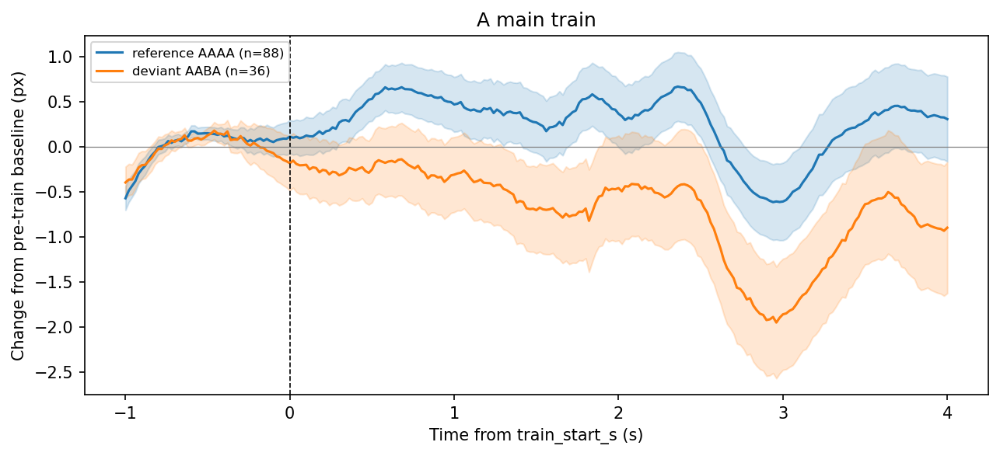
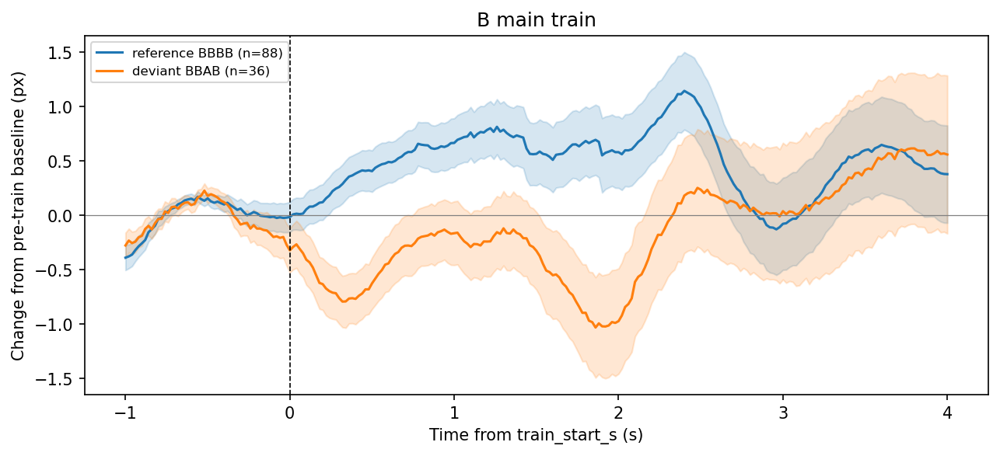


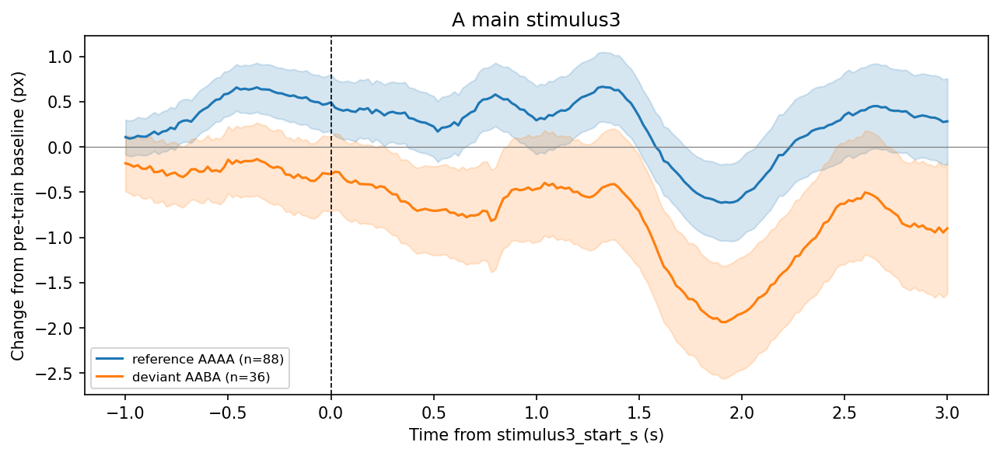
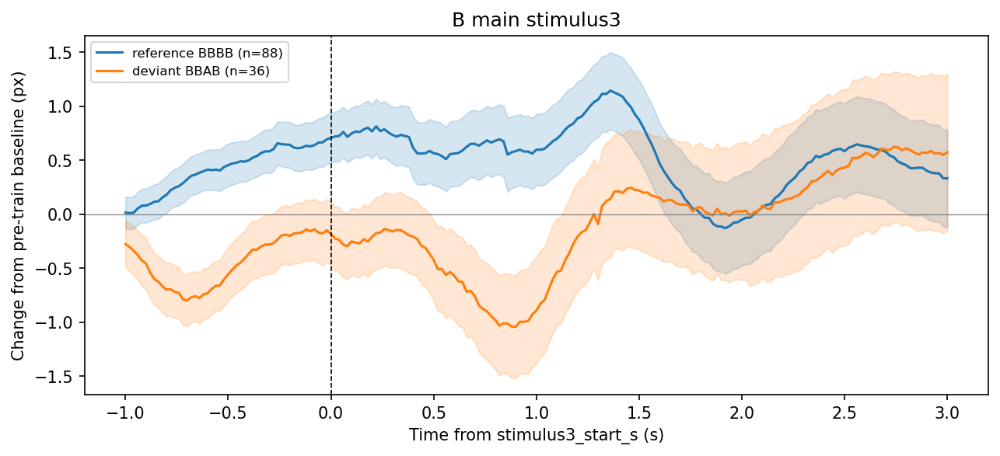


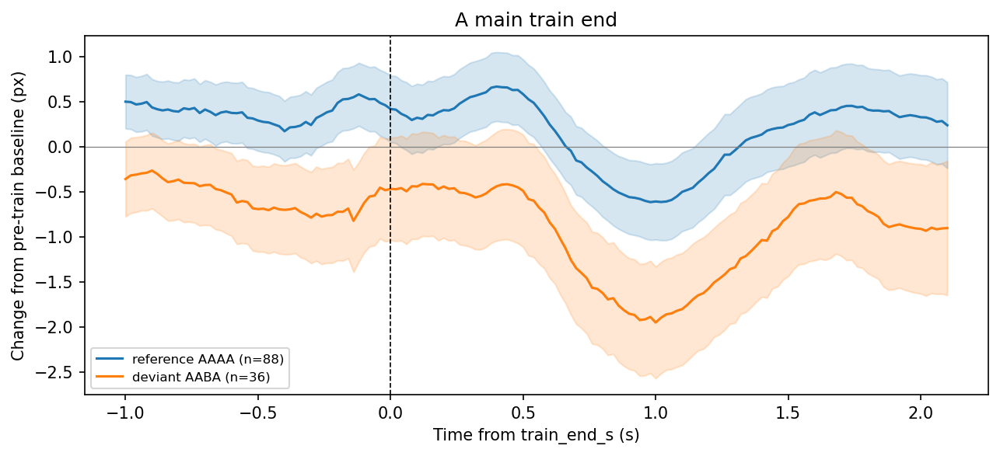
...
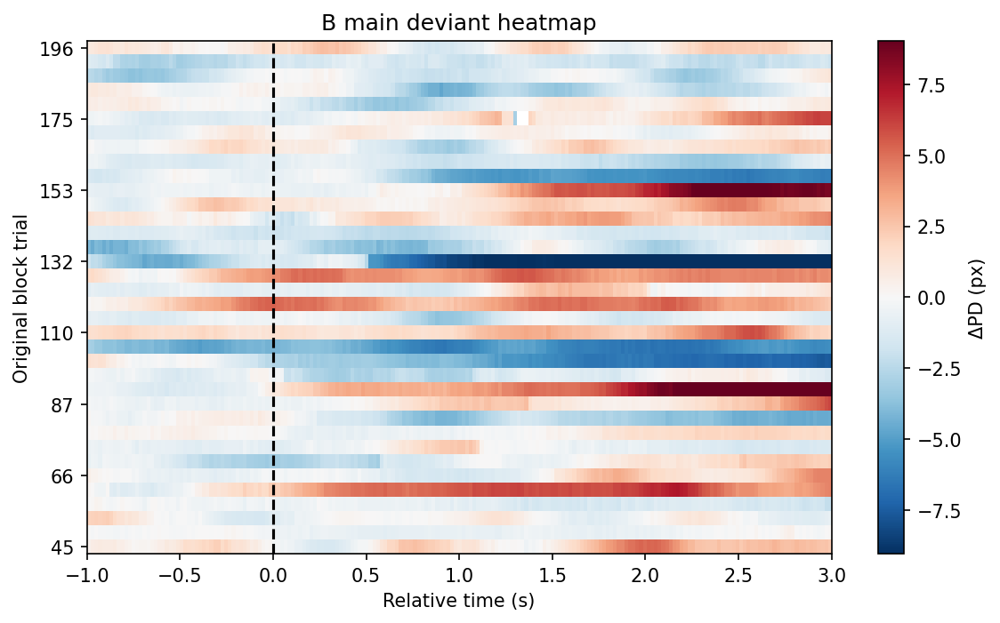


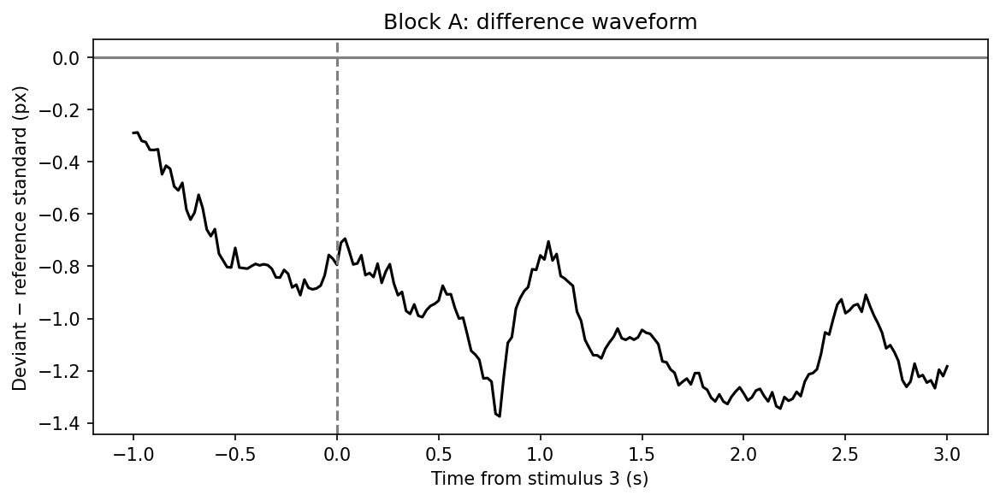
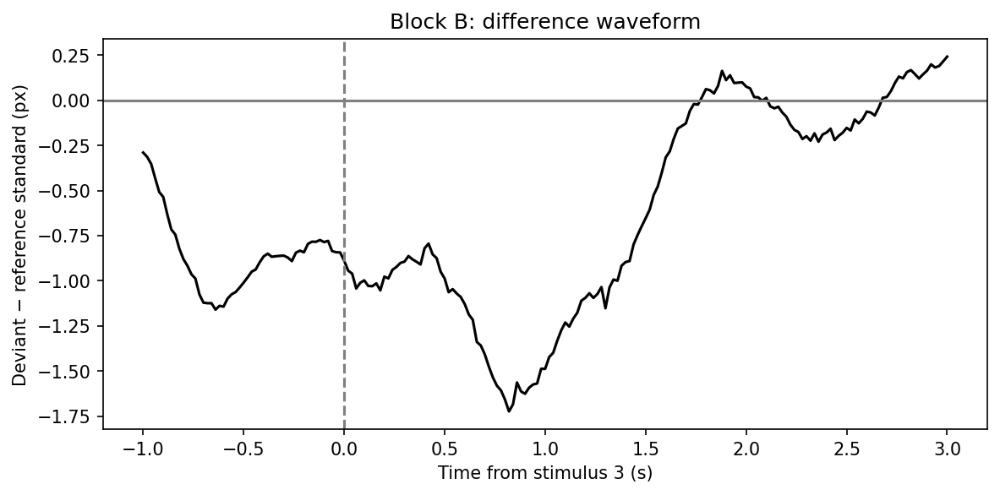


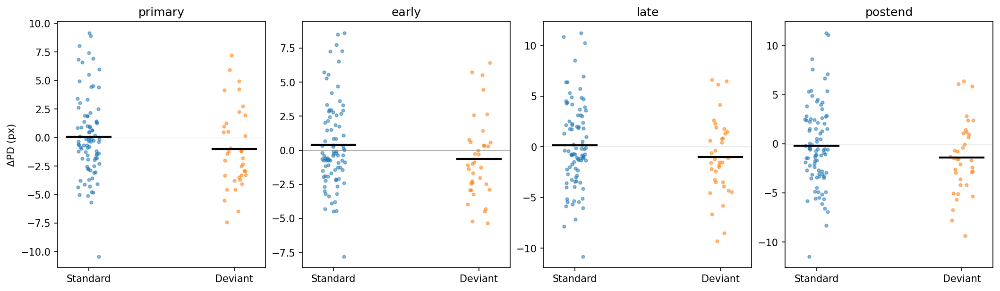
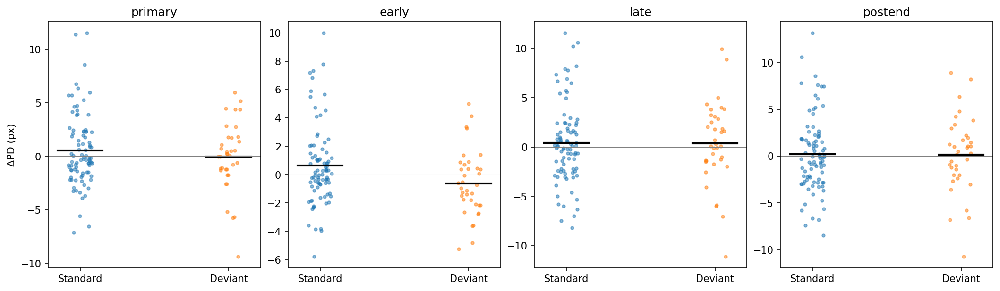

In [21]:
condition_summaries=[]
for block in ['A','B']:
    b=metrics.loc[metrics.block.eq(block)&metrics.phase.eq('main')]
    std=b.loc[b.reference_standard];dev=b.loc[b.is_deviant]
    if b.empty:continue
    names={'reference '+('AAAA' if block=='A' else 'BBBB'):std,'deviant '+('AABA' if block=='A' else 'BBAB'):dev}
    curves(names,f'{block}_main_train','train_start_s',TRAIN_PLOT_WINDOW_S)
    curves(names,f'{block}_main_stimulus3')
    curves(names,f'{block}_main_train_end','train_end_s',(-1.0,2.10))
    heatmap(std,f'{block}_main_standard_heatmap');heatmap(dev,f'{block}_main_deviant_heatmap')
    gs,ms,_=waveform(std);gd,mdv,_=waveform(dev)
    if len(ms) and len(mdv):
        sm,_,sn=nan_summary(ms);dm,_,dn=nan_summary(mdv)
        fig,ax=plt.subplots(figsize=(9,4));ax.plot(gs,dm-sm,color='black');ax.axhline(0,color='gray');ax.axvline(0,color='gray',ls='--')
        ax.set(xlabel='Time from stimulus 3 (s)',ylabel='Deviant − reference standard (px)',title=f'Block {block}: difference waveform')
        pd.DataFrame({'relative_time_s':gs,'deviant_minus_standard_px':dm-sm,'n_standard':sn,'n_deviant':dn}).to_csv(analysis_dir/f'{block}_difference_waveform.csv',index=False)
        finish_plot(f'{block}_difference_waveform')
    fig,axes=plt.subplots(1,4,figsize=(14,4),constrained_layout=True)
    for ax,key in zip(axes,[*STIM3_WINDOWS,'postend']):
        vals=[std.loc[std[key+'_ok'],key+'_delta_px'].to_numpy(),dev.loc[dev[key+'_ok'],key+'_delta_px'].to_numpy()]
        for j,v in enumerate(vals):
            ax.scatter(np.full(len(v),j)+rng.uniform(-.08,.08,len(v)),v,s=9,alpha=.5)
            if len(v):ax.plot([j-.15,j+.15],[v.mean()]*2,color='black',lw=2)
        ax.set_xticks([0,1],['Standard','Deviant']);ax.set_title(key);ax.axhline(0,color='gray',lw=.5)
        for label,values in zip(['reference_standard','deviant'],vals):condition_summaries.append(dict(block=block,condition=label,metric=key,n=len(values),mean_delta_px=float(np.mean(values)) if len(values) else np.nan))
    axes[0].set_ylabel('ΔPD (px)');finish_plot(f'{block}_window_metrics')
pd.DataFrame(condition_summaries).to_csv(analysis_dir/'standard_deviant_window_summary.csv',index=False)

# Immediate post-end secondary summary; each train retains its own pre-train baseline.
immediate_summary=metrics.loc[metrics.immediate_postend_ok].groupby(['block','phase','sequence']).immediate_postend_delta_px.agg(['count','mean','std'])
display(immediate_summary)
immediate_summary.to_csv(analysis_dir/'immediate_postend_summary.csv')

show_grouped_plots()


## II.9. Trial-history and nearby-standard sensitivity (idea 8)

**Question:** does preceding deviance change the starting state or the response of subsequent standards? Compare the first post-deviant standard with later main standards; keep their pre-train traces, baseline diameter/slope and primary response separate. Repeat contrasts excluding 0, 1 or 2 post-deviant standards. Compare deviants preceded by 3/4/5 standards and pair each deviant with up to two preceding eligible standards from the same block. Nearby matching reduces long-term drift but does not eliminate expectation or locomotion differences. Counts and pairing IDs are exported.



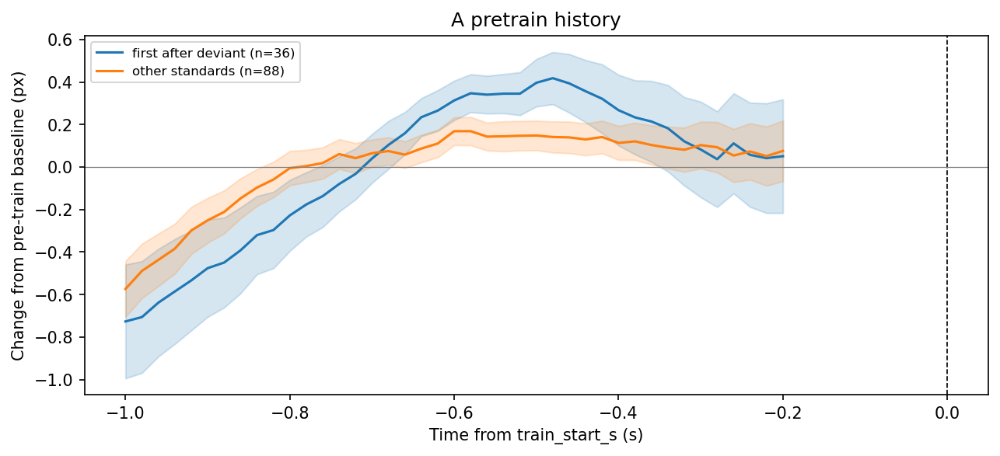
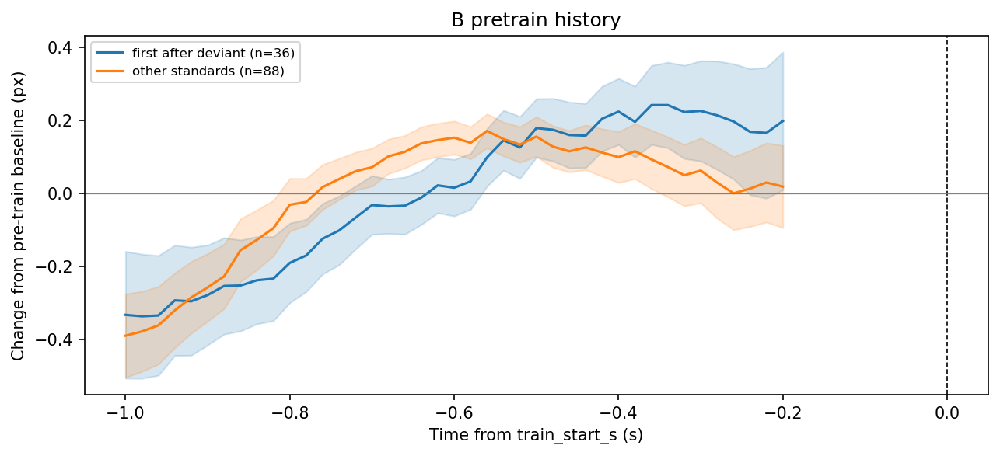


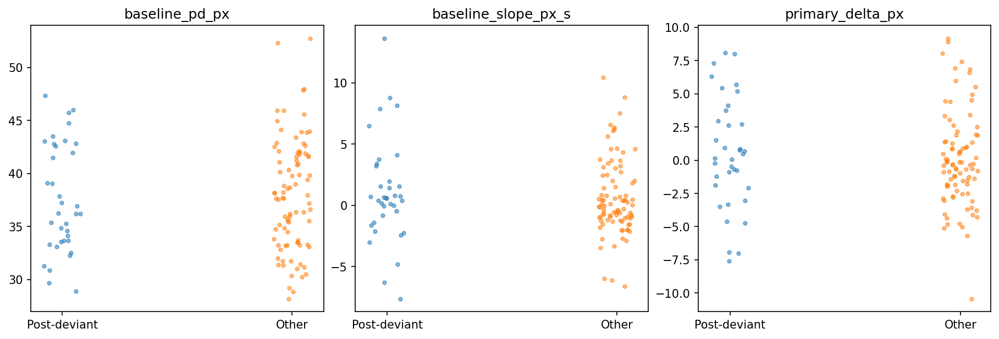
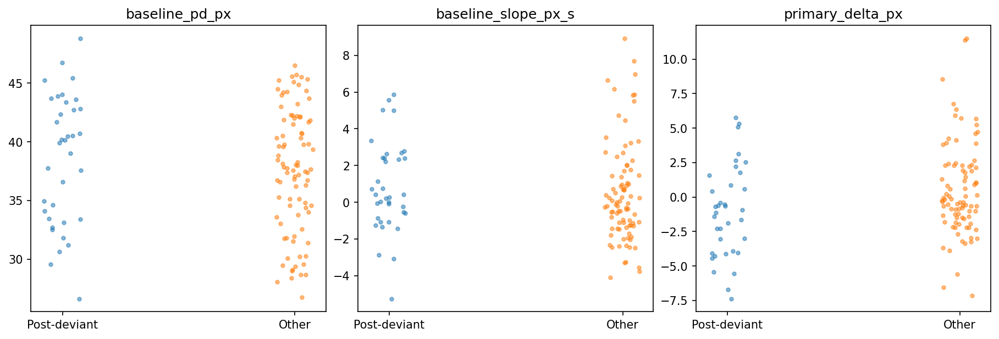


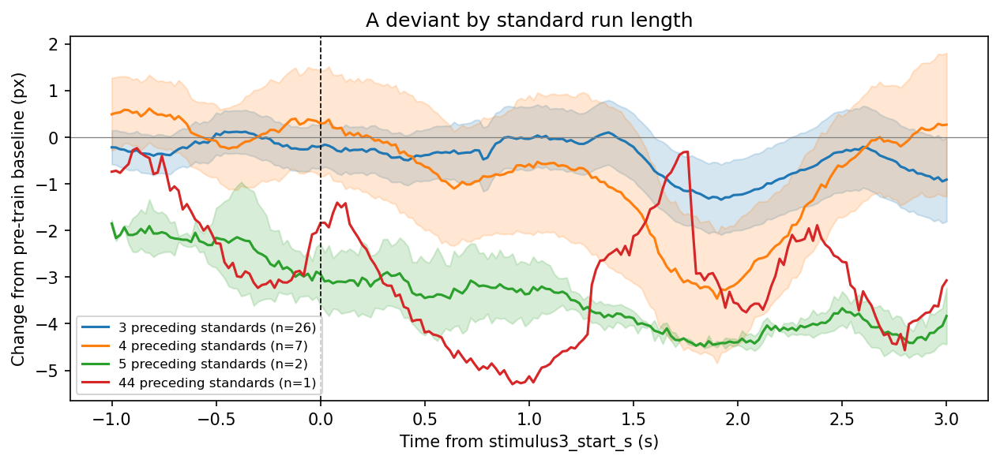
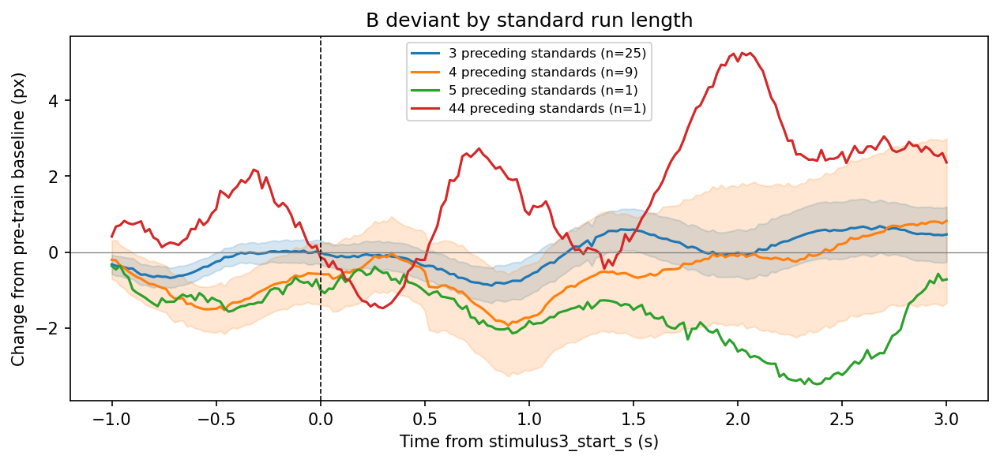

In [22]:
history_rows=[];nearby=[]
for block in ['A','B']:
    b=metrics.loc[metrics.block.eq(block)&metrics.phase.eq('main')]
    std=b.loc[b.is_standard];dev=b.loc[b.is_deviant]
    if b.empty:continue
    first=std.loc[std.previous_is_deviant];later=std.loc[~std.previous_is_deviant]
    curves({'first after deviant':first,'other standards':later},f'{block}_pretrain_history','train_start_s',BASELINE_TRAIN_S)
    fig,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
    for ax,col in zip(axes,['baseline_pd_px','baseline_slope_px_s','primary_delta_px']):
        values=[first.loc[first.baseline_ok if col!='primary_delta_px' else first.primary_ok,col].dropna(),later.loc[later.baseline_ok if col!='primary_delta_px' else later.primary_ok,col].dropna()]
        for j,v in enumerate(values):ax.scatter(np.full(len(v),j)+rng.uniform(-.08,.08,len(v)),v,s=10,alpha=.5)
        ax.set_xticks([0,1],['Post-deviant','Other']);ax.set_title(col)
    finish_plot(f'{block}_history_metrics')
    for exclude in [0,1,2]:
        selected=std.loc[~std.standard_position_after_deviant.between(1,exclude)]
        for key in [*STIM3_WINDOWS,'postend']:
            s=selected.loc[selected[key+'_ok'],key+'_delta_px'];d=dev.loc[dev[key+'_ok'],key+'_delta_px']
            history_rows.append(dict(block=block,excluded_first_n=exclude,metric=key,n_standard=len(s),n_deviant=len(d),contrast_px=d.mean()-s.mean()))
    groups={str(int(n))+' preceding standards':g for n,g in dev.groupby('standards_since_deviant') if np.isfinite(n)}
    if groups:curves(groups,f'{block}_deviant_by_standard_run_length')
    for i,row in dev.loc[dev.primary_ok].iterrows():
        candidates=std.loc[std.reference_standard&std.primary_ok&(std.train_start_s<row.train_start_s)].tail(NEARBY_STANDARD_COUNT)
        if len(candidates):nearby.append(dict(block=block,deviant_trial_id=int(row.trial_id),reference_trial_ids=';'.join(candidates.trial_id.astype(str)),n_reference=len(candidates),deviant_delta_px=row.primary_delta_px,reference_delta_px=candidates.primary_delta_px.mean(),paired_contrast_px=row.primary_delta_px-candidates.primary_delta_px.mean()))
pd.DataFrame(history_rows).to_csv(analysis_dir/'postdeviant_exclusion_sensitivity.csv',index=False)
pd.DataFrame(nearby).to_csv(analysis_dir/'nearby_standard_pairs.csv',index=False)

show_grouped_plots()


## II.10. Deviant-response adaptation (idea 9)

Plot primary response, baseline PD and baseline slope versus deviant presentation number within A and B separately. Export descriptive linear slopes. A response-versus-baseline correlation may arise partly from mathematical coupling/regression to the mean because baseline is subtracted from the response. Do not interpret such a correlation alone as physiological gain control. Plots retain original deviant numbers if trials are rejected.



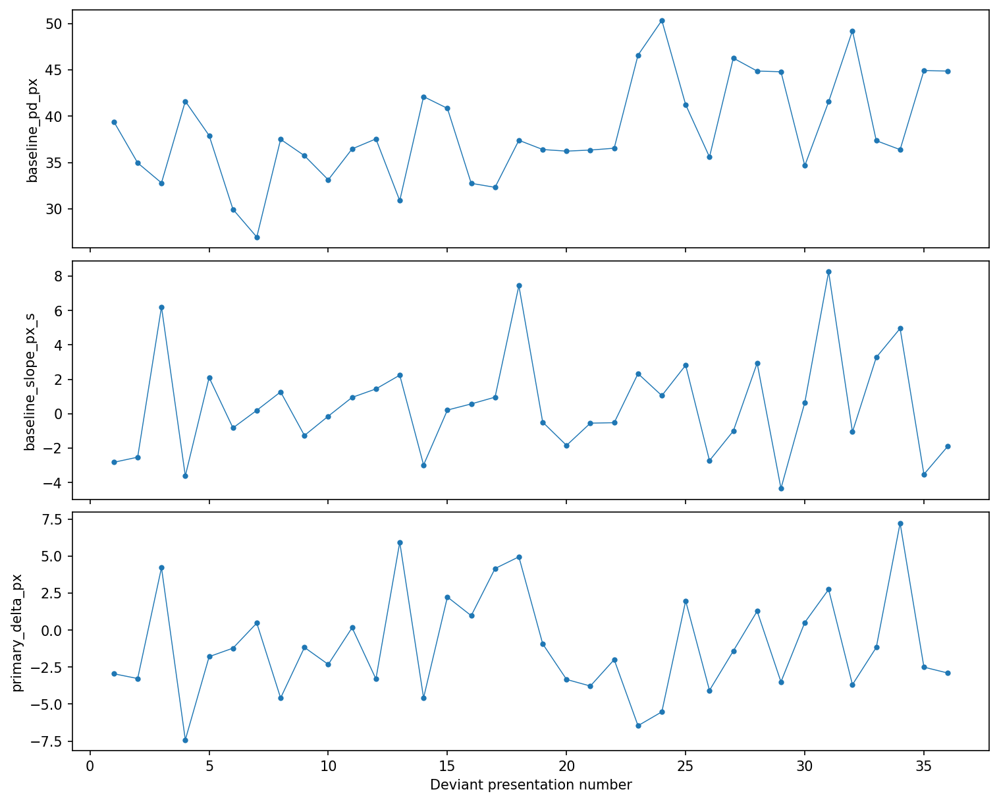
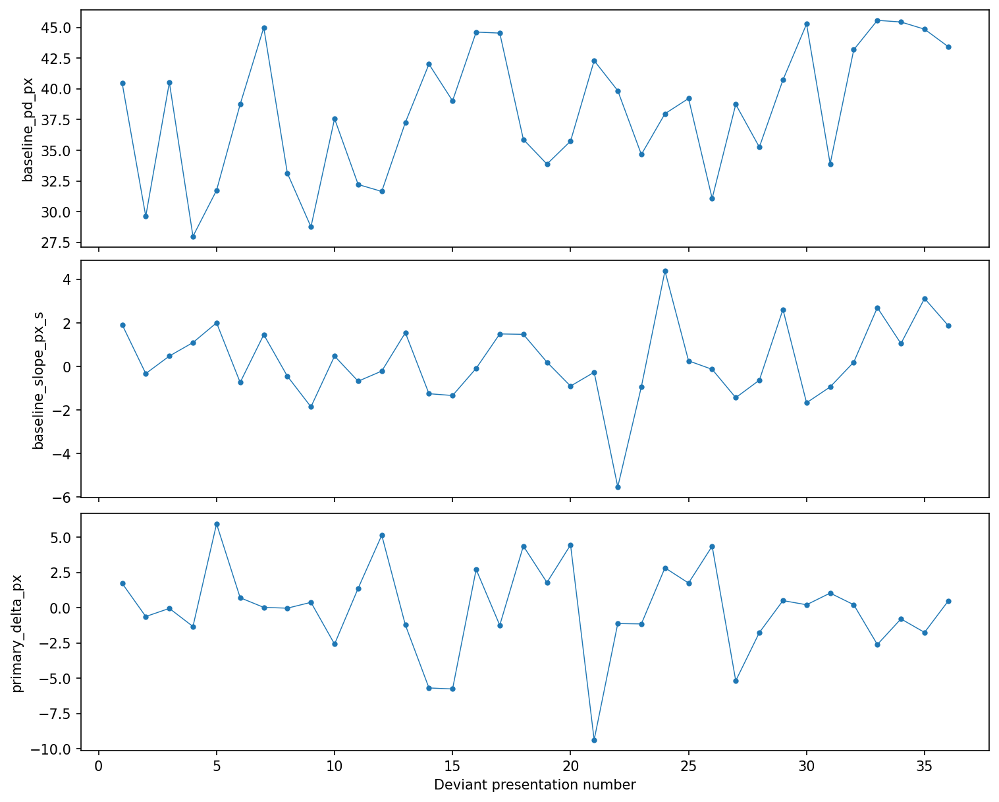

In [23]:
deviant_slopes=[]
for block in ['A','B']:
    d=metrics.loc[metrics.block.eq(block)&metrics.is_deviant]
    if d.empty:continue
    fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True,constrained_layout=True)
    for ax,col in zip(axes,['baseline_pd_px','baseline_slope_px_s','primary_delta_px']):
        good=d.loc[d.baseline_ok if col!='primary_delta_px' else d.primary_ok,['deviant_number',col]].dropna()
        ax.plot(good.deviant_number,good[col],'.-',lw=.7);ax.set_ylabel(col)
        slope=stats.linregress(good.deviant_number,good[col]).slope if len(good)>=3 else np.nan
        deviant_slopes.append(dict(block=block,measure=col,n=len(good),slope_per_deviant=slope))
    axes[-1].set_xlabel('Deviant presentation number');finish_plot(f'{block}_deviant_adaptation')
pd.DataFrame(deviant_slopes).to_csv(analysis_dir/'deviant_adaptation_slopes.csv',index=False)

show_grouped_plots()


## II.11. Equiprobable Block C and identical-sequence comparisons (ideas 10–12)

Show AAAA, AABA, BBBB and BBAB separately, using pre-train correction and third-stimulus alignment. Compare identical sequences between their context block and C. Compute context contrasts `(AABA−AAAA)_A − (AABA−AAAA)_C` and `(BBAB−BBBB)_B − (BBAB−BBBB)_C` for each outcome window. These contrasts are associations with context and sequence history, not isolated causal prediction-error measurements: C is always last and standard-reference exclusions alter the sampled history.


,mouse_id,session_id,block,metric,n_standard,n_deviant,n_control_standard,n_control_change,standard_deviant_contrast_px,context_contrast_px,identical_deviant_context_minus_C_px,identical_standard_context_minus_C_px
0,mouse_01,session_01,A,primary,88,36,60,60,-1.101442,-0.730774,-0.724445,0.006328
1,mouse_01,session_01,B,primary,88,36,60,60,-0.594076,-1.150083,-0.573140,0.576943
2,mouse_01,session_01,A,early,87,36,60,60,-1.033873,-0.820412,-0.461133,0.359279
3,mouse_01,session_01,B,early,87,36,60,60,-1.237346,-0.768996,-0.603930,0.165066
4,mouse_01,session_01,A,late,88,36,60,60,-1.165612,-1.171958,-0.919479,0.252479
5,mouse_01,session_01,B,late,88,36,60,60,-0.025227,-1.669110,-0.475958,1.193152
6,mouse_01,session_01,A,postend,88,36,60,60,-1.238397,-0.970599,-1.059844,-0.089245
7,mouse_01,session_01,B,postend,88,36,60,60,-0.055201,-1.438533,-0.264913,1.173620



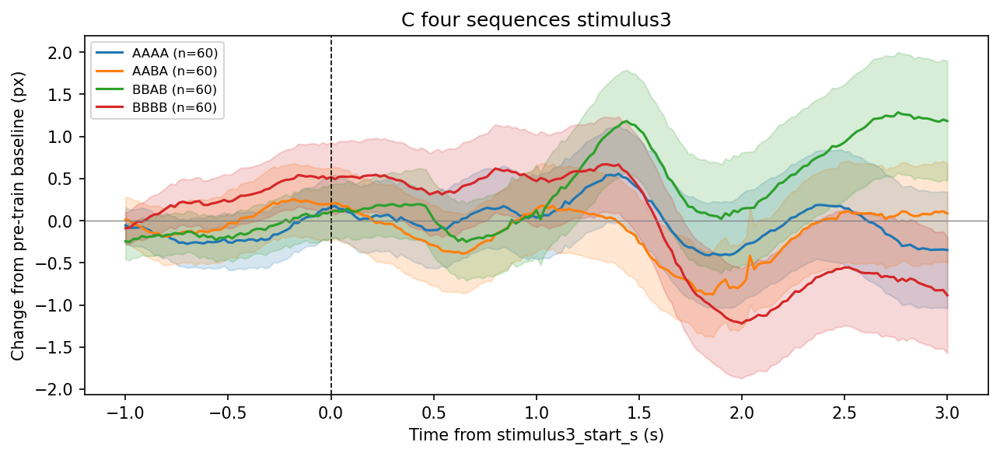


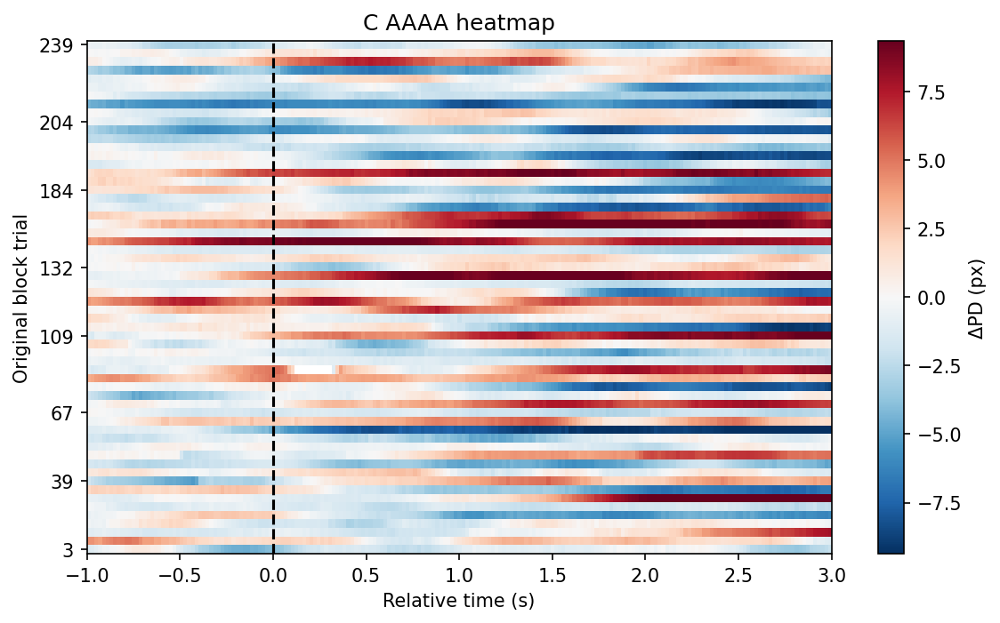
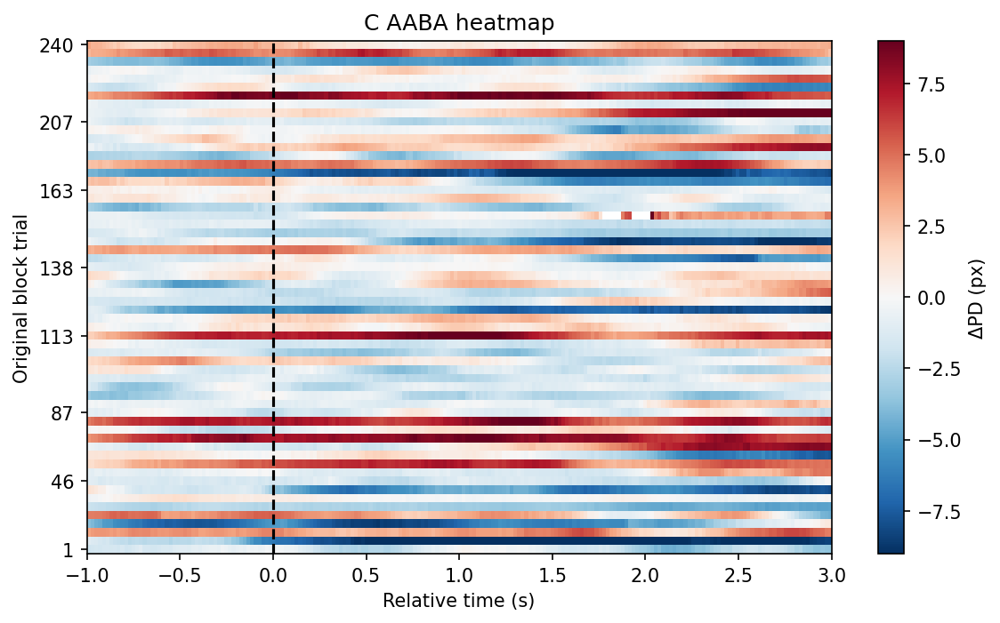
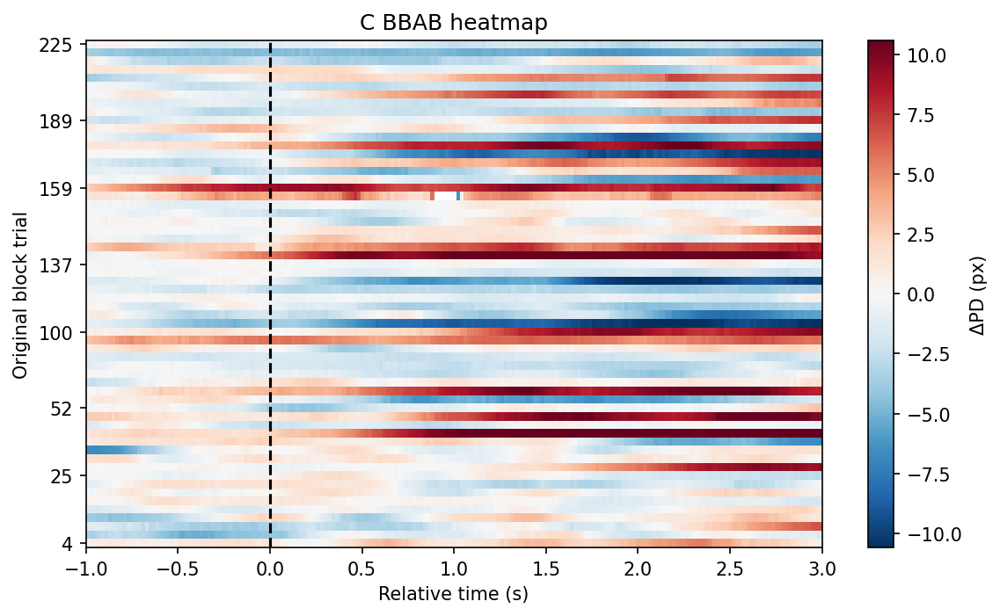
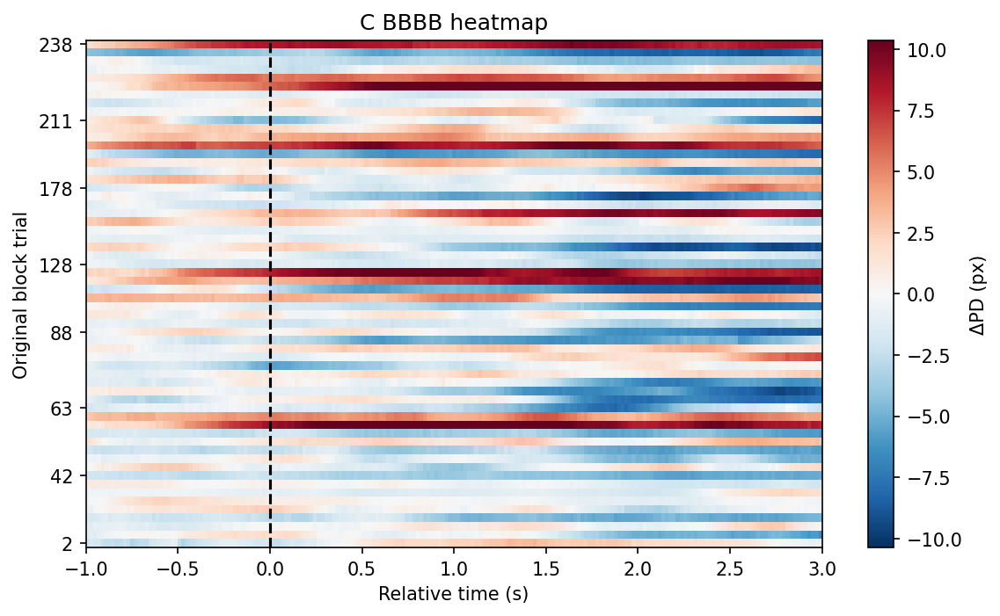


...
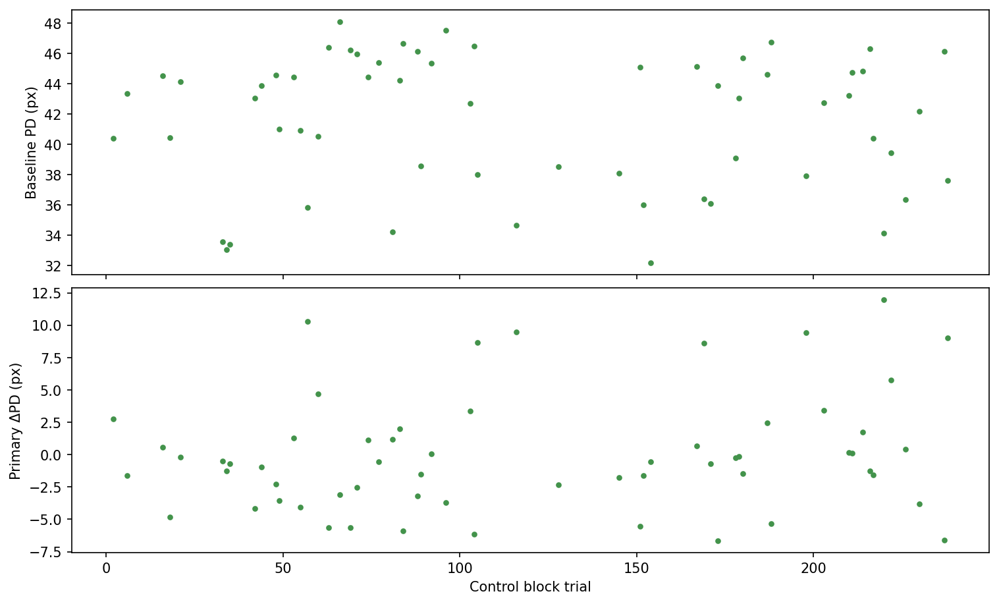


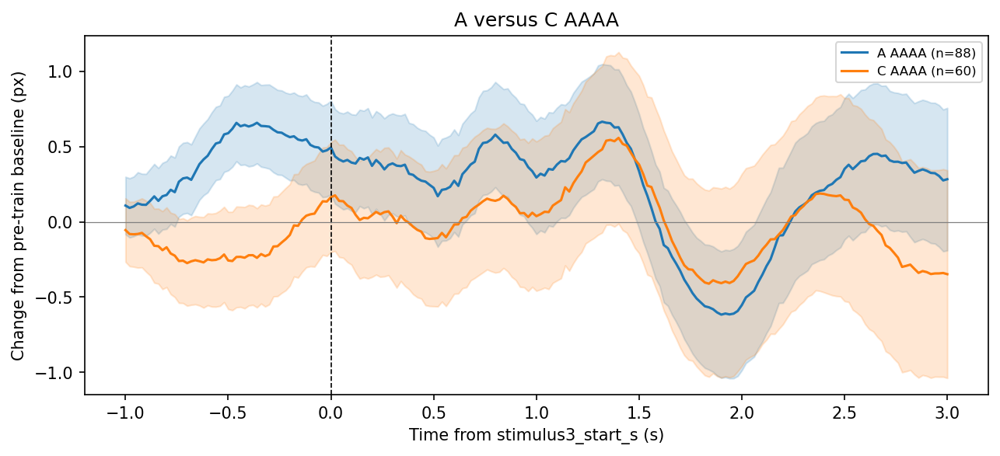


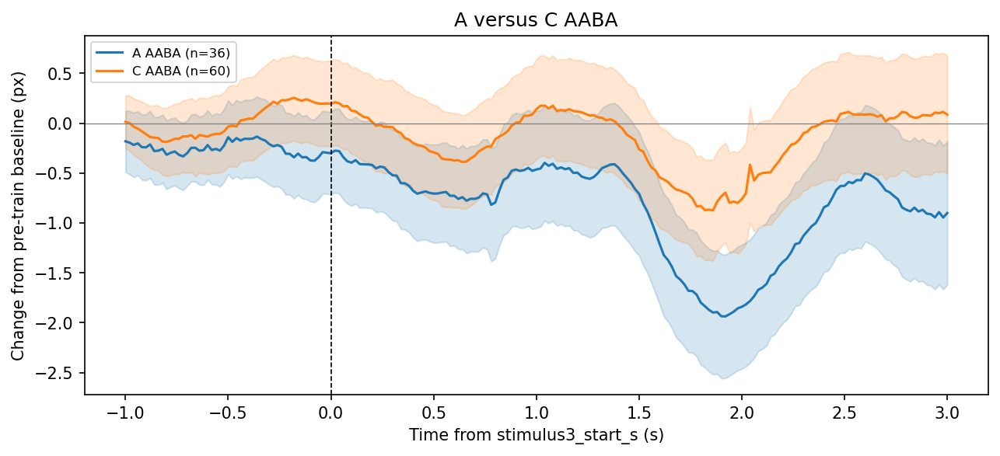


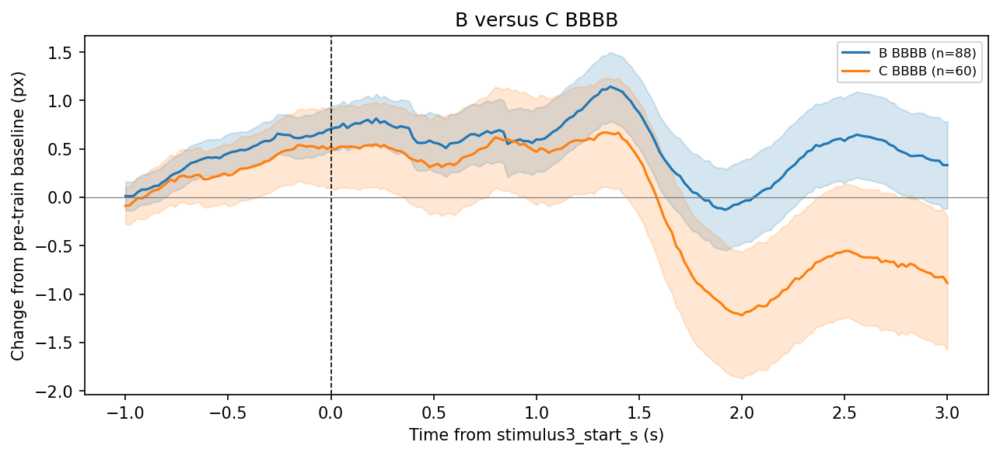


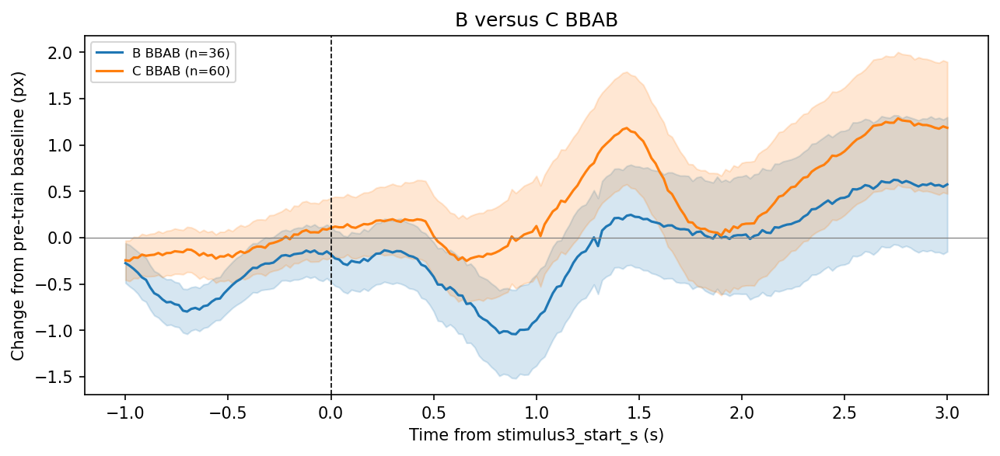

In [24]:
c=metrics.loc[metrics.block.eq('C')]
control_summaries=[]
if len(c):
    curves({seq:g for seq,g in c.groupby('sequence')},'C_four_sequences_stimulus3')
    for seq,g in c.groupby('sequence'):
        heatmap(g,f'C_{seq}_heatmap')
        fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True,constrained_layout=True)
        axes[0].scatter(g.block_trial,g.baseline_pd_px,s=10,color=COLORS[seq]);axes[0].set_ylabel('Baseline PD (px)')
        good=g.loc[g.primary_ok];axes[1].scatter(good.block_trial,good.primary_delta_px,s=10,color=COLORS[seq]);axes[1].set(ylabel='Primary ΔPD (px)',xlabel='Control block trial');finish_plot(f'C_{seq}_trial_trajectory')
        for key in [*STIM3_WINDOWS,'postend']:
            v=g.loc[g[key+'_ok'],key+'_delta_px'];control_summaries.append(dict(sequence=seq,metric=key,n=len(v),mean_delta_px=v.mean()))
for block,stdseq,devseq in [('A','AAAA','AABA'),('B','BBBB','BBAB')]:
    for seq in [stdseq,devseq]:
        g=metrics.loc[metrics.block.eq(block)&metrics.phase.eq('main')&metrics.sequence.eq(seq)]
        if seq==stdseq:g=g.loc[g.reference_standard]
        curves({f'{block} {seq}':g,f'C {seq}':c.loc[c.sequence.eq(seq)]},f'{block}_versus_C_{seq}')
pd.DataFrame(control_summaries).to_csv(analysis_dir/'C_sequence_window_summary.csv',index=False)
def session_contrasts(df):
    rows=[]
    for (mouse,sess),g in df.groupby(['mouse_id','session_id']):
        for key in [*STIM3_WINDOWS,'postend']:
            col=key+'_delta_px'
            for block,stdseq,devseq in [('A','AAAA','AABA'),('B','BBBB','BBAB')]:
                s=g.loc[g.block.eq(block)&g.reference_standard&g[key+'_ok'],col]
                d=g.loc[g.block.eq(block)&g.phase.eq('main')&g.sequence.eq(devseq)&g[key+'_ok'],col]
                cs=g.loc[g.block.eq('C')&g.sequence.eq(stdseq)&g[key+'_ok'],col]
                cd=g.loc[g.block.eq('C')&g.sequence.eq(devseq)&g[key+'_ok'],col]
                contrast=d.mean()-s.mean()
                rows.append(dict(mouse_id=mouse,session_id=sess,block=block,metric=key,n_standard=len(s),n_deviant=len(d),n_control_standard=len(cs),n_control_change=len(cd),standard_deviant_contrast_px=contrast,context_contrast_px=contrast-(cd.mean()-cs.mean()),identical_deviant_context_minus_C_px=d.mean()-cd.mean(),identical_standard_context_minus_C_px=s.mean()-cs.mean()))
    return pd.DataFrame(rows)
contrasts=session_contrasts(metrics);contrasts.to_csv(analysis_dir/'session_context_contrasts.csv',index=False);display(contrasts)

show_grouped_plots()


## II.12. Optional locomotion, licking and reward analyses (idea 13)

Behavior input must use the SAME DAQ reference as camera/train times. A CSV has `time_s,speed_cm_s`; supply calibrated speed, not raw encoder counts. No long gaps are bridged. Optional lick/reward analog channels are thresholded for rising edges using verified channel names and their TDMS clock offsets. These counts describe detector pulses, not automatically verified individual licks.

Classify trials using pre-train speed (to avoid conditioning primarily on movement caused by the stimulus). Compare baseline and primary responses in quiet/running strata, and scatter against pre-train speed. Post-train movement and licking may be part of the response, so their adjustment changes the scientific question. Rewarded inter-block gaps are plotted separately, not treated as resting baseline. Missing behavior is reported and leaves its analyses unavailable rather than labeling trials stationary.


In [25]:
behavior=None;behavior_events=pd.DataFrame(columns=['time_s','event_type'])
if BEHAVIOR_CSV is not None:
    behavior=pd.read_csv(BEHAVIOR_CSV)
    if not {'time_s','speed_cm_s'}.issubset(behavior):raise ValueError('Behavior CSV requires time_s,speed_cm_s.')
    behavior=behavior.sort_values('time_s')
    if not np.isfinite(behavior.time_s).all() or behavior.time_s.duplicated().any():raise ValueError('Invalid/duplicate behavior times.')
    bt=behavior.time_s.to_numpy(float);bv=behavior.speed_cm_s.to_numpy(float)
    for i,row in metrics.iterrows():
        for label,a,b in [('pre',row.train_start_s+BASELINE_TRAIN_S[0],row.train_start_s+BASELINE_TRAIN_S[1]),('response',row.stimulus3_start_s+1,row.stimulus3_start_s+2)]:
            v=bounded_sample(grid_between(a,b),bt,bv,BEHAVIOR_MAX_GAP_S)
            cov=np.isfinite(v).mean();metrics.at[i,label+'_speed_coverage']=cov
            metrics.at[i,label+'_speed_cm_s']=float(np.nanmean(np.abs(v))) if cov>=MIN_METRIC_COVERAGE else np.nan
    metrics['state']=np.where(metrics.pre_speed_cm_s.isna(),'unknown',np.where(metrics.pre_speed_cm_s>=RUNNING_THRESHOLD_CM_S,'running','quiet'))
    for block in ['A','B']:
        b=metrics.loc[metrics.block.eq(block)&metrics.phase.eq('main')&metrics.primary_ok&(metrics.reference_standard|metrics.is_deviant)]
        fig,ax=plt.subplots(figsize=(8,4))
        for seq,g in b.groupby('sequence'):ax.scatter(g.pre_speed_cm_s,g.primary_delta_px,s=13,label=seq,color=COLORS[seq])
        ax.set(xlabel='Mean absolute pre-train speed (cm/s)',ylabel='Primary ΔPD (px)',title=f'Block {block}: response and starting locomotion');ax.legend();finish_plot(f'{block}_locomotion_scatter')
        groups={state+' '+seq:g for (state,seq),g in b.loc[b.state.ne('unknown')].groupby(['state','sequence'])}
        curves(groups,f'{block}_locomotion_stratified')
else:print('Locomotion unavailable: set BEHAVIOR_CSV to enable state analyses.')
if LICK_CHANNEL is not None or REWARD_CHANNEL is not None:
    parts=[]
    with TdmsFile.open(str(ANALOG_TDMS_PATH)) as tdms:
        for kind,selector in [('lick',LICK_CHANNEL),('reward',REWARD_CHANNEL)]:
            if selector is None:continue
            channel=resolve_channel(tdms,selector);dt=channel_dt(channel.properties);offset,basis=event_channel_offset(channel.properties)
            values=np.asarray(channel[:],float)
            if not np.isfinite(values).all():raise ValueError(f'Nonfinite {kind} channel.')
            high=values>=BEHAVIOR_EVENT_THRESHOLD_V;rises=np.flatnonzero(~high[:-1]&high[1:])+1;keep=[]
            for sample in rises:
                if not keep or (sample-keep[-1])*dt>=BEHAVIOR_EVENT_MIN_SPACING_S:keep.append(int(sample))
            parts.append(pd.DataFrame({'time_s':offset+np.asarray(keep)*dt,'event_type':kind}))
    if parts:behavior_events=pd.concat(parts,ignore_index=True)
for kind in ['lick','reward']:
    times=behavior_events.loc[behavior_events.event_type.eq(kind),'time_s'].to_numpy(float)
    if not len(times):continue
    for i,row in metrics.iterrows():
        metrics.at[i,kind+'_pre_count']=int(((times>=row.train_start_s+BASELINE_TRAIN_S[0])&(times<row.train_start_s)).sum())
        metrics.at[i,kind+'_response_count']=int(((times>=row.train_start_s)&(times<=row.train_end_s+POSTEND_WINDOW_S[1])).sum())
    if kind=='reward':
        for j in range(len(runs)-1):
            prev=metrics.loc[metrics.block.eq(runs[j])].iloc[-1];nxt=metrics.loc[metrics.block.eq(runs[j+1])].iloc[0]
            a,b=prev.train_end_s,nxt.train_start_s;mask=(t>=a)&(t<=b)
            if not np.isfinite(y[mask]).any():continue
            fig,ax=plt.subplots(figsize=(10,3));ax.plot(t[mask]-a,y[mask],lw=.7)
            ax.vlines(times[(times>=a)&(times<=b)]-a,np.nanmin(y[mask]),np.nanmax(y[mask]),color='red',label='Reward pulse')
            ax.set(xlabel='Time since preceding block ended (s)',ylabel='Raw PD (px)',title='Inter-block gap: '+runs[j]+' → '+runs[j+1]);ax.legend();finish_plot(f'gap_{runs[j]}_{runs[j+1]}_reward')
if behavior is not None:
    state_summaries=[]
    for (block,state,seq),g in metrics.loc[metrics.primary_ok&metrics.phase.eq('main')].groupby(['block','state','sequence']):
        state_summaries.append(dict(block=block,state=state,sequence=seq,n=len(g),mean_primary_delta_px=g.primary_delta_px.mean(),mean_baseline_pd_px=g.baseline_pd_px.mean(),mean_pre_speed_cm_s=g.pre_speed_cm_s.mean()))
    pd.DataFrame(state_summaries).to_csv(analysis_dir/'locomotion_state_summary.csv',index=False)
behavior_events.to_csv(analysis_dir/'behavior_events.csv',index=False)
metrics.to_csv(OUTPUT_DIR/'trial_metrics.csv',index=False)

show_grouped_plots()


Locomotion unavailable: set BEHAVIOR_CSV to enable state analyses.


## II.13. Stricter tracking / interpolation sensitivity (idea 1)

Recompute the primary metric using only original, non-PCHIP-filled pupil measurements, with the same coverage requirement and without bridging excluded samples. This is a sensitivity comparison, not a replacement for manually checking blink boundaries or bad ellipse fits. Export per-trial and per-condition contrasts, including changes in accepted trial counts. A discrepancy between analyses can reflect altered trial selection as well as interpolation effects.


In [26]:
strict_metrics=metrics.copy();strict_py=py.copy();strict_py[pflag]=np.nan
for i,row in strict_metrics.iterrows():
    q=grid_between(row.train_start_s+BASELINE_TRAIN_S[0],row.train_start_s+BASELINE_TRAIN_S[1]);v=bounded_sample(q,pt,strict_py)
    base_ok=np.isfinite(v).mean()>=MIN_BASELINE_COVERAGE;base=np.nanmean(v) if np.isfinite(v).any() else np.nan
    q=grid_between(row.stimulus3_start_s+STIM3_WINDOWS['primary'][0],row.stimulus3_start_s+STIM3_WINDOWS['primary'][1]);r=bounded_sample(q,pt,strict_py)
    if np.isfinite(row.next_train_start_s):r[q>=row.next_train_start_s-NEXT_TRAIN_GUARD_S]=np.nan
    strict_metrics.at[i,'primary_ok']=bool(base_ok and np.isfinite(r).mean()>=MIN_METRIC_COVERAGE and (not np.isfinite(row.next_train_start_s) or q[-1]<row.next_train_start_s-NEXT_TRAIN_GUARD_S))
    strict_metrics.at[i,'primary_delta_px']=float(np.nanmean(r)-base) if np.isfinite(r).any() else np.nan
strict_metrics.to_csv(analysis_dir/'strict_original_only_trial_metrics.csv',index=False)
strict_contrasts=session_contrasts(strict_metrics).query("metric=='primary'")
strict_contrasts.to_csv(analysis_dir/'strict_original_only_primary_contrasts.csv',index=False)
display(strict_contrasts)


,mouse_id,session_id,block,metric,n_standard,n_deviant,n_control_standard,n_control_change,standard_deviant_contrast_px,context_contrast_px,identical_deviant_context_minus_C_px,identical_standard_context_minus_C_px
0,mouse_01,session_01,A,primary,88,36,60,60,-1.101442,-0.730774,-0.724445,0.006328
1,mouse_01,session_01,B,primary,88,36,60,60,-0.594076,-1.150083,-0.573140,0.576943


## II.14. Multi-session / mouse-level comparisons (idea 14)

One mouse is one independent unit. Add other exported `trial_metrics.csv` paths in settings. Session contrasts are averaged within mouse before across-mouse summaries. Trials are not pooled as independent animals. This implements paired mouse-level contrasts, bootstrap intervals by resampling mice, and two-sided Wilcoxon tests against zero when enough mice are available. All-zero contrasts have p=1. Benjamini–Hochberg adjustment is applied across the reported tested contrasts. Intervals and p-values are withheld below the configured minimum mouse count. Small cohorts still require cautious interpretation.

This section does not fit a full trial-level mixed model. Session/block order, baseline state and trial history remain possible explanatory variables; inspect their plots and exported table before interpreting contrasts. Secondary overlapping windows are reported separately, with multiplicity correction, rather than treated as independent evidence.


In [27]:
all_frames=[metrics]
for path in OTHER_SESSION_METRICS:
    other=pd.read_csv(path,dtype={'mouse_id':str,'session_id':str})
    required={'mouse_id','session_id','block','sequence','phase','reference_standard'}|{k+s for k in [*STIM3_WINDOWS,'postend'] for s in ['_delta_px','_ok']}
    if not required.issubset(other):raise ValueError(f'{path}: missing exported trial metric columns.')
    for col in ['reference_standard']+[k+'_ok' for k in [*STIM3_WINDOWS,'postend']]:
        flags=other[col].astype(str).str.lower()
        if not flags.isin(['true','false','1','0']).all():raise ValueError(f'Invalid boolean {col} in {path}')
        other[col]=flags.isin(['true','1'])
    if set(map(tuple,other[['mouse_id','session_id']].drop_duplicates().to_numpy())) & set(map(tuple,pd.concat(all_frames)[['mouse_id','session_id']].drop_duplicates().to_numpy())):raise ValueError('Duplicate mouse/session IDs across files.')
    all_frames.append(other)
all_metrics=pd.concat(all_frames,ignore_index=True)
all_contrasts=session_contrasts(all_metrics)
contrast_cols=['standard_deviant_contrast_px','context_contrast_px','identical_deviant_context_minus_C_px','identical_standard_context_minus_C_px']
mouse_values=all_contrasts.groupby(['mouse_id','block','metric'])[contrast_cols].mean().reset_index()
mouse_values.to_csv(analysis_dir/'mouse_level_contrasts.csv',index=False)
group_rows=[]
for (block,key),g in mouse_values.groupby(['block','metric']):
    for col in contrast_cols:
        v=g[col].dropna().to_numpy(float);n=len(v);lo=hi=pval=np.nan
        if n>=MIN_MICE_FOR_TEST:
            boot=np.mean(rng.choice(v,size=(BOOTSTRAP_REPETITIONS,n),replace=True),axis=1);lo,hi=np.quantile(boot,[.025,.975])
            pval=1.0 if np.allclose(v,0) else float(stats.wilcoxon(v,alternative='two-sided',zero_method='wilcox').pvalue)
        group_rows.append(dict(block=block,metric=key,contrast=col,n_mice=n,mean_px=v.mean() if n else np.nan,ci_low=lo,ci_high=hi,p_raw=pval))
group_results=pd.DataFrame(group_rows)
validp=group_results.p_raw.notna();pv=group_results.loc[validp,'p_raw'].to_numpy();q=np.full(len(pv),np.nan)
if len(pv):
    order=np.argsort(pv);adjust=np.minimum.accumulate((pv[order]*len(pv)/np.arange(1,len(pv)+1))[::-1])[::-1];q[order]=np.minimum(adjust,1)
group_results.loc[validp,'p_BH']=q
group_results.to_csv(analysis_dir/'group_mouse_level_results.csv',index=False)
display(group_results)
if mouse_values.mouse_id.nunique()<MIN_MICE_FOR_TEST:print('Descriptive contrasts only: insufficient independent mice for configured inferential tests.')


,block,metric,contrast,n_mice,mean_px,ci_low,ci_high,p_raw,p_BH
0,A,early,standard_deviant_contrast_px,1,-1.033873,NaN,NaN,NaN,NaN
1,A,early,context_contrast_px,1,-0.820412,NaN,NaN,NaN,NaN
2,A,early,identical_deviant_context_minus_C_px,1,-0.461133,NaN,NaN,NaN,NaN
3,A,early,identical_standard_context_minus_C_px,1,0.359279,NaN,NaN,NaN,NaN
4,A,late,standard_deviant_contrast_px,1,-1.165612,NaN,NaN,NaN,NaN
5,A,late,context_contrast_px,1,-1.171958,NaN,NaN,NaN,NaN
6,A,late,identical_deviant_context_minus_C_px,1,-0.919479,NaN,NaN,NaN,NaN
7,A,late,identical_standard_context_minus_C_px,1,0.252479,NaN,NaN,NaN,NaN
8,A,postend,standard_deviant_contrast_px,1,-1.238397,NaN,NaN,NaN,NaN
9,A,postend,context_contrast_px,1,-0.970599,NaN,NaN,NaN,NaN


Descriptive contrasts only: insufficient independent mice for configured inferential tests.


## II.15. Optional continuous-time overlap model (idea 15)

Enable `RUN_OVERLAP_MODEL=True` only after the preceding analyses. Fit a continuous pupil trace using overlapping stimulus-3 event kernels for each block/sequence, a shared train-onset kernel, a slow time trend, optional speed, and optional lick/reward kernels. Ridge regularization stabilizes correlated predictors. A fixed gamma-shaped kernel is an explicit modeling assumption, not an empirically proven mouse pupil response. Check kernel peak/duration and regularization sensitivity.

Fit on the first 80% of DAQ time and evaluate on the final 20%; report held-out RMSE relative to a constant training-mean prediction. Because Block C is last, some predictors may have little/no training support; those predictors are dropped and listed. The model can therefore fail to generalize across blocks. Rank/condition diagnostics are exported. Weights are descriptive conditional associations, not separate identifiable responses to all four tightly scheduled stimuli. No deconvolution significance claims are made.


In [28]:
if RUN_OVERLAP_MODEL:
    step=OVERLAP_GRID_STEP_S;grid=np.arange(pt[0],pt[-1]+step/4,step);target=bounded_sample(grid)
    lag=np.arange(0,OVERLAP_KERNEL_DURATION_S+step/4,step);shape=3.;scale=OVERLAP_KERNEL_PEAK_S/(shape-1)
    kernel=stats.gamma.pdf(lag,a=shape,scale=scale);kernel/=kernel.max()
    features={}
    def event_feature(times):
        impulses=np.zeros(len(grid));idx=np.rint((np.asarray(times)-grid[0])/step).astype(int);idx=idx[(idx>=0)&(idx<len(grid))]
        np.add.at(impulses,idx,1);return scipy_signal.fftconvolve(impulses,kernel,mode='full')[:len(grid)]
    for (block,seq),g in trials.groupby(['block','sequence']):features[block+'_'+seq]=event_feature(g.stimulus3_start_s)
    features['train_start']=event_feature(trials.train_start_s)
    features['slow_time']=(grid-grid[0])/max(grid[-1]-grid[0],1)
    if behavior is not None:features['speed_cm_s']=bounded_sample(grid,bt,bv,BEHAVIOR_MAX_GAP_S)
    for kind,g in behavior_events.groupby('event_type'):features[kind]=event_feature(g.time_s)
    names=list(features);X=np.column_stack([features[n] for n in names]);good=np.isfinite(target)&np.isfinite(X).all(axis=1)
    cutoff=grid[0]+.8*(grid[-1]-grid[0]);train=good&(grid<cutoff);test=good&(grid>=cutoff)
    if train.sum()<100 or test.sum()<20:raise ValueError('Insufficient continuous coverage for overlap model.')
    mean=X[train].mean(axis=0);sd=X[train].std(axis=0);keep=sd>1e-8
    dropped=[n for n,k in zip(names,keep) if not k];print('Dropped predictors with no training variation:',dropped)
    names=[n for n,k in zip(names,keep) if k];Z=(X[:,keep]-mean[keep])/sd[keep]
    design=np.column_stack([np.ones(len(grid)),Z]);D=design[train];response=target[train]
    condition=float(np.linalg.cond(D));rank=int(np.linalg.matrix_rank(D))
    penalty=np.eye(D.shape[1])*OVERLAP_RIDGE_ALPHA;penalty[0,0]=0
    weights=np.linalg.solve(D.T@D+penalty,D.T@response);pred=design@weights
    rmse=float(np.sqrt(np.mean((target[test]-pred[test])**2)));nullrmse=float(np.sqrt(np.mean((target[test]-response.mean())**2)))
    diagnostics={'n_train':int(train.sum()),'n_test':int(test.sum()),'rank':rank,'columns':D.shape[1],'condition_number':condition,'heldout_rmse_px':rmse,'constant_mean_rmse_px':nullrmse,'dropped_features':dropped,'kernel_peak_s':OVERLAP_KERNEL_PEAK_S,'kernel_duration_s':OVERLAP_KERNEL_DURATION_S,'ridge_alpha':OVERLAP_RIDGE_ALPHA}
    (analysis_dir/'overlap_model_diagnostics.json').write_text(json.dumps(diagnostics,indent=2));display(pd.Series(diagnostics).to_frame('value'))
    if rank<D.shape[1] or condition>1e5:print('Strong collinearity: do not interpret individual event coefficients as isolated physiological components.')
    pd.DataFrame({'feature':['intercept']+names,'coefficient_scaled_predictor':weights}).to_csv(analysis_dir/'overlap_model_weights.csv',index=False)
    pd.DataFrame({'time_s':grid,'observed_pd_px':target,'predicted_pd_px':pred,'heldout':test}).to_csv(analysis_dir/'overlap_model_predictions.csv',index=False)
    view=(grid>=cutoff)&(grid<=cutoff+120)
    fig,ax=plt.subplots(figsize=(12,4));ax.plot(grid[view],target[view],lw=.6,label='Observed');ax.plot(grid[view],pred[view],lw=1,label='Model');ax.set(xlabel='DAQ time (s)',ylabel='PD (px)',title='Held-out overlap model');ax.legend();finish_plot('overlap_model_heldout')
else:print('Overlap model disabled. Enable RUN_OVERLAP_MODEL after inspecting overlap and label/behavior quality.')

show_grouped_plots()


Overlap model disabled. Enable RUN_OVERLAP_MODEL after inspecting overlap and label/behavior quality.


## II.16. Export settings, summaries and interpretation checklist

A completed run saves camera QC, conditional frame mapping, joined pupil data, verified trial labels, trial metrics, phase/state/history plots, four-sequence control plots, context contrasts and multi-mouse results. Optional outputs appear only when their inputs/toggles are supplied. Figures and CSVs in the selected output folder are overwritten on rerun.

Before interpreting a condition difference: inspect raw/processed pupil tracking, baseline distributions and slopes, history sensitivity, movement differences, accepted counts, nominal versus observed stimulus timing, Block C order effects and the conditional camera alignment. A significant within-mouse trial difference is not animal-level replication. Selecting the largest-looking window after viewing condition differences requires independent validation.

### Scientific references and the relationship to this notebook

- Mathôt et al. (2018), *Safe and sensible preprocessing and baseline correction of pupil-size data*: subtractive baseline correction and baseline-artifact checks. https://doi.org/10.3758/s13428-017-1007-2
- Caldarelli et al. (2026), *Pupillometry and brain-wide c-Fos mapping uncover multimodal mirror emotional contagion related networks of mice*: pre-stimulus normalization, control-condition comparison, and a mean 1–2 s response metric. Its widely spaced shock events differ from these repeated visual trains. https://doi.org/10.1016/j.isci.2026.114827
- Gallimore et al. (2023), *Spatiotemporal dynamics across visual cortical laminae support a predictive coding framework for interpreting mismatch responses*: identical stimulus/context comparisons and visual oddball pupil constriction. https://doi.org/10.1093/cercor/bhad215
- Vinck et al. (2015), *Arousal and locomotion make distinct contributions to cortical activity patterns and visual encoding*: behavioral state and pupil measurements. https://doi.org/10.1016/j.neuron.2015.03.028
- Wierda et al. (2012), *Pupil dilation deconvolution reveals the dynamics of attention at high temporal resolution*: modeling overlap; human-derived kernels do not establish mouse component identifiability. https://doi.org/10.1073/pnas.1201858109

The particular trial windows, quality limits, running threshold and fixed-kernel settings here are editable analysis choices motivated by the schematic; they are not universally validated cutoffs.


In [29]:
settings_names=['PRE3_SLOPE_WINDOW_S','POST3_SLOPE_WINDOWS','GROUP_SIMILAR_PLOTS','PRE3_WINDOW_S','BASELINE_TRAIN_S','STIM3_WINDOWS','POSTEND_WINDOW_S','MIN_BASELINE_COVERAGE','MIN_METRIC_COVERAGE','MAX_BASELINE_INTERPOLATED_FRACTION','MAX_RESPONSE_INTERPOLATED_FRACTION','EXCLUDE_FIRST_N_STANDARDS_AFTER_DEVIANT','NEXT_TRAIN_GUARD_S','DEVIANT_TIMING_SOURCE','TRUE_SAVED_VIDEO_FRAMES','DIAMETER_COLUMN','TIME_COLUMN','RUNNING_THRESHOLD_CM_S','STRICT_PROTOCOL_COUNTS','RUN_OVERLAP_MODEL']
run_summary={'mouse_id':MOUSE_ID,'session_id':SESSION_ID,'trial_log':str(TRIAL_LOG_PATH),'trial_clock_basis':trial_clock_basis,'phase_basis':phase_basis,'block_order':runs,
 'n_trials':len(metrics),'n_primary_accepted':int(metrics.primary_ok.sum()),'n_postend_accepted':int(metrics.postend_ok.sum()),
 'camera_mapping_status':'conditional_end_anchor_startup_only_mismatch','leading_untimed_frames':leading_frames,'terminal_gap_override':terminal_override,
 'behavior_available':behavior is not None,'settings':{k:globals()[k] for k in settings_names}}
(OUTPUT_DIR/'complete_analysis_summary.json').write_text(json.dumps(run_summary,indent=2,default=str))
print('Complete analysis outputs:',OUTPUT_DIR.resolve());display(pd.Series(run_summary).to_frame('value'))


Complete analysis outputs: /Users/shuvrangshuguha/Downloads/basler_pupil_analysis


,value
mouse_id,mouse_01
session_id,session_01
trial_log,/Volumes/AG Poll 4/oddball2_exp_data/01_07_26/...
trial_clock_basis,DAQ_onset_ordinal_matched_to_JSON_oddball_trig...
phase_basis,log_phase_labels
block_order,"[B, A, C]"
n_trials,640
n_primary_accepted,639
n_postend_accepted,640
camera_mapping_status,conditional_end_anchor_startup_only_mismatch


In [30]:
print((OUTPUT_DIR / "block_analysis").resolve())

/Users/shuvrangshuguha/Downloads/basler_pupil_analysis/block_analysis
